<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento y Preparación de los Datos**
---

Este notebook es una plantilla que le puede servir como guía para el segundo entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**INGRESE SU RESPUESTA**---
2. ---**INGRESE SU RESPUESTA**---
3. ---**BRAYAN SEBASTIAN YEPES GARCIA 1015457884**---

## **1. Análisis Exploratorio de los Datos**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

#### Contexto: cómo se registra la votación en una mesa

Para interpretar los archivos es necesario conocer los formularios que diligencian los jurados de votación el día de la elección. Los dos principales son el E-11 y el E-14 (Registraduría Nacional del Estado Civil, s. f.).

**Formulario E-11: *Acta de instalación y registro general de votantes*.** Es la lista de las personas que votaron en la mesa. Los jurados registran en él a cada votante, con sus nombres, firma y huella. Al cerrar la votación, el número total de personas registradas es el número de **sufragantes** de la mesa: cuántas personas votaron realmente.

**Formulario E-14: *Acta de escrutinio de los jurados de votación*.** Es el acta donde los jurados anotan los **resultados de la mesa**: los votos de cada candidato y los votos en blanco, nulos y no marcados. Se diligencia en tres copias, cada una con un destino distinto:

| Copia del E-14 | Destino | Relación con los datos del proyecto |
|---|---|---|
| Transmisión | Se entrega al delegado del puesto para transmitir los resultados esa misma noche, con carácter informativo | Origen del **preconteo** |
| Claveros | Se guarda en un sobre y sirve de soporte a la comisión escrutadora | Base del **escrutinio**, el conteo oficial |
| Delegados | Se escanea y se publica en la página de la Registraduría | Consulta pública |

**Secuencia en la mesa.** El proceso sigue este orden:

1. **Votación:** cada votante queda registrado en el E-11.
2. **Nivelación:** al cerrar, los jurados comparan el número de votantes del E-11 con el número de votos de la urna. Si hay más votos que votantes, sacan al azar los votos sobrantes y los **incineran** sin abrirlos.
3. **Conteo:** los jurados cuentan los votos de cada candidato y los anotan en el E-14. Si un testigo lo solicita, pueden **recontar** los votos una sola vez.
4. **Escrutinio:** días después, las comisiones escrutadoras revisan las actas, resuelven reclamaciones y, si es necesario, recuentan votos o excluyen mesas. El resultado es el conteo oficial.

**Relación con las columnas de los archivos.**

| Columna | Qué registra | Etapa |
|---|---|---|
| `sufragantesSegunE11` (novedades) | Personas que votaron, según el E-11 | 1. Votación |
| `votosUrna` (novedades) | Votos encontrados al abrir la urna | 2. Nivelación |
| `votosIncinerados` (novedades) | Votos sobrantes destruidos en la nivelación | 2. Nivelación |
| `sufragantesE11SegunE14` (novedades) | Número de votantes del E-11, tal como se anotó en el E-14 | 3. Conteo |
| `recontadaJurados` (novedades) | Si los jurados recontaron los votos | 3. Conteo |
| Archivo de **preconteo** | Votos por candidato de la copia de transmisión del E-14 | 3. Conteo |
| `recontadaComision`, `excluida` (novedades) | Reconteo o exclusión por la comisión escrutadora | 4. Escrutinio |
| Archivo de **escrutinio** y `totalVotos` (novedades) | Votos por candidato después del escrutinio oficial | 4. Escrutinio |

En una mesa sin problemas, el E-11, los votos de la urna y el total del E-14 coinciden. Por eso, comparar estas cifras entre sí y con el preconteo permite identificar mesas con errores de registro o discrepancias.

Los formularios E-11 y E-14 son documentos físicos diligenciados en cada mesa y no forman parte del paquete de datos. Los archivos de preconteo y de novedades contienen únicamente valores digitados a partir de ellos; por eso, las inconsistencias encontradas pueden deberse tanto a errores en las actas como a errores de digitación, y no es posible distinguir entre ambos con los datos disponibles.

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

---**INGRESE SU RESPUESTA**---

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

---**INGRESE SU RESPUESTA**---

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

---**INGRESE SU RESPUESTA**---

### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

---**INGRESE SU RESPUESTA**---

## Preconteo

### Descripción y alcance del conjunto de datos

El presente análisis se desarrolla en el marco de la fase **Data Understanding** de la metodología CRISP-DM, utilizando los datos de preconteo correspondientes a la primera vuelta de las elecciones presidenciales de Colombia de 2026.

El objetivo de esta etapa es comprender la procedencia, estructura, contenido y características generales de los registros electorales antes de realizar procedimientos de preparación de datos o implementar algoritmos de Machine Learning.

El estudio se concentra en el archivo `PRE1v_MMV_9999_PRECONTEO.txt`, incluido en el paquete `MMV_Presidente1V_2026.zip`. Los demás archivos se consideran recursos documentales o auxiliares, según su función y pertinencia.

El análisis comprende:

- Identificación e inventario de las fuentes disponibles.
- Revisión de la documentación técnica oficial.
- Caracterización del formato y estructura de los registros.
- Verificación preliminar de integridad estructural.
- Identificación de patrones de codificación alfanumérica.
- Evaluación inicial de la viabilidad para construir un conjunto de datos analítico.

Esta etapa se limita a la comprensión de los datos originales. No se realizarán transformaciones irreversibles ni se interpretarán observaciones atípicas como evidencia de irregularidades electorales.

### Fuente de información e inventario de archivos

Los datos provienen de un paquete de información electoral atribuido a la Registraduría Nacional del Estado Civil de Colombia, que contiene registros de votación mesa a mesa, documentación técnica y archivos auxiliares.

Como actividad inicial de *Data Understanding*, se realiza un inventario de los recursos disponibles para identificar sus formatos, tamaños y funciones dentro del proyecto.

| Archivo | Formato | Función dentro del paquete |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Archivo principal de registros de preconteo |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | CSV | Archivo de escrutinio, excluido del alcance analítico |
| `Estructuras Basicas (1808).pdf` | PDF | Especificaciones de campos, tipos y longitudes |
| `HASH_PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Información de integridad del archivo de preconteo |
| `HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt` | TXT | Información de integridad del archivo de escrutinio |
| `ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip` | ZIP | Archivos auxiliares para interpretación de códigos |
| `Novedad20260603.zip` | ZIP | Archivos complementarios de novedades, pendientes de caracterización |

Los archivos originales se conservan en `data/raw/`, sin modificaciones.

El inventario programático permite verificar la existencia física de los recursos y registrar sus tamaños. La inspección del contenido de los archivos comprimidos auxiliares se realizará posteriormente, antes de utilizarlos como fuentes de referencia.

In [17]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)

PRECONTEO_PATH = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"

assert DATA_DIR.is_dir(), "No se encontró el directorio de datos."
assert PRECONTEO_PATH.is_file(), "No se encontró el archivo de preconteo."

inventario = []

for archivo in sorted(DATA_DIR.iterdir()):
    if archivo.is_file():
        inventario.append({
            "Archivo": archivo.name,
            "Formato": archivo.suffix.lower(),
            "Tamaño (MiB)": round(
                archivo.stat().st_size / 1024**2, 3
            ),
        })

df_inventario = pd.DataFrame(inventario)

display(df_inventario)

,Archivo,Formato,Tamaño (MiB)
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip,.zip,2.044
1,Estructuras Basicas (1808).pdf,.pdf,0.165
2,HASH_PRE1v_MMV_9999_PRECONTEO.txt,.txt,0.001
3,HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt,.txt,0.001
4,Novedad20260603.zip,.zip,2.020
5,PRE1v_MMV_9999_PRECONTEO.txt,.txt,56.439
6,_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv,.csv,100.541


### Documentación oficial y formato de almacenamiento

La interpretación del archivo de preconteo se fundamenta en el documento `Estructuras Basicas (1808).pdf`, incluido en el paquete electoral.

La documentación describe la organización de los archivos de votación mesa a mesa (MMV) y establece las características de almacenamiento de sus registros.

#### Formato de longitud fija

El archivo de preconteo utiliza una estructura de **ancho fijo (*fixed-width format*)**. A diferencia de un archivo CSV convencional, los campos no están separados por delimitadores, sino que ocupan posiciones predeterminadas dentro de cada registro.

La estructura documentada tiene una longitud de 38 caracteres, sin incluir los caracteres de terminación de línea.

Los registros finalizan con `CRLF`, correspondiente a retorno de carro y avance de línea.

Los campos numéricos utilizan longitudes definidas y pueden contener ceros a la izquierda. Por esta razón, los códigos administrativos deben conservarse inicialmente como cadenas de caracteres, evitando conversiones numéricas que alteren su representación.

#### Diccionario estructural de preconteo

| Campo oficial | Tipo | Longitud | Posiciones |
|---|---|---:|---|
| Código departamento | Numérico | 2 | 1–2 |
| Código municipio | Numérico | 3 | 3–5 |
| Zona | Alfanumérico | 2 | 6–7 |
| Puesto | Alfanumérico | 2 | 8–9 |
| Número de mesa | Numérico | 6 | 10–15 |
| Código JAL | Numérico | 2 | 16–17 |
| Número del comunicado | Numérico | 4 | 18–21 |
| Código de circunscripción | Numérico | 1 | 22 |
| Código de Lista o Partido | Numérico | 5 | 23–27 |
| Código de candidato | Numérico | 3 | 28–30 |
| Votos | Numérico | 8 | 31–38 |
| **Total** | | **38** | |

La documentación establece que el campo `Número del comunicado` tiene el valor `9999` para esta estructura.

#### Granularidad de los registros

Cada fila contiene información de identificación territorial y de mesa, junto con códigos electorales y una cantidad de votos.

En consecuencia, no debe suponerse que cada fila representa una mesa diferente. Una misma mesa puede estar asociada con múltiples registros electorales.

La identificación de una clave lógica y la definición de la unidad de análisis se realizarán después de cargar e inspeccionar los campos.

**Implicación metodológica:** cualquier agregación de votos por mesa o territorio deberá respetar la estructura documentada y las categorías electorales correspondientes.

### Inspección física de los registros

Antes de construir un DataFrame, se realiza una inspección directa del archivo original en modo binario.

Este procedimiento permite observar su representación física sin introducir supuestos sobre delimitadores, codificación o tipos de datos.

Se examinan los primeros registros y se verifica el tamaño del archivo. Posteriormente se analizará la consistencia de las longitudes, la presencia de registros vacíos y la duplicidad exacta.

La lectura en modo binario permite identificar explícitamente los caracteres de terminación de línea y preservar el contenido original durante la inspección.

In [18]:
print("Archivo:", PRECONTEO_PATH.name)
print("Existe:", PRECONTEO_PATH.exists())
print(
    "Tamaño (MiB):",
    round(PRECONTEO_PATH.stat().st_size / 1024**2, 2)
)

with PRECONTEO_PATH.open("rb") as archivo:
    for i in range(5):
        print(f"Registro {i + 1}:", repr(archivo.readline()))

Archivo: PRE1v_MMV_9999_PRECONTEO.txt
Existe: True
Tamaño (MiB): 56.44
Registro 1: b'01001010100000100999900000901100000027\r\n'
Registro 2: b'01001010100000100999900001501200000005\r\n'
Registro 3: b'01001010100000100999900002000600000001\r\n'
Registro 4: b'01001010100000100999900002101000000000\r\n'
Registro 5: b'01001010100000100999900002200800000000\r\n'


#### Resultados de la lectura preliminar

La inspección confirmó la existencia del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, con un tamaño aproximado de **56,44 MiB**.

Los cinco registros examinados presentan una secuencia de 38 caracteres, seguida por los caracteres de terminación `\r\n`.

El resultado es compatible con el formato de longitud fija descrito en la documentación técnica.

No se identificaron encabezados ni delimitadores convencionales en los registros inspeccionados. Por tanto, la lectura posterior deberá realizarse mediante posiciones de campos y no mediante separación por comas o puntos y coma.

Esta observación inicial no permite concluir que todos los registros cumplen el formato. Para ello se realiza una verificación sobre el archivo completo.

### Perfilamiento estructural del archivo completo

Se realiza un procedimiento de *structural data profiling* para evaluar las características físicas de todos los registros.

Se consideran cinco indicadores:

- **Número de registros:** volumen total de observaciones.
- **Longitud de registros:** consistencia con la estructura de 38 caracteres.
- **Registros vacíos:** presencia de líneas sin contenido.
- **Registros con caracteres no numéricos:** identificación preliminar de valores alfanuméricos.
- **Duplicados exactos:** frecuencia de líneas con contenido idéntico.

La presencia de caracteres no numéricos no se considera automáticamente un error, debido a que la documentación oficial define campos alfanuméricos.

Asimismo, la ausencia de duplicados exactos no garantiza la unicidad lógica de los registros electorales, dado que esta depende de la identificación de una clave apropiada.

In [19]:
from collections import Counter

longitudes = Counter()
registros_vacios = 0
registros_no_numericos = 0
duplicados_exactos = 0
registros_vistos = set()
total_registros = 0

with PRECONTEO_PATH.open("rb") as archivo:
    for linea in archivo:
        registro = linea.rstrip(b"\r\n")
        total_registros += 1

        longitudes[len(registro)] += 1

        if not registro:
            registros_vacios += 1

        if not registro.isdigit():
            registros_no_numericos += 1

        if registro in registros_vistos:
            duplicados_exactos += 1
        else:
            registros_vistos.add(registro)

resumen_estructura = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros de 38 caracteres",
        "Registros vacíos",
        "Registros con caracteres no numéricos",
        "Duplicados exactos"
    ],
    "Cantidad": [
        total_registros,
        longitudes[38],
        registros_vacios,
        registros_no_numericos,
        duplicados_exactos
    ]
})

resumen_estructura["Porcentaje"] = (
    100 * resumen_estructura["Cantidad"] / total_registros
)

display(resumen_estructura)
print("Distribución de longitudes:", dict(longitudes))

,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Distribución de longitudes: {38: 1479506}


#### Resultados del perfilamiento estructural

El análisis completo produjo los siguientes resultados:

| Indicador | Resultado |
|---|---:|
| Total de registros | 1.479.506 |
| Registros de 38 caracteres | 1.479.506 |
| Registros con longitud diferente | 0 |
| Registros vacíos | 0 |
| Registros con caracteres no numéricos | 12.517 |
| Registros duplicados exactos | 0 |

La totalidad de los registros presenta una longitud uniforme de 38 caracteres, lo que confirma la consistencia física del archivo respecto a la longitud establecida en la documentación.

No se identificaron registros vacíos ni líneas exactamente duplicadas.

Se encontraron **12.517 registros (aproximadamente 0,85 %)** con caracteres distintos de dígitos. Este resultado requiere examinar su ubicación dentro de la estructura antes de determinar si representa alguna inconsistencia.

En términos generales, el archivo presenta una estructura física homogénea. Sin embargo, la validación de los tipos de campos y de los códigos administrativos requiere comprobaciones adicionales.

### Validación de los campos según la documentación oficial

Una vez verificada la longitud de los registros, se contrasta su contenido con las restricciones establecidas en `Estructuras Basicas (1808).pdf`.

Esta validación examina:

- La longitud total de 38 caracteres.
- La composición numérica de los campos declarados como numéricos.
- La composición alfanumérica de los campos `Zona` y `Puesto`.
- El valor constante `9999` del campo `Número del comunicado`.

Esta comprobación evalúa el cumplimiento del esquema físico y de los tipos de datos documentados. No constituye todavía una validación completa de los dominios electorales, que requerirá consultar los archivos básicos auxiliares.

In [20]:
campos = [
    ("departamento", 2, "numerico"),
    ("municipio", 3, "numerico"),
    ("zona", 2, "alfanumerico"),
    ("puesto", 2, "alfanumerico"),
    ("mesa", 6, "numerico"),
    ("jal", 2, "numerico"),
    ("comunicado", 4, "numerico"),
    ("circunscripcion", 1, "numerico"),
    ("lista_partido", 5, "numerico"),
    ("candidato", 3, "numerico"),
    ("votos", 8, "numerico"),
]

assert sum(longitud for _, longitud, _ in campos) == 38

errores = Counter()
ejemplos_errores = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if len(registro) != 38:
            errores["longitud_incorrecta"] += 1
            continue

        inicio = 0

        for nombre, longitud, tipo in campos:
            valor = registro[inicio:inicio + longitud]
            inicio += longitud

            if tipo == "numerico":
                valido = valor.isdigit()
            else:
                valido = all(
                    48 <= c <= 57 or
                    65 <= c <= 90 or
                    97 <= c <= 122
                    for c in valor
                )

            if not valido:
                errores[f"tipo_invalido_{nombre}"] += 1

                if len(ejemplos_errores) < 10:
                    ejemplos_errores.append(
                        (numero_linea, nombre, repr(valor))
                    )

        if registro[17:21] != b"9999":
            errores["comunicado_incorrecto"] += 1

print("Inconsistencias por regla:", dict(errores))
print("Ejemplos:", ejemplos_errores)

Inconsistencias por regla: {}
Ejemplos: []


#### Interpretación de la validación estructural

La validación del esquema oficial permite determinar si los registros cumplen las restricciones de longitud, tipo de campo y valor constante del comunicado.

La ausencia de incumplimientos en estas comprobaciones indicaría que el archivo es estructuralmente compatible con el formato documentado por la Registraduría.

No obstante, esta validación no garantiza que todos los códigos de departamento, municipio, zona, puesto, partido o candidato correspondan a valores reconocidos en los catálogos oficiales.

La evaluación de esos dominios se realizará en la etapa de calidad de los datos, mediante el contraste con los archivos auxiliares disponibles.

### Caracterización de los campos alfanuméricos

Durante el perfilamiento inicial se identificaron 12.517 registros con caracteres diferentes de dígitos.

La documentación oficial establece que los campos `Zona` y `Puesto` son alfanuméricos. Por tanto, resulta necesario estudiar la ubicación y frecuencia de estos caracteres para verificar su correspondencia con las posiciones documentadas.

Se analizarán las frecuencias de cada carácter, sus posiciones dentro del registro y ejemplos de las observaciones identificadas.

Este procedimiento permite diferenciar características legítimas del formato de posibles inconsistencias de codificación.

In [21]:
caracteres = Counter()
posiciones = Counter()
ejemplos = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if not registro.isdigit():
            if len(ejemplos) < 10:
                ejemplos.append((
                    numero_linea,
                    registro.decode("ascii", errors="replace")
                ))

            for posicion, caracter in enumerate(registro, start=1):
                if not (48 <= caracter <= 57):
                    caracteres[chr(caracter)] += 1
                    posiciones[posicion] += 1

df_caracteres = pd.DataFrame(
    caracteres.items(),
    columns=["Carácter", "Frecuencia"]
).sort_values("Frecuencia", ascending=False)

df_posiciones = pd.DataFrame(
    posiciones.items(),
    columns=["Posición", "Frecuencia"]
).sort_values("Posición")

display(df_caracteres)
display(df_posiciones)

print("Ejemplos:")
for numero, registro in ejemplos:
    print(f"Línea {numero}: {registro}")

,Carácter,Frecuencia
0,A,6074
1,B,3941
2,C,524
3,D,448
4,E,192
22,W,144
14,P,116
17,R,102
24,Y,96
7,H,96


,Posición,Frecuencia
0,8,12517
1,9,16


Ejemplos:
Línea 79745: 0100199A100000100999900000901100000032
Línea 79746: 0100199A100000100999900001501200000009
Línea 79747: 0100199A100000100999900002000600000001
Línea 79748: 0100199A100000100999900002101000000000
Línea 79749: 0100199A100000100999900002200800000000
Línea 79750: 0100199A100000100999900002600100000029
Línea 79751: 0100199A100000100999900000099600000000
Línea 79752: 0100199A100000100999900000099700000002
Línea 79753: 0100199A100000100999900000099800000004
Línea 79754: 0100199A100000100999900100100300000001


#### Resultados de la caracterización alfanumérica

El análisis identificó 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos.

Se encontraron 26 letras mayúsculas diferentes. Las más frecuentes fueron `A` (6.074 apariciones) y `B` (3.941 apariciones).

Los caracteres se localizaron exclusivamente en las posiciones 8 y 9:

| Posición | Apariciones |
|---|---:|
| 8 | 12.517 |
| 9 | 16 |

De acuerdo con la estructura oficial, ambas posiciones pertenecen al campo `Puesto`, cuya longitud es de dos caracteres y cuyo tipo es alfanumérico.

Por consiguiente, la presencia de letras en estas posiciones **es compatible con la especificación del archivo y no representa por sí misma un error de calidad**.

Este resultado evidencia la importancia de conservar los códigos administrativos como cadenas de caracteres y utilizar la documentación técnica para interpretar los datos.

La validación de los códigos concretos de puesto frente a los catálogos oficiales permanece pendiente.

### Interpretación de un registro mediante las posiciones oficiales

Para ilustrar la estructura del archivo, se selecciona un registro real que contiene un código de puesto alfanumérico.

El registro se divide utilizando las longitudes establecidas en la documentación oficial. Este procedimiento permite observar cómo se encuentran representados los campos sin alterar los datos originales.

La segmentación también sirve como comprobación preliminar del procedimiento que se utilizará posteriormente para construir el DataFrame.

In [22]:
registro = "0100199A100000100999900000901100000032"

inicio = 0
segmentos = []

for nombre, longitud, tipo in campos:
    valor = registro[inicio:inicio + longitud]

    segmentos.append({
        "Campo": nombre,
        "Posición inicial": inicio + 1,
        "Posición final": inicio + longitud,
        "Valor": valor,
        "Tipo oficial": tipo,
    })

    inicio += longitud

df_segmentos = pd.DataFrame(segmentos)

display(df_segmentos)

,Campo,Posición inicial,Posición final,Valor,Tipo oficial
0,departamento,1,2,01,numerico
1,municipio,3,5,001,numerico
2,zona,6,7,99,alfanumerico
3,puesto,8,9,A1,alfanumerico
4,mesa,10,15,000001,numerico
5,jal,16,17,00,numerico
6,comunicado,18,21,9999,numerico
7,circunscripcion,22,22,0,numerico
8,lista_partido,23,27,00009,numerico
9,candidato,28,30,011,numerico


### Conclusiones de la caracterización estructural

La revisión documental y el análisis preliminar del archivo de preconteo permiten establecer los siguientes hallazgos:

- El archivo contiene **1.479.506 registros** de longitud fija, cada uno con 38 caracteres.
- No se identificaron registros vacíos ni duplicados exactos.
- La estructura observada es consistente con las longitudes especificadas en la documentación oficial.
- Los 12.517 registros que contienen caracteres alfabéticos presentan dichos caracteres en posiciones correspondientes al campo `Puesto`, definido como alfanumérico.
- Los registros contienen información territorial, identificadores electorales y cantidades de votos, pero todavía no se ha determinado la clave lógica que identifica cada observación.

En consecuencia, la inspección inicial proporciona evidencia favorable sobre la consistencia física del archivo, aunque todavía no permite concluir que los datos estén completamente libres de errores.

#### Aspectos pendientes

Para continuar con *Data Understanding* será necesario construir una representación tabular de los registros, identificar las categorías y dominios de cada campo, examinar los catálogos auxiliares y determinar la granularidad apropiada para el análisis electoral.

Estas actividades permitirán avanzar hacia el estudio de distribuciones, calidad de datos y relaciones entre variables, manteniendo la trazabilidad respecto de los archivos originales.

### Construcción de la representación tabular

Una vez comprobada la estructura física del archivo de preconteo, se procede a construir una representación tabular utilizando `pandas`.

La transformación consiste en segmentar cada registro de 38 caracteres según las posiciones y longitudes establecidas en la documentación oficial. Esta operación no modifica los archivos originales y permite analizar los campos de manera independiente.

Inicialmente, todas las variables se conservarán como cadenas de caracteres. Esta decisión es especialmente importante para los códigos administrativos y electorales, cuyos ceros iniciales forman parte de su representación.

Posteriormente, el campo `votos` se convertirá a un tipo entero, previa verificación de su composición numérica.

La construcción del DataFrame constituye una transformación de representación necesaria para la exploración, pero no implica todavía limpieza, eliminación de registros, agregación territorial ni ingeniería de características.

### Construcción y caracterización del conjunto de datos

Una vez verificada la estructura física del archivo de preconteo y su correspondencia con la documentación técnica, se procede a construir una representación tabular mediante la biblioteca `pandas`.

El objetivo de este procedimiento es identificar las dimensiones del

In [25]:
import pandas as pd

nombres_columnas = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
    "votos",
]

longitudes = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]

limites = [0]

for longitud in longitudes:
    limites.append(limites[-1] + longitud)

colspecs = list(zip(limites[:-1], limites[1:]))

df_preconteo = pd.read_fwf(
    PRECONTEO_PATH,
    colspecs=colspecs,
    names=nombres_columnas,
    dtype="string",
    header=None,
    keep_default_na=False,
)

assert len(df_preconteo) == total_registros
assert df_preconteo.shape[1] == 11

df_preconteo["votos"] = pd.to_numeric(
    df_preconteo["votos"],
    errors="raise",
).astype("int64")

print("Dimensiones:", df_preconteo.shape)
display(df_preconteo.head(10))

Dimensiones: (1479506, 11)


,departamento,municipio,zona,puesto,mesa,jal,comunicado,circunscripcion,lista_partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1
3,01,001,01,01,000001,00,9999,0,00021,010,0
4,01,001,01,01,000001,00,9999,0,00022,008,0
5,01,001,01,01,000001,00,9999,0,00026,001,30
6,01,001,01,01,000001,00,9999,0,00000,996,3
7,01,001,01,01,000001,00,9999,0,00000,997,0
8,01,001,01,01,000001,00,9999,0,00000,998,1
9,01,001,01,01,000001,00,9999,0,01001,003,0


### Verificación de la representación tabular

Después de cargar el archivo, se verifica que el número de observaciones coincida con el obtenido durante la inspección física y que la representación contenga los once campos establecidos en la documentación oficial.

También se revisan los primeros registros para comprobar que los valores fueron segmentados correctamente y que los códigos conservan su longitud y sus ceros iniciales.

El campo `votos` se representa como una cantidad entera, mientras que los demás campos permanecen como cadenas de caracteres.

Esta verificación es necesaria para evitar errores de interpretación que podrían propagarse a los análisis descriptivos y a las fases posteriores de Machine Learning.

### Caracterización de variables y cardinalidad

El análisis de variables permite identificar las características generales de los campos disponibles y evaluar su posible utilidad para el problema de investigación.

Se distinguen tres tipos conceptuales de variables:

- **Identificadores administrativos y electorales:** códigos que permiten localizar o relacionar registros, pero que no representan magnitudes cuantitativas.
- **Variables categóricas:** campos que identifican clases, agrupaciones o modalidades electorales.
- **Variables cuantitativas:** cantidades numéricas sobre las cuales pueden realizarse operaciones aritméticas, como el número de votos.

Se calculará la cardinalidad de cada variable, entendida como el número de valores distintos presentes en el conjunto de datos.

También se verificará la presencia de valores vacíos y la longitud de los códigos, como parte de la evaluación preliminar de completitud y consistencia.

Una cardinalidad elevada no constituye necesariamente un problema de calidad. En campos identificadores puede ser una característica esperada de su función.

In [27]:
perfil = []

for columna in df_preconteo.columns:
    serie = df_preconteo[columna]

    perfil.append({
        "Variable": columna,
        "Tipo pandas": str(serie.dtype),
        "Valores únicos": serie.nunique(dropna=True),
        "Valores nulos": serie.isna().sum(),
        "Valores vacíos": (
            serie.eq("").sum()
            if pd.api.types.is_string_dtype(serie)
            else 0
        ),
    })

df_perfil = pd.DataFrame(perfil)

display(df_perfil)

print("\nTipos de datos:")
df_preconteo.info(
    memory_usage="deep",
    show_counts=True
)

,Variable,Tipo pandas,Valores únicos,Valores nulos,Valores vacíos
0,departamento,string,34,0,0
1,municipio,string,309,0,0
2,zona,string,52,0,0
3,puesto,string,208,0,0
4,mesa,string,228,0,0
5,jal,string,1,0,0
6,comunicado,string,1,0,0
7,circunscripcion,string,1,0,0
8,lista_partido,string,14,0,0
9,candidato,string,16,0,0



Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1479506 entries, 0 to 1479505
Data columns (total 11 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   departamento     1479506 non-null  string
 1   municipio        1479506 non-null  string
 2   zona             1479506 non-null  string
 3   puesto           1479506 non-null  string
 4   mesa             1479506 non-null  string
 5   jal              1479506 non-null  string
 6   comunicado       1479506 non-null  string
 7   circunscripcion  1479506 non-null  string
 8   lista_partido    1479506 non-null  string
 9   candidato        1479506 non-null  string
 10  votos            1479506 non-null  int64 
dtypes: int64(1), string(10)
memory usage: 745.0 MB


### Identificación de la unidad de observación

Determinar la granularidad del conjunto de datos es indispensable para realizar análisis estadísticos válidos.

La documentación establece que los registros contienen identificadores territoriales, de mesa y de opciones electorales. Sin embargo, la presencia de un identificador de mesa no implica que exista una sola fila por mesa.

Se estudiará la cantidad de combinaciones únicas de departamento, municipio, zona, puesto y mesa, así como el número de registros asociados a cada combinación.

Adicionalmente, se examinará la unicidad de una clave compuesta que incluya los campos electorales disponibles. Esta comprobación permitirá identificar posibles registros repetidos a nivel lógico, sin asumir previamente que una combinación específica constituye una clave primaria definitiva.

La determinación de la granularidad será fundamental para evitar pseudorreplicación, agregaciones incorrectas y problemas de *data leakage* en etapas posteriores.

In [28]:
columnas_mesa = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
]

columnas_clave_candidata = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
]

total_mesas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

duplicados_clave = df_preconteo.duplicated(
    subset=columnas_clave_candidata
).sum()

registros_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa, dropna=False)
    .size()
    .rename("n_registros")
    .reset_index()
)

print(f"Registros totales: {len(df_preconteo):,}")
print(f"Combinaciones de mesa: {total_mesas:,}")
print(f"Duplicados de clave candidata: {duplicados_clave:,}")

print("\nDistribución de registros por mesa:")
display(
    registros_por_mesa["n_registros"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

Registros totales: 1,479,506
Combinaciones de mesa: 122,020
Duplicados de clave candidata: 0

Distribución de registros por mesa:


,n_registros
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
25%,8.000000
50%,13.000000
75%,16.000000
90%,16.000000
95%,16.000000
99%,16.000000


#### Resultados de la representación tabular y granularidad

La lectura del archivo de preconteo produjo un DataFrame de **1.479.506 observaciones y 11 variables**, coincidente con el volumen de registros identificado durante la inspección física.

Diez variables se conservaron como cadenas de caracteres (`string`), mientras que `votos` se representó mediante enteros de 64 bits (`int64`). Esta separación permite preservar los identificadores administrativos y realizar operaciones aritméticas sobre las cantidades de votos.

La representación tabular ocupa aproximadamente **745 MB de memoria**, según el cálculo de uso profundo de memoria de pandas.

Al examinar las combinaciones de departamento, municipio, zona, puesto y mesa, se identificaron **122.020 combinaciones distintas**, con un promedio aproximado de **12,13 registros por combinación**.

Esto confirma que la unidad de observación del archivo no corresponde a una mesa electoral única, sino a registros más detallados asociados con mesas y códigos electorales.

Adicionalmente, no se encontraron duplicados bajo la clave compuesta candidata que incluye los identificadores territoriales, de mesa y de opción electoral.

**Implicación metodológica**

La ausencia de duplicados bajo esta clave constituye evidencia favorable sobre la unicidad de los registros, pero no demuestra por sí sola que la clave sea la definición oficial de identificación.

Antes de construir variables agregadas por mesa, será necesario comprender los códigos electorales, verificar los catálogos auxiliares y estudiar la distribución de registros por mesa.

### Distribución de registros por mesa electoral

Una vez identificadas las combinaciones únicas de mesa, se analiza el número de registros asociados a cada una.

Este análisis permite estudiar la heterogeneidad de la representación de las mesas dentro del archivo de preconteo e identificar posibles diferencias en la cantidad de registros electorales asociados a ellas.

Se calcularán medidas de tendencia central y dispersión, incluyendo media, mediana, desviación estándar, valores extremos y cuantiles.

Posteriormente, se utilizarán un histograma y un diagrama de caja (*boxplot*) para examinar la distribución.

Es importante señalar que una cantidad inusual de registros por mesa no constituye automáticamente una anomalía electoral. Su interpretación requiere conocer las reglas de generación de registros y las categorías electorales incluidas.

,Registros por mesa
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
1%,4.000000
5%,6.000000
25%,8.000000
50%,13.000000
75%,16.000000
95%,16.000000


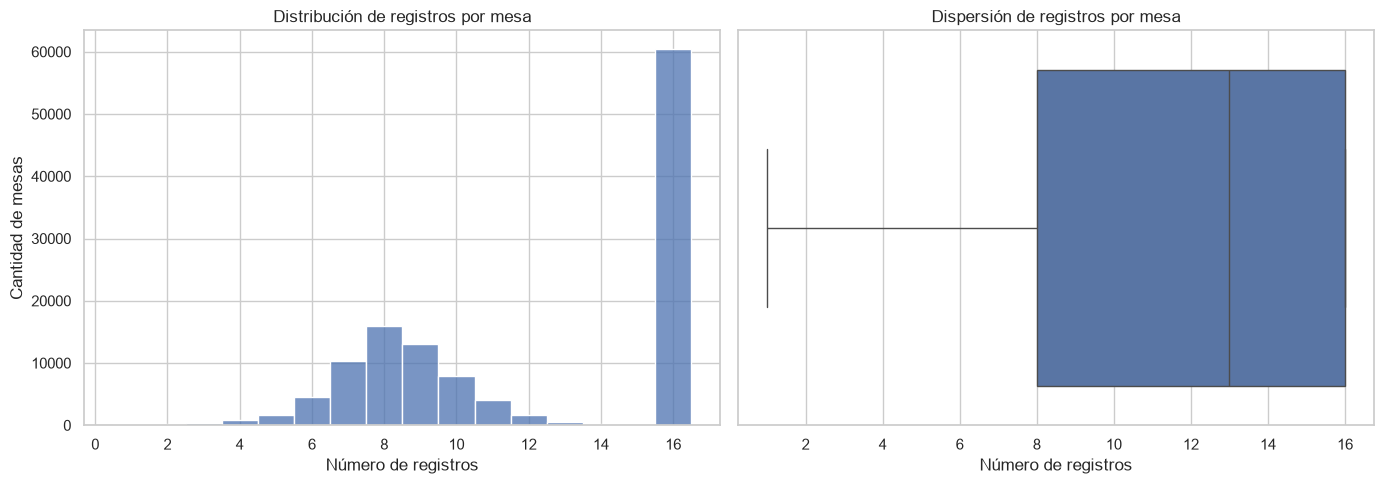

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

conteos = registros_por_mesa["n_registros"]

display(
    conteos.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("Registros por mesa")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    conteos,
    discrete=True,
    ax=axes[0],
)

axes[0].set_title("Distribución de registros por mesa")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Cantidad de mesas")

sns.boxplot(
    x=conteos,
    ax=axes[1],
)

axes[1].set_title("Dispersión de registros por mesa")
axes[1].set_xlabel("Número de registros")

plt.tight_layout()
plt.show()

#### Interpretación de la distribución de registros por mesa

El conjunto de preconteo contiene 122.020 combinaciones únicas de mesa electoral, con un promedio de 12,13 registros por mesa y una desviación estándar de 4,06.

La mediana es de 13 registros, mientras que el primer y tercer cuartil corresponden a 8 y 16 registros, respectivamente. Esto indica que la mitad central de las mesas presenta entre 8 y 16 registros.

Se observa un mínimo de 1 registro y un máximo de 16. Además, los percentiles 75, 95 y 99 coinciden en 16 registros, lo cual evidencia una concentración de observaciones en la parte superior de la distribución.

Estos resultados confirman que el número de registros asociados a cada mesa es variable. Sin embargo, esta variabilidad no puede interpretarse directamente como una inconsistencia, dado que todavía no se han caracterizado completamente los códigos de candidato, lista y las reglas de inclusión de registros.

La distribución observada constituye un punto de partida para investigar la estructura electoral de los registros y determinar la unidad de análisis apropiada para etapas posteriores.

### Frecuencia de registros por mesa y composición electoral

Para profundizar en la granularidad del conjunto de datos, se examina la frecuencia de mesas según su número de registros y se comparan los códigos electorales presentes en mesas con diferentes cantidades de observaciones.

Este análisis busca identificar patrones de representación asociados a los campos `lista_partido`, `candidato` y `circunscripcion`.

El propósito es establecer si las diferencias observadas en el número de registros por mesa se relacionan con la composición de las opciones electorales registradas.

No se asumirá que la ausencia de un código equivale a cero votos hasta verificar las reglas de generación del archivo.

In [30]:
frecuencias = (
    registros_por_mesa["n_registros"]
    .value_counts()
    .sort_index()
    .rename_axis("Registros por mesa")
    .reset_index(name="Cantidad de mesas")
)

frecuencias["Porcentaje"] = (
    100 * frecuencias["Cantidad de mesas"] / total_mesas
).round(2)

display(frecuencias)

,Registros por mesa,Cantidad de mesas,Porcentaje
0,1,167,0.14
1,2,228,0.19
2,3,412,0.34
3,4,832,0.68
4,5,1720,1.41
5,6,4514,3.70
6,7,10247,8.40
7,8,15954,13.07
8,9,13012,10.66
9,10,7906,6.48


In [31]:
# Cardinalidad y valores más frecuentes de códigos electorales
for columna in [
    "circunscripcion",
    "lista_partido",
    "candidato",
    "jal",
    "comunicado",
]:
    print(f"\n{columna}")
    print("Valores distintos:", df_preconteo[columna].nunique())

    display(
        df_preconteo[columna]
        .value_counts()
        .head(20)
        .to_frame("Frecuencia")
    )


circunscripcion
Valores distintos: 1


,Frecuencia
circunscripcion,
0,1479506



lista_partido
Valores distintos: 14


,Frecuencia
lista_partido,
00000,302867
00026,121967
01003,121597
00009,120346
00015,117646
01004,106109
01001,102972
03001,78894
00020,73312



candidato
Valores distintos: 16


,Frecuencia
candidato,
001,121967
004,121597
011,120346
012,117646
996,117243
997,109397
002,106109
003,102972
005,78894



jal
Valores distintos: 1


,Frecuencia
jal,
00,1479506



comunicado
Valores distintos: 1


,Frecuencia
comunicado,
9999,1479506


#### Resultados de la caracterización de códigos electorales

El análisis de frecuencias identificó una estructura heterogénea en el número de registros asociados a cada mesa electoral.

De las 122.020 combinaciones de mesa, 60.397 presentan exactamente 16 registros, equivalentes al 49,50 % del total. Las demás combinaciones presentan entre 1 y 15 registros.

En cuanto a los campos electorales, se identificaron 14 valores distintos en `lista_partido` y 16 en `candidato`. Esta cardinalidad sugiere una estructura de registros asociada con un conjunto limitado de opciones electorales.

Adicionalmente, las variables `circunscripcion`, `jal` y `comunicado` presentan un único valor en todas las observaciones. Por tanto, no contienen variabilidad que pueda utilizarse directamente como información predictiva dentro de este archivo.

La presencia de códigos especiales como `996`, `997` y `998` requiere una interpretación respaldada por los archivos oficiales auxiliares.

Finalmente, aunque el máximo de registros por mesa coincide con la cardinalidad del campo `candidato`, es necesario examinar las combinaciones entre `lista_partido` y `candidato` antes de establecer la granularidad electoral definitiva.

### Relación entre códigos de lista y candidato

Para comprender la organización de los registros electorales, se estudia la relación entre los campos `lista_partido` y `candidato`.

El análisis busca identificar las combinaciones distintas de ambos códigos y determinar si existe una correspondencia estable entre ellos.

También se verificará si una misma mesa contiene registros repetidos para una combinación electoral específica.

Esta evaluación permitirá avanzar en la identificación de la clave lógica del conjunto de datos y establecer una base para futuras agregaciones.

Los resultados describirán las relaciones observadas entre códigos, sin atribuirles todavía nombres de candidatos o categorías de votación no confirmados documentalmente.

In [32]:
combinaciones_electorales = (
    df_preconteo
    .groupby(
        ["lista_partido", "candidato"],
        dropna=False
    )
    .agg(
        registros=("votos", "size"),
        mesas_con_registro=("mesa", "size")
    )
    .reset_index()
    .drop(columns="mesas_con_registro")
    .sort_values(
        ["lista_partido", "candidato"]
    )
)

print(
    "Combinaciones electorales distintas:",
    len(combinaciones_electorales)
)

display(combinaciones_electorales)

Combinaciones electorales distintas: 16


,lista_partido,candidato,registros
0,00000,996,117243
1,00000,997,109397
2,00000,998,76227
3,00009,011,120346
4,00015,012,117646
5,00020,006,73312
6,00021,010,63261
7,00022,008,67626
8,00026,001,121967
9,01001,003,102972


In [33]:
clave_mesa_opcion = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "lista_partido",
    "candidato",
]

duplicados_mesa_opcion = df_preconteo.duplicated(
    subset=clave_mesa_opcion,
    keep=False
)

print(
    "Registros con combinación mesa-opción repetida:",
    duplicados_mesa_opcion.sum()
)

if duplicados_mesa_opcion.any():
    display(
        df_preconteo.loc[
            duplicados_mesa_opcion,
            clave_mesa_opcion + ["votos"]
        ].sort_values(clave_mesa_opcion).head(20)
    )

Registros con combinación mesa-opción repetida: 0


In [34]:
opciones_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        registros=("votos", "size"),
        candidatos_distintos=("candidato", "nunique"),
        listas_distintas=("lista_partido", "nunique"),
    )
    .reset_index()
)

display(
    opciones_por_mesa[
        [
            "registros",
            "candidatos_distintos",
            "listas_distintas"
        ]
    ].describe()
)

print(
    "Mesas donde registros != candidatos distintos:",
    (
        opciones_por_mesa["registros"]
        != opciones_por_mesa["candidatos_distintos"]
    ).sum()
)

,registros,candidatos_distintos,listas_distintas
count,122020.000000,122020.000000,122020.000000
mean,12.125111,12.125111,10.626619
std,4.055918,4.055918,3.517905
min,1.000000,1.000000,1.000000
25%,8.000000,8.000000,7.000000
50%,13.000000,13.000000,11.000000
75%,16.000000,16.000000,14.000000
max,16.000000,16.000000,14.000000


Mesas donde registros != candidatos distintos: 0


In [35]:
clave_registro = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "candidato",
]

### Identificación de la granularidad electoral

El análisis de las combinaciones entre `lista_partido` y `candidato` identificó 16 opciones electorales distintas en el archivo de preconteo.

Se verificó que cada combinación de mesa y opción electoral aparece como máximo una vez. Asimismo, para las 122.020 combinaciones únicas de mesa, el número de registros coincide exactamente con la cantidad de códigos de candidato distintos.

Estos resultados permiten caracterizar la unidad de observación como un **registro de votos asociado a una opción electoral específica dentro de una mesa**.

En consecuencia, la combinación de departamento, municipio, zona, puesto, mesa y candidato constituye una clave lógica única observada para este conjunto de datos.

La distribución del número de opciones registradas por mesa no es uniforme: 60.397 mesas, equivalentes al 49,50 %, contienen las 16 opciones identificadas, mientras que las restantes presentan entre 1 y 15.

La ausencia de determinadas opciones en una mesa no debe interpretarse automáticamente como un error o como un valor de cero votos. Para determinar su significado será necesario contrastar las reglas de generación de registros con la documentación electoral.

Esta caracterización establece una base para la construcción posterior de una representación a nivel de mesa, apropiada para estudiar distribuciones de votación y desarrollar métodos de detección de anomalías.

### Presencia de opciones electorales y registros con cero votos

La identificación de 16 opciones electorales permite investigar la completitud de las combinaciones mesa-opción.

Aunque todas las opciones aparecen en el conjunto de datos, no todas están representadas en cada mesa. Adicionalmente, la inspección inicial confirma que existen registros explícitos con cero votos.

Por tanto, es necesario distinguir entre dos situaciones:

- Una opción electoral presente en una mesa con `votos = 0`.
- Una opción electoral sin registro asociado a esa mesa.

Estas situaciones son distintas desde el punto de vista de la representación de los datos y no deben equipararse sin una justificación documental.

Se calculará la frecuencia de aparición de cada opción electoral, la proporción de registros con cero votos y el número de mesas donde cada opción no aparece.

El análisis permitirá identificar patrones de representación y formular hipótesis sobre la estructura del archivo, sin atribuir automáticamente las ausencias a errores de captura o a resultados electorales nulos.

In [36]:
resumen_opciones = (
    df_preconteo
    .groupby(["lista_partido", "candidato"])
    .agg(
        mesas_presentes=("votos", "size"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
        votos_minimos=("votos", "min"),
        votos_maximos=("votos", "max"),
        votos_mediana=("votos", "median"),
    )
    .reset_index()
)

resumen_opciones["mesas_ausentes"] = (
    total_mesas - resumen_opciones["mesas_presentes"]
)

resumen_opciones["porcentaje_presencia"] = (
    100 * resumen_opciones["mesas_presentes"] / total_mesas
).round(2)

resumen_opciones["porcentaje_ceros"] = (
    100
    * resumen_opciones["registros_cero"]
    / resumen_opciones["mesas_presentes"]
).round(2)

display(
    resumen_opciones.sort_values(
        "porcentaje_presencia",
        ascending=False
    )
)

,lista_partido,candidato,mesas_presentes,registros_cero,votos_minimos,votos_maximos,votos_mediana,mesas_ausentes,porcentaje_presencia,porcentaje_ceros
8,00026,001,121967,100,0,325,75.0,53,99.96,0.08
11,01003,004,121597,260,0,694,77.0,423,99.65,0.21
3,00009,011,120346,4255,0,139,10.0,1674,98.63,3.54
4,00015,012,117646,9046,0,98,6.0,4374,96.42,7.69
0,00000,996,117243,10113,0,70,3.0,4777,96.09,8.63
1,00000,997,109397,22753,0,111,2.0,12623,89.65,20.80
12,01004,002,106109,34606,0,245,1.0,15911,86.96,32.61
9,01001,003,102972,23425,0,179,1.0,19048,84.39,22.75
15,03001,005,78894,46567,0,136,0.0,43126,64.66,59.02
2,00000,998,76227,47450,0,227,0.0,45793,62.47,62.25


In [37]:
resumen_mesas = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        opciones_presentes=("candidato", "nunique"),
        suma_votos_registrados=("votos", "sum"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
    )
    .reset_index()
)

resumen_por_cantidad_opciones = (
    resumen_mesas
    .groupby("opciones_presentes")
    .agg(
        cantidad_mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        promedio_votos=("suma_votos_registrados", "mean"),
        mediana_ceros=("registros_cero", "median"),
    )
    .reset_index()
)

display(resumen_por_cantidad_opciones)

,opciones_presentes,cantidad_mesas,mediana_votos,promedio_votos,mediana_ceros
0,1,167,50.0,67.688623,0.0
1,2,228,37.0,63.486842,0.0
2,3,412,31.0,54.361650,0.0
3,4,832,41.0,65.704327,0.0
4,5,1720,96.0,117.150581,0.0
5,6,4514,178.0,173.283784,0.0
6,7,10247,203.0,198.128428,0.0
7,8,15954,219.0,215.397894,0.0
8,9,13012,230.0,226.909007,0.0
9,10,7906,239.0,235.633443,0.0


#### Interpretación de la presencia de opciones electorales y los registros con cero votos

El análisis de las 16 opciones electorales evidencia diferencias considerables en su frecuencia de aparición dentro de las 122.020 combinaciones de mesa.

La opción identificada mediante el código `001` presenta la mayor cobertura, con registros en el 99,96 % de las mesas. Por el contrario, la opción `010` aparece en el 51,84 % de las mesas.

También se observa una relación descriptiva entre la frecuencia de aparición de las opciones y la proporción de registros con cero votos. Algunas opciones con menor cobertura presentan porcentajes de cero superiores al 80 %, mientras que las opciones de mayor presencia registran proporciones considerablemente menores.

Por otra parte, las mesas con 16 opciones presentan una mediana de nueve registros con cero votos, mientras que las mesas con entre una y catorce opciones presentan una mediana de cero.

Este contraste sugiere que la representación de opciones electorales podría responder a diferentes reglas de inclusión de registros. Sin embargo, los resultados no permiten determinar por sí solos cuáles son dichas reglas.

La relación entre el número de opciones presentes y la suma de votos registrados tampoco es estrictamente creciente. Las mesas con 16 opciones presentan una mediana de 188 votos, inferior a la observada en varios grupos con menos opciones.

Estos hallazgos justifican una investigación adicional sobre la estructura de los registros, particularmente sobre la coexistencia de valores explícitos de cero y opciones ausentes.

Las diferencias observadas no deben interpretarse como anomalías electorales sin verificar previamente la documentación y los mecanismos de producción del archivo.

### Análisis de patrones de presencia y ausencia de opciones electorales

El archivo de preconteo presenta una estructura de hasta 16 opciones electorales por mesa, pero no todas las opciones aparecen en todas las mesas.

Adicionalmente, los resultados muestran que existen registros explícitos con cero votos y diferencias considerables en la cantidad de opciones registradas.

Para profundizar en este comportamiento, se construirá una matriz binaria de presencia de opciones electorales por mesa.

Cada fila representará una combinación única de mesa y cada columna una opción electoral. El valor uno indicará que existe un registro para esa opción, mientras que el valor cero indicará que no existe una fila correspondiente en el archivo original.

Esta matriz describe exclusivamente la presencia de registros y no debe confundirse con una matriz de votos. En particular, una ausencia de registro no se interpretará como cero votos.

In [38]:
matriz_presencia = (
    df_preconteo
    .assign(presente=1)
    .pivot_table(
        index=columnas_mesa,
        columns="candidato",
        values="presente",
        aggfunc="max",
        fill_value=0
    )
    .astype("int8")
)

print("Dimensiones:", matriz_presencia.shape)

display(matriz_presencia.head())

Dimensiones: (122020, 16)


candidato                                  001  002  003  004  005  006  007  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  008  009  010  011  012  013  996  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  997  998  
departamento municipio zona puesto mesa              
01           001       01   01     000001    1    1  
                                   000002    1    1  
                                   000003    1    1  
                                   000004    1    1  
                                   000005    1    1

In [39]:
patrones = (
    matriz_presencia
    .value_counts()
    .rename("cantidad_mesas")
    .reset_index()
    .sort_values("cantidad_mesas", ascending=False)
)

patrones["porcentaje"] = (
    100 * patrones["cantidad_mesas"] / total_mesas
).round(2)

print("Patrones distintos:", len(patrones))

display(patrones.head(15))

Patrones distintos: 2766


,001,002,003,004,005,006,007,008,009,010,011,012,013,996,997,998,cantidad_mesas,porcentaje
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,60397,49.50
1,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,0,7263,5.95
2,1,0,1,1,0,0,0,0,0,0,1,1,0,1,1,0,2559,2.10
3,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,2549,2.09
4,1,1,0,1,0,0,0,0,0,0,1,1,0,1,1,0,2105,1.73
5,1,1,1,1,0,0,0,0,0,0,1,1,0,1,0,0,1702,1.39
6,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,1,1443,1.18
7,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1377,1.13
8,1,1,1,1,0,1,0,0,0,0,1,1,0,1,1,0,1193,0.98
9,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,0,864,0.71


In [40]:
comparacion = (
    resumen_mesas
    .assign(
        grupo=lambda x: np.where(
            x["opciones_presentes"] == 16,
            "16 opciones",
            "Menos de 16 opciones"
        )
    )
    .groupby("grupo")
    .agg(
        mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        mediana_ceros=("registros_cero", "median"),
        promedio_ceros=("registros_cero", "mean")
    )
)

display(comparacion)

,mesas,mediana_votos,mediana_ceros,promedio_ceros
grupo,,,,
16 opciones,60397,188.0,9.0,8.656986
Menos de 16 opciones,61623,220.0,0.0,0.074079


### Identificación de catálogos y archivos auxiliares

El análisis estructural permitió identificar 16 combinaciones únicas de códigos electorales, definidas mediante los campos `lista_partido` y `candidato`.

Sin embargo, los códigos numéricos no permiten establecer por sí solos la identidad de los candidatos, las organizaciones políticas o las categorías especiales de votación.

Para avanzar en la comprensión semántica del conjunto de datos, se examinarán los archivos auxiliares incluidos en el paquete de información electoral.

El propósito de esta exploración es identificar los catálogos que permitan relacionar los códigos observados con sus respectivas descripciones oficiales, así como reconocer posibles reglas de codificación relevantes para interpretar los registros del preconteo.

Esta actividad corresponde a la descripción y exploración de los datos dentro de CRISP-DM. No se realizarán todavía transformaciones destinadas al entrenamiento de modelos.

In [41]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

ruta_catalogos = (
    DATA_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip"
)

assert ruta_catalogos.exists(), (
    f"No se encontró el archivo: {ruta_catalogos}"
)

with ZipFile(ruta_catalogos, "r") as zip_file:
    archivos_catalogos = [
        {
            "archivo": info.filename,
            "extension": Path(info.filename).suffix.lower(),
            "tamano_kib": round(info.file_size / 1024, 2),
        }
        for info in zip_file.infolist()
        if not info.is_dir()
    ]

df_catalogos = pd.DataFrame(archivos_catalogos)

print("Total de archivos:", len(df_catalogos))

display(
    df_catalogos.sort_values("archivo").reset_index(drop=True)
)

Total de archivos: 7


,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/D...,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/H...,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/I...,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/P...,.txt,2.63


In [42]:
terminos = [
    "candidato",
    "partido",
    "lista",
    "presidente",
    "codigo",
    "diccionario",
    "voto",
    "opcion",
]

if not df_catalogos.empty:
    patron = "|".join(terminos)

    posibles_catalogos = df_catalogos[
        df_catalogos["archivo"].str.contains(
            patron,
            case=False,
            na=False,
            regex=True
        )
    ]

    display(posibles_catalogos)

,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/D...,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/H...,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/I...,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/P...,.txt,2.63


In [44]:
for i, archivo in enumerate(df_catalogos["archivo"], start=1):
    print(f"{i}. {archivo}")

1. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
2. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
3. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
4. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT
5. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt
6. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT
7. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT


In [45]:
with ZipFile(ruta_catalogos, "r") as zip_file:
    for nombre in zip_file.namelist():
        if nombre.endswith("/"):
            continue

        print("\n" + "=" * 80)
        print("ARCHIVO:", nombre)
        print("=" * 80)

        with zip_file.open(nombre) as archivo:
            for _, linea in zip(range(5), archivo):
                print(linea.decode("latin-1").rstrip())


ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01
00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03
00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04
00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05
00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
0NACIONAL

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
001PRESIDENCIA Y VICEP

### Exploración semántica de los catálogos electorales

La inspección de los archivos auxiliares permitió identificar catálogos de candidatos, partidos políticos, circunscripciones, corporaciones, división político-administrativa e indicadores de mesas.

Estos archivos complementan la estructura del preconteo al proporcionar descripciones asociadas con los códigos utilizados en sus registros.

El catálogo de circunscripciones identifica el código `0` como `NACIONAL`, mientras que el catálogo de corporaciones contiene la denominación `PRESIDENCIA Y VICEPRESIDENCIA`.

Para interpretar las opciones electorales se examinarán los catálogos de candidatos y partidos, verificando sus estructuras antes de establecer correspondencias con los códigos presentes en el preconteo.

La información territorial de DIVIPOL y los indicadores de mesas se reservarán para una exploración posterior de las diferencias geográficas y operativas.

In [46]:
with ZipFile(ruta_catalogos, "r") as zip_file:

    for tipo in ["CANDIDATOS_", "PARTIDOS_"]:

        nombre = next(
            n for n in zip_file.namelist()
            if Path(n).name.upper().startswith(tipo)
        )

        contenido = zip_file.read(nombre).decode("latin-1")
        lineas = contenido.splitlines()

        print(f"\n{'=' * 70}")
        print(f"CATÁLOGO: {tipo}")
        print(f"Archivo: {nombre}")
        print(f"Registros: {len(lineas)}")

        print(
            "Longitudes observadas:",
            sorted(set(map(len, lineas)))
        )

        print("\nRegistros:")
        for linea in lineas[:25]:
            print(repr(linea))


CATÁLOGO: CANDIDATOS_
Archivo: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
Registros: 13
Longitudes observadas: [138]

Registros:
'00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01'
'00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03'
'00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04'
'00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05'
'00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06'
'00100000000000200061MIGUEL                                            URIBE LONDOÑO                                     8319134 

### Interpretación de los códigos de candidatos y organizaciones políticas

La inspección de los catálogos auxiliares identificó 13 registros de candidatos y 13 registros de organizaciones políticas.

Los registros del catálogo de candidatos presentan una longitud uniforme de 138 caracteres, mientras que los del catálogo de partidos tienen una longitud uniforme de 206 caracteres.

El preconteo contiene 16 opciones electorales distintas. De ellas, 13 corresponden a los códigos de candidatura `001` a `013`, mientras que tres utilizan los códigos `996`, `997` y `998`.

Para interpretar estas opciones se establecerá una correspondencia entre los identificadores de candidato, los códigos de lista o partido y las descripciones disponibles en los catálogos.

Los códigos especiales se mantendrán separados de las candidaturas ordinarias hasta confirmar documentalmente su significado.

Esta interpretación semántica permitirá realizar posteriormente una exploración estadística de los votos utilizando categorías comprensibles, sin alterar los registros originales.

In [47]:
opciones_preconteo = (
    df_preconteo[
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .sort_values(
        ["candidato", "lista_partido"]
    )
    .reset_index(drop=True)
)

display(opciones_preconteo)

,lista_partido,candidato
0,00026,001
1,01004,002
2,01001,003
3,01003,004
4,03001,005
5,00020,006
6,01002,007
7,00022,008
8,01006,009
9,00021,010


In [48]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_candidatos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("CANDIDATOS_")
    )

    nombre_partidos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("PARTIDOS_")
    )

    lineas_candidatos = (
        z.read(nombre_candidatos)
        .decode("latin-1")
        .splitlines()
    )

    lineas_partidos = (
        z.read(nombre_partidos)
        .decode("latin-1")
        .splitlines()
    )

assert all(len(linea) == 138 for linea in lineas_candidatos)
assert all(len(linea) == 206 for linea in lineas_partidos)

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[21:71].strip(),
        "apellido": linea[71:121].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

df_partidos = pd.DataFrame([
    {
        "lista_partido": linea[:5],
        "organizacion_politica": linea[5:205].strip(),
    }
    for linea in lineas_partidos
])

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(catalogo_electoral)

,lista_partido,candidato,nombre,apellido,nombre_completo,organizacion_politica
0,00026,001,VÁN ...,EPEDA CASTRO ...,VÁN ...,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,LAUDIA ...,ÓPEZ ...,LAUDIA ...,CON CLAUDIA IMPARABLES
2,01001,003,AÚL SANTIAGO ...,OTERO JARAMILLO ...,AÚL SANTIAGO ...,ROMPER EL SISTEMA
3,01003,004,BELARDO ...,E LA ESPRIELLA ...,BELARDO ...,DEFENSORES DE LA PATRIA
4,03001,005,SCAR MAURICIO ...,IZCANO ARANGO ...,SCAR MAURICIO ...,COALICIÓN F.A.M.I.L.I.A
5,00020,006,IGUEL ...,RIBE LONDOÑO ...,IGUEL ...,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,ONDRA MACOLLINS ...,ARVIN PINTO ...,ONDRA MACOLLINS ...,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,OY LEONARDO ...,ARRERAS MONTEALEGRE ...,OY LEONARDO ...,PARTIDO POLÍTICO LA FUERZA
8,01006,009,ARLOS EDUARDO ...,AICEDO OMAR ...,ARLOS EDUARDO ...,CAICEDO
9,00021,010,USTAVO ...,ATAMOROS CAMACHO ...,USTAVO ...,PARTIDO ECOLOGISTA COLOMBIANO


In [51]:
# Estructura observada del catálogo CANDIDATOS:
# [0:11]   Identificadores iniciales
# [11:16]  Código de lista o partido
# [16:19]  Código de candidato
# [19:20]  Campo auxiliar
# [20:70]  Nombres
# [70:120] Apellidos

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[20:70].strip(),
        "apellido": linea[70:120].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(
    catalogo_electoral[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ]
)

,lista_partido,candidato,nombre_completo,organizacion_politica
0,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
2,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
3,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
4,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
5,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
8,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
9,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


In [53]:
# Identificar las 13 candidaturas ordinarias del preconteo
opciones_ordinarias = (
    df_preconteo.loc[
        ~df_preconteo["candidato"].isin(["996", "997", "998"]),
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verificar correspondencia con el catálogo oficial
verificacion = opciones_ordinarias.merge(
    catalogo_electoral,
    on=["lista_partido", "candidato"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Candidaturas ordinarias:", len(opciones_ordinarias))
print("Candidaturas identificadas:",
      (verificacion["_merge"] == "both").sum())

assert len(opciones_ordinarias) == 13
assert (verificacion["_merge"] == "both").all()
assert verificacion["nombre_completo"].notna().all()
assert verificacion["organizacion_politica"].notna().all()

display(
    verificacion[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ].sort_values("candidato")
)

Candidaturas ordinarias: 13
Candidaturas identificadas: 13


,lista_partido,candidato,nombre_completo,organizacion_politica
5,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
9,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
6,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
8,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
12,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
2,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
7,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
4,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
11,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
3,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


### Análisis descriptivo de la variable votos

La variable `votos` representa el número de votos registrado para una opción electoral en una mesa determinada.

Se analizará su distribución mediante estadísticas descriptivas, frecuencias y representaciones gráficas, con el propósito de caracterizar su comportamiento y reconocer posibles particularidades de los datos.

El análisis distinguirá entre valores iguales a cero, valores positivos y observaciones de magnitud elevada. Asimismo, se examinarán medidas de tendencia central, dispersión y posición.

Es importante señalar que cada registro corresponde a una opción electoral dentro de una mesa, por lo que la distribución obtenida no representa directamente la participación electoral por mesa. Los valores extremos tampoco constituyen, por sí mismos, evidencia de irregularidades.

In [54]:
import pandas as pd
import numpy as np

votos = df_preconteo["votos"]

resumen_votos = pd.Series({
    "Total de registros": len(votos),
    "Valores distintos": votos.nunique(),
    "Mínimo": votos.min(),
    "Máximo": votos.max(),
    "Media": votos.mean(),
    "Mediana": votos.median(),
    "Desviación estándar": votos.std(),
    "Registros con cero": (votos == 0).sum(),
    "Porcentaje de ceros": (votos == 0).mean() * 100,
    "Registros positivos": (votos > 0).sum(),
    "Percentil 25": votos.quantile(0.25),
    "Percentil 75": votos.quantile(0.75),
    "Percentil 90": votos.quantile(0.90),
    "Percentil 95": votos.quantile(0.95),
    "Percentil 99": votos.quantile(0.99),
    "Percentil 99.9": votos.quantile(0.999),
})

display(
    resumen_votos.to_frame(
        name="Valor"
    ).round(3)
)

,Valor
Total de registros,1479506.000
Valores distintos,398.000
Mínimo,0.000
Máximo,694.000
Media,16.207
Mediana,1.000
Desviación estándar,35.863
Registros con cero,527421.000
Porcentaje de ceros,35.648
Registros positivos,952085.000


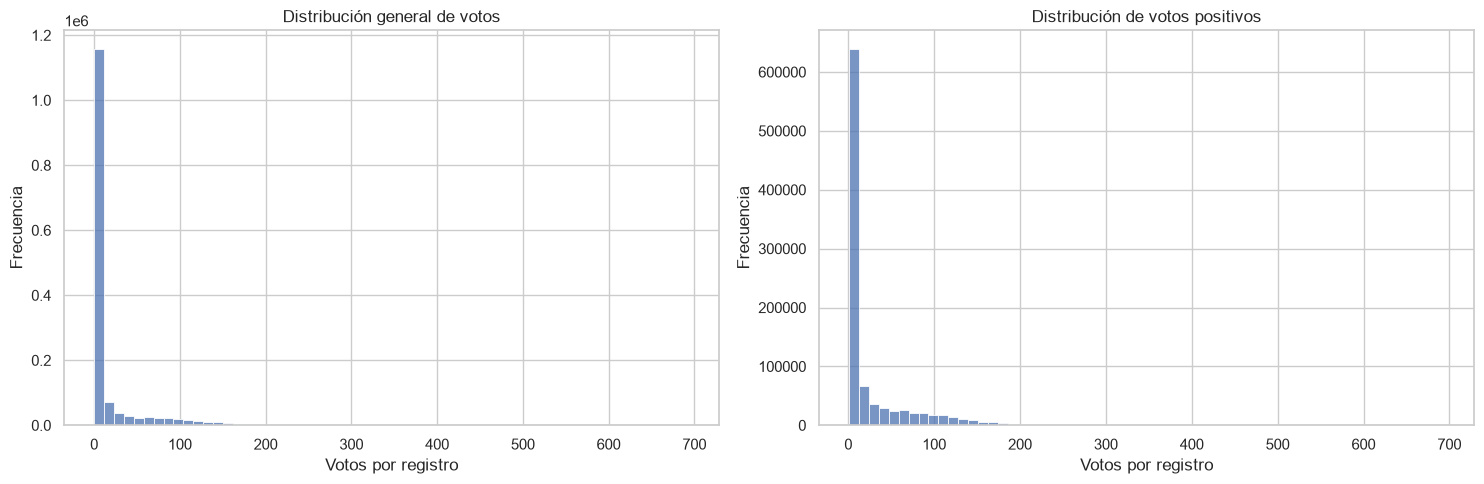

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.histplot(
    data=df_preconteo,
    x="votos",
    bins=60,
    ax=axes[0]
)

axes[0].set_title("Distribución general de votos")
axes[0].set_xlabel("Votos por registro")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    x=df_preconteo.loc[
        df_preconteo["votos"] > 0,
        "votos"
    ],
    bins=60,
    ax=axes[1]
)

axes[1].set_title("Distribución de votos positivos")
axes[1].set_xlabel("Votos por registro")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [56]:
frecuencias_votos = (
    df_preconteo["votos"]
    .value_counts()
    .rename_axis("votos")
    .reset_index(name="frecuencia")
)

frecuencias_votos["porcentaje"] = (
    frecuencias_votos["frecuencia"]
    / len(df_preconteo)
    * 100
)

display(
    frecuencias_votos
    .head(20)
    .round(3)
)

,votos,frecuencia,porcentaje
0,0,527421,35.648
1,1,237402,16.046
2,2,114083,7.711
3,3,74591,5.042
4,4,53288,3.602
5,5,39904,2.697
6,6,30358,2.052
7,7,23502,1.589
8,8,18471,1.248
9,9,14759,0.998


### Interpretación de la distribución de votos

El análisis descriptivo de los 1.479.506 registros del preconteo evidencia una distribución marcadamente asimétrica hacia la derecha. La media de 16,207 votos supera considerablemente la mediana de 1 voto, lo que indica una concentración de observaciones en valores pequeños y una extensión de la distribución hacia valores elevados.

Se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este hallazgo confirma que el archivo contiene registros explícitos con valor cero, por lo que la ausencia de una combinación mesa-opción no puede interpretarse automáticamente como un resultado de cero votos.

El 75 % de los registros presenta ocho votos o menos, mientras que los percentiles 95 y 99 corresponden a 104 y 164 votos, respectivamente. El máximo observado es de 694 votos.

La distribución agregada combina diferentes candidaturas y categorías electorales, cuyas magnitudes de votación pueden variar sustancialmente. Por esta razón, los valores elevados no deben considerarse anomalías únicamente por su posición en la distribución global.

Los resultados justifican profundizar en el comportamiento de los votos por opción electoral y posteriormente por mesa, conservando la distinción entre valores observados, registros explícitos con cero y opciones ausentes.

In [57]:
# Trabajar únicamente con las 13 candidaturas identificadas
df_candidaturas = df_preconteo[
    df_preconteo["candidato"].isin(
        catalogo_electoral["candidato"]
    )
].copy()

# Incorporar nombres sin modificar los datos originales
df_candidaturas = df_candidaturas.merge(
    catalogo_electoral[
        ["lista_partido", "candidato", "nombre_completo"]
    ],
    on=["lista_partido", "candidato"],
    how="left",
    validate="many_to_one"
)

resumen_candidaturas = (
    df_candidaturas
    .groupby(["candidato", "nombre_completo"])
    .agg(
        registros=("votos", "size"),
        votos_totales=("votos", "sum"),
        media=("votos", "mean"),
        mediana=("votos", "median"),
        desviacion=("votos", "std"),
        maximo=("votos", "max"),
        registros_cero=("votos", lambda x: (x == 0).sum())
    )
    .reset_index()
)

resumen_candidaturas["porcentaje_ceros"] = (
    resumen_candidaturas["registros_cero"]
    / resumen_candidaturas["registros"]
    * 100
)

display(
    resumen_candidaturas
    .sort_values("candidato")
    .round(2)
)

,candidato,nombre_completo,registros,votos_totales,media,mediana,desviacion,maximo,registros_cero,porcentaje_ceros
0,001,IVÁN CEPEDA CASTRO,121967,9688361,79.43,75.0,43.53,325,100,0.08
1,002,CLAUDIA LÓPEZ,106109,225517,2.13,1.0,3.14,245,34606,32.61
2,003,RAÚL SANTIAGO BOTERO JARAMILLO,102972,206140,2.00,1.0,2.36,179,23425,22.75
3,004,ABELARDO DE LA ESPRIELLA,121597,10361499,85.21,77.0,53.01,694,260,0.21
4,005,ÓSCAR MAURICIO LIZCANO ARANGO,78894,53839,0.68,0.0,1.73,136,46567,59.02
5,006,MIGUEL URIBE LONDOÑO,73312,28657,0.39,0.0,0.73,60,50846,69.36
6,007,SONDRA MACOLLINS GARVIN PINTO,69947,19889,0.28,0.0,0.60,25,53296,76.19
7,008,ROY LEONARDO BARRERAS MONTEALEGRE,67626,14108,0.21,0.0,0.51,18,55423,81.96
8,009,CARLOS EDUARDO CAICEDO OMAR,65201,12694,0.19,0.0,0.54,24,54686,83.87
9,010,GUSTAVO MATAMOROS CAMACHO,63261,5627,0.09,0.0,0.44,29,58454,92.40


### Distribución de votos por candidatura

El análisis desagregado de las 13 candidaturas evidencia una heterogeneidad considerable en las distribuciones de votos registrados por mesa.

Las candidaturas presentan diferencias tanto en sus medidas de tendencia central como en la proporción de registros con cero votos. Las medianas observadas oscilan entre 0 y 77 votos, mientras que los porcentajes de registros con cero varían entre 0,08 % y 92,40 %.

Adicionalmente, la cantidad de registros disponibles difiere entre candidaturas. Esta característica debe considerarse al interpretar las estadísticas, ya que los registros presentes no necesariamente constituyen el mismo conjunto de mesas para todas las opciones electorales.

Los resultados indican que la distribución agregada de votos combina poblaciones con comportamientos estadísticos distintos. Por consiguiente, la identificación de observaciones atípicas mediante umbrales globales podría resultar inadecuada, dado que valores habituales para una candidatura podrían ser poco frecuentes para otra.

En esta fase de entendimiento de los datos, estos hallazgos justifican explorar las distribuciones por candidatura y estudiar la relación entre presencia de registros, valores explícitos de cero y magnitudes de votación. No se atribuyen causas a las diferencias observadas ni se interpretan como evidencia de irregularidades electorales.

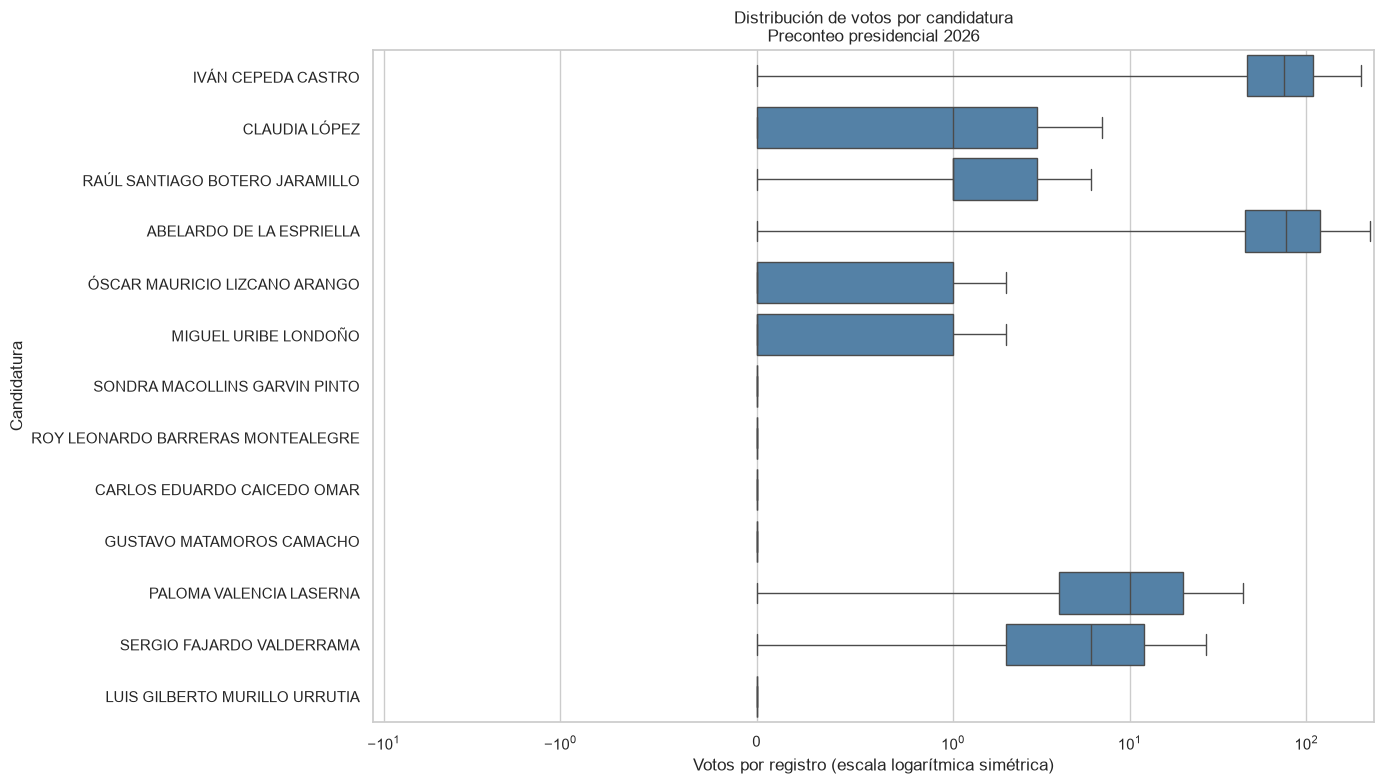

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ordenar por código de candidatura
orden_candidatos = (
    catalogo_electoral
    .sort_values("candidato")["nombre_completo"]
    .tolist()
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_candidaturas,
    x="votos",
    y="nombre_completo",
    order=orden_candidatos,
    showfliers=False,
    color="steelblue"
)

plt.xscale("symlog", linthresh=1)

plt.title(
    "Distribución de votos por candidatura\n"
    "Preconteo presidencial 2026"
)

plt.xlabel("Votos por registro (escala logarítmica simétrica)")
plt.ylabel("Candidatura")

plt.tight_layout()
plt.show()

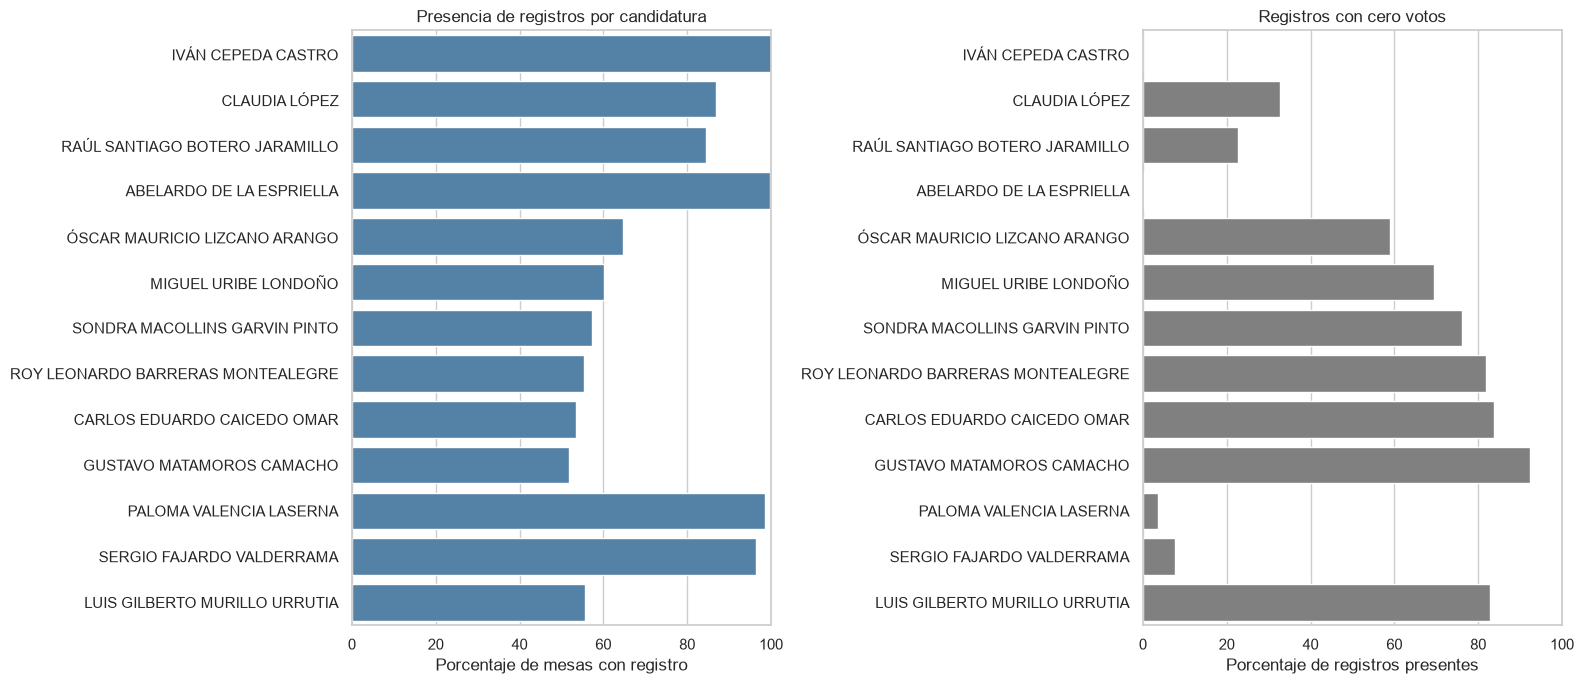

In [59]:
total_mesas = 122020

grafico_candidaturas = resumen_candidaturas.copy()

grafico_candidaturas["porcentaje_presencia"] = (
    grafico_candidaturas["registros"]
    / total_mesas * 100
)

grafico_candidaturas = (
    grafico_candidaturas
    .sort_values("candidato")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_presencia",
    y="nombre_completo",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Presencia de registros por candidatura")
axes[0].set_xlabel("Porcentaje de mesas con registro")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_ceros",
    y="nombre_completo",
    ax=axes[1],
    color="gray"
)

axes[1].set_title("Registros con cero votos")
axes[1].set_xlabel("Porcentaje de registros presentes")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Distribución de votos agregados por mesa electoral

La exploración anterior permitió identificar diferencias significativas en las distribuciones de votos entre candidaturas, así como variaciones en la presencia de registros y en la frecuencia de valores explícitos de cero.

En esta sección se adopta la mesa electoral como unidad de análisis, definida mediante la combinación de departamento, municipio, zona, puesto y mesa.

Para cada unidad se calculará la suma de los votos registrados en las distintas opciones electorales. Esta agregación permitirá describir la distribución de las magnitudes de votación observadas entre mesas y examinar la presencia de valores extremos.

Debe tenerse en cuenta que la suma de votos registrados no equivale necesariamente al número de sufragantes ni a la participación electoral, ya que todavía no se ha verificado la completitud de todas las categorías electorales ni su correspondencia con los indicadores oficiales de votación.

In [60]:
# Verificar las variables necesarias
columnas_requeridas = [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

assert all(
    columna in resumen_mesas.columns
    for columna in columnas_requeridas
)

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Votos registrados (suma global)": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(
    estadisticas_mesas
    .to_frame("Valor")
    .round(2)
)

,Valor
Total de mesas,122020.00
Votos registrados (suma global),23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00


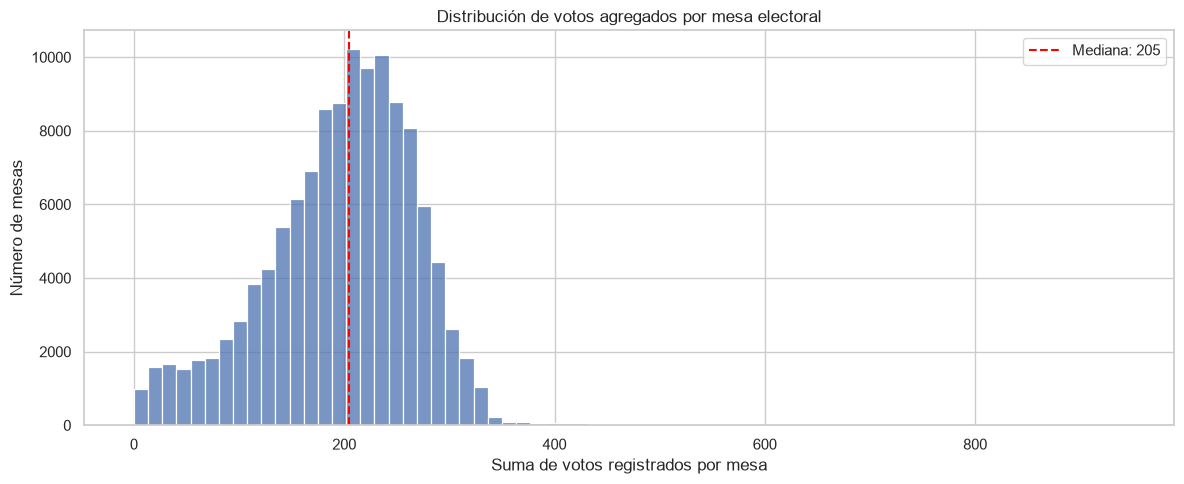

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=resumen_mesas,
    x="suma_votos_registrados",
    bins=70,
    ax=ax
)

ax.axvline(
    votos_mesa.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {votos_mesa.median():.0f}"
)

ax.set_title(
    "Distribución de votos agregados por mesa electoral"
)
ax.set_xlabel("Suma de votos registrados por mesa")
ax.set_ylabel("Número de mesas")
ax.legend()

plt.tight_layout()
plt.show()

In [62]:
columnas_resultado = (
    columnas_mesa
    + [
        "opciones_presentes",
        "suma_votos_registrados",
        "registros_cero"
    ]
)

print("Mesas con las mayores sumas de votos registrados")

display(
    resumen_mesas
    .nlargest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

print("Mesas con las menores sumas de votos registrados")

display(
    resumen_mesas
    .nsmallest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

Mesas con las mayores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9


Mesas con las menores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


### Caracterización estadística de las mesas electorales

La mesa electoral constituye una unidad de análisis fundamental para el estudio del preconteo. A diferencia del análisis por candidatura, esta perspectiva permite examinar la magnitud total de votos registrados y la cantidad de opciones electorales presentes en cada mesa.

Se estudiará la distribución de las sumas de votos, prestando especial atención a sus percentiles y a las observaciones situadas en los extremos. También se examinará la relación entre la cantidad de opciones registradas y la suma de votos observada.

Estas comparaciones tienen un carácter exclusivamente descriptivo. La presencia de valores extremos o de un número reducido de opciones electorales no constituye, por sí misma, evidencia de errores o irregularidades.

In [63]:
import pandas as pd

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Suma global de votos registrados": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(estadisticas_mesas.to_frame("Valor").round(2))

columnas_resultado = columnas_mesa + [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

print("\nMesas con mayores sumas de votos")
display(
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

print("\nMesas con menores sumas de votos")
display(
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

,Valor
Total de mesas,122020.00
Suma global de votos registrados,23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00



Mesas con mayores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9



Mesas con menores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


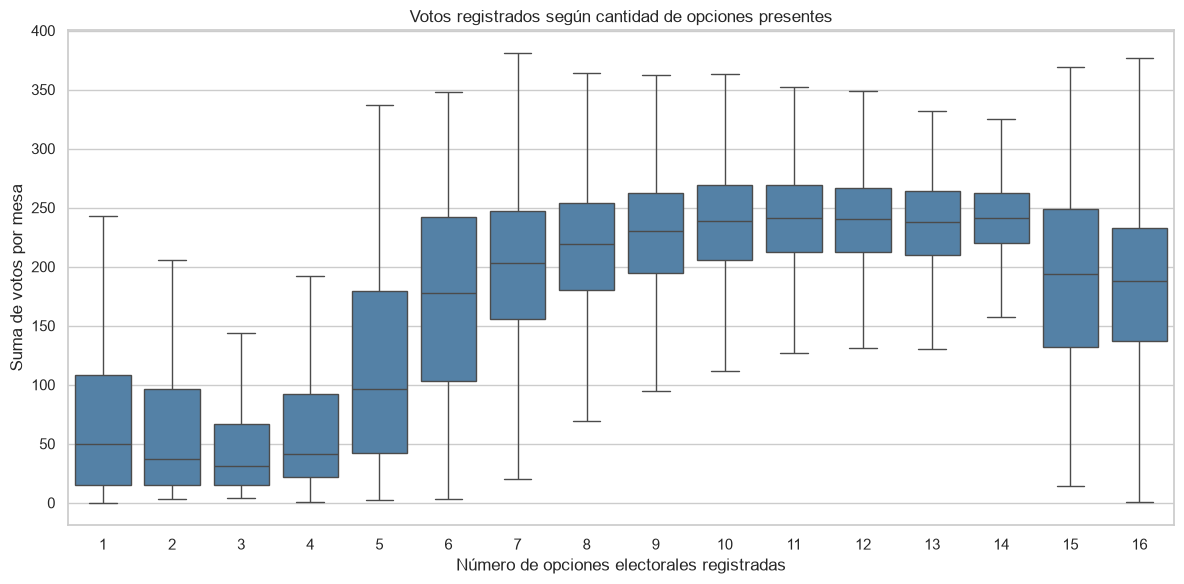

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=resumen_mesas,
    x="opciones_presentes",
    y="suma_votos_registrados",
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Votos registrados según cantidad de opciones presentes"
)
ax.set_xlabel("Número de opciones electorales registradas")
ax.set_ylabel("Suma de votos por mesa")

plt.tight_layout()
plt.show()

### Exploración de valores extremos por mesa

La inspección de las mesas con mayores sumas de votos registrados identificó un máximo observado de 942 votos. Las diez mesas con mayores sumas pertenecen al código departamental `88`, lo que sugiere la conveniencia de examinar su correspondencia territorial y sus características operativas.

Por otra parte, entre las mesas con menores sumas se identificaron registros cuya agregación es igual a cero. Las observaciones mostradas contienen una única opción electoral registrada con cero votos.

Estos resultados evidencian que los extremos de la distribución requieren contextualización territorial y operativa. La magnitud de votos agregados, por sí sola, no permite determinar si un registro es incorrecto o irregular.

En consecuencia, se propone examinar los códigos territoriales de las mesas extremas mediante el catálogo DIVIPOL, antes de formular interpretaciones adicionales.

In [65]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_divipol = next(
        n for n in z.namelist()
        if Path(n).name.upper().startswith("DIVIPOL_")
    )

    lineas_divipol = (
        z.read(nombre_divipol)
        .decode("latin-1")
        .splitlines()
    )

print("Total de registros DIVIPOL:", len(lineas_divipol))

print(
    "Longitudes observadas:",
    sorted(set(map(len, lineas_divipol)))
)

for departamento in ["17", "88"]:
    print(f"\nDepartamento {departamento}")

    ejemplos = [
        linea for linea in lineas_divipol
        if linea.startswith(departamento)
    ]

    print("Registros encontrados:", len(ejemplos))

    for linea in ejemplos[:10]:
        print(repr(linea))

Total de registros DIVIPOL: 14438
Longitudes observadas: [146]

Departamento 17
Registros encontrados: 449
'170010101CHOCO       QUIBDO                        COLEGIO PEDRO GRAU AROLA                1000032560000289600001801COMUNA 1                      '
'170010102CHOCO       QUIBDO                        COLEGIO MANUEL CAÑIZALES                1000062640000471400003202COMUNA 2                      '
'170010103CHOCO       QUIBDO                        IE ARMANDO LUNA ROA                     1000048890000339900002402COMUNA 2                      '
'170010104CHOCO       QUIBDO                        I.E. MIA JORGE VALENCIA LOZANO          1000003190000017300000202COMUNA 2                      '
'170010105CHOCO       QUIBDO                        ESCUELA EL REPOSO                       1000008580000063600000501COMUNA 1                      '
'170010106CHOCO       QUIBDO                        IE ANTONIO MARIA CLARET SEDE MIRAFLORES 1000007910000055500000401COMUNA 1                      '

In [66]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
])

display(
    mesas_extremas[
        columnas_mesa
        + ["opciones_presentes", "suma_votos_registrados"]
    ]
    .sort_values(
        ["departamento", "municipio", "zona", "puesto"]
    )
)

,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados
67657,17,001,99,25,000001,1,0
67664,17,001,99,33,000001,1,0
67868,17,010,99,17,000001,1,0
67930,17,011,99,40,000001,1,0
67931,17,011,99,41,000001,1,0
68221,17,025,99,17,000001,1,0
118413,88,130,05,81,000001,1,0
118414,88,130,05,82,000001,1,0
118415,88,130,05,83,000001,1,0
118416,88,130,05,84,000001,1,0


### Contextualización territorial de los valores extremos

La exploración del catálogo DIVIPOL identificó 14.438 registros de longitud uniforme de 146 caracteres, correspondientes a unidades territoriales y puestos electorales.

Se confirmó que el código departamental `17` corresponde a Chocó, mientras que el código `88` identifica la categoría `CONSULADOS`, asociada con la votación en el exterior.

Las diez mesas con mayores sumas de votos registrados pertenecen al código `88`. Este hallazgo indica que los valores extremos superiores observados se concentran, dentro del conjunto examinado, en mesas del exterior.

Por otra parte, las mesas con sumas iguales a cero que se inspeccionaron pertenecen tanto a Chocó como a consulados y presentan un único registro electoral con cero votos.

Estos resultados muestran la importancia de considerar la dimensión territorial y las características operativas de las mesas antes de interpretar valores extremos. No se concluye que estas observaciones constituyan errores o irregularidades.

In [67]:
import pandas as pd

# Estructura territorial observada:
# [0:2]   Departamento
# [2:5]   Municipio
# [5:7]   Zona
# [7:9]   Puesto
# [9:21]  Nombre del departamento o categoría
# [21:51] Nombre del municipio o país
# [51:91] Nombre del puesto

df_divipol = pd.DataFrame([
    {
        "departamento": linea[0:2],
        "municipio": linea[2:5],
        "zona": linea[5:7],
        "puesto": linea[7:9],
        "nombre_departamento": linea[9:21].strip(),
        "nombre_municipio": linea[21:51].strip(),
        "nombre_puesto": linea[51:91].strip(),
    }
    for linea in lineas_divipol
])

columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

print("Registros DIVIPOL:", len(df_divipol))
print(
    "Claves de puesto únicas:",
    df_divipol[columnas_puesto]
    .drop_duplicates()
    .shape[0]
)

display(df_divipol.head())

Registros DIVIPOL: 14438
Claves de puesto únicas: 14438


,departamento,municipio,zona,puesto,nombre_departamento,nombre_municipio,nombre_puesto
0,01,001,01,01,ANTIOQUIA,MEDELLIN,SEC. ESC. LA ESPERANZA No 2
1,01,001,01,02,ANTIOQUIA,MEDELLIN,INST.EDUC. LA CANDELARIA
2,01,001,01,03,ANTIOQUIA,MEDELLIN,IE MARIA DE LOS ANGELES CANO MARQUEZ
3,01,001,01,04,ANTIOQUIA,MEDELLIN,SEC. ESC. MEDELLIN
4,01,001,01,05,ANTIOQUIA,MEDELLIN,I.E.FE Y ALEGRIA GRANIZAL


In [68]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
]).copy()

mesas_extremas["tipo_extremo"] = (
    ["Superior"] * 10
    + ["Inferior"] * 10
)

mesas_extremas_territorio = mesas_extremas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Correspondencia con DIVIPOL:")
print(mesas_extremas_territorio["_merge"].value_counts())

display(
    mesas_extremas_territorio[
        [
            "tipo_extremo",
            "nombre_departamento",
            "nombre_municipio",
            "nombre_puesto",
            "mesa",
            "opciones_presentes",
            "suma_votos_registrados",
            "_merge"
        ]
    ]
)

Correspondencia con DIVIPOL:
_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64


,tipo_extremo,nombre_departamento,nombre_municipio,nombre_puesto,mesa,opciones_presentes,suma_votos_registrados,_merge
0,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES LOS ANGELES - CONSULADO,000001,8,942,both
1,Superior,CONSULADOS,ESTADOS UNIDOS,VIERNES NEWARK - CONSULADO,000001,16,663,both
2,Superior,CONSULADOS,ESPAÑA,VIERNES MADRID - CONSULADO,000009,16,639,both
3,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES NEWARK - CONSULADO,000001,16,635,both
4,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NUEVA YORK - CONSULADO,000001,9,625,both
5,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES ORLANDO - CONSULADO,000003,16,615,both
6,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES MIAMI - CONSULADO,000007,16,603,both
7,Superior,CONSULADOS,COSTA RICA,JUEVES SAN JOSÉ - CONSULADO,000001,9,597,both
8,Superior,CONSULADOS,COSTA RICA,VIERNES SAN JOSÉ - CONSULADO,000001,10,596,both
9,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NEWARK - CONSULADO,000001,16,593,both


### Correspondencia territorial de las mesas extremas

El catálogo DIVIPOL contiene 14.438 registros y el mismo número de claves únicas de puesto electoral, lo que permite establecer correspondencias mediante departamento, municipio, zona y puesto.

La vinculación de las diez mesas con mayores sumas de votos y las diez mesas con menores sumas produjo una correspondencia completa con DIVIPOL.

Las mayores sumas observadas se localizaron en puestos consulares de Estados Unidos, España y Costa Rica. El máximo de 942 votos corresponde al puesto identificado como `LUNES LOS ANGELES - CONSULADO`.

Las mesas con suma cero examinadas se localizaron en puestos de Chocó y Argelia. En todos estos casos se había identificado un único registro electoral con valor cero.

Los resultados evidencian que la contextualización territorial aporta información relevante para interpretar las observaciones extremas. Sin embargo, no permiten establecer por sí solos las causas de dichas magnitudes ni determinar si corresponden a situaciones anómalas.

La coincidencia de las 20 mesas examinadas con DIVIPOL constituye una validación parcial de las claves territoriales. Para evaluar la cobertura completa del catálogo es necesario extender la comprobación a todas las mesas del preconteo.

In [69]:
columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

# Cada mesa debe encontrar como máximo un puesto DIVIPOL
resumen_mesas_territorio = resumen_mesas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

cobertura = (
    resumen_mesas_territorio["_merge"]
    .value_counts()
    .rename_axis("estado")
    .reset_index(name="mesas")
)

cobertura["porcentaje"] = (
    cobertura["mesas"]
    / len(resumen_mesas_territorio)
    * 100
)

display(cobertura)

print(
    "Mesas sin correspondencia:",
    (resumen_mesas_territorio["_merge"] == "left_only").sum()
)

,estado,mesas,porcentaje
0,both,122020,100.0
1,left_only,0,0.0
2,right_only,0,0.0


Mesas sin correspondencia: 0


In [70]:
resumen_departamentos = (
    resumen_mesas_territorio
    .groupby(
        ["departamento", "nombre_departamento"],
        dropna=False
    )
    .agg(
        mesas=("mesa", "size"),
        votos_registrados=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean"),
    )
    .reset_index()
)

display(
    resumen_departamentos
    .sort_values("departamento")
    .round(2)
)

,departamento,nombre_departamento,mesas,votos_registrados,media_votos_mesa,mediana_votos_mesa,media_opciones
0,01,ANTIOQUIA,15801,3209520,203.12,211.0,15.86
1,03,ATLANTICO,6190,1060147,171.27,173.0,15.79
2,05,BOLIVAR,5355,827020,154.44,156.0,15.86
3,07,BOYACA,3126,677633,216.77,227.0,8.44
4,09,CALDAS,2492,502807,201.77,208.0,9.60
5,11,CAUCA,3427,696829,203.33,222.0,8.19
6,12,CESAR,2754,488601,177.42,180.0,15.78
7,13,CORDOBA,4180,711571,170.23,173.0,15.82
8,15,CUNDINAMARCA,6916,1625534,235.04,245.0,8.79
9,16,BOGOTA D.C.,17164,4130084,240.62,249.0,8.28


In [71]:
resumen_mesas_territorio["ambito"] = np.where(
    resumen_mesas_territorio["departamento"] == "88",
    "Consulados",
    "Territorio nacional"
)

resumen_ambito = (
    resumen_mesas_territorio
    .groupby("ambito")
    .agg(
        mesas=("mesa", "size"),
        suma_votos=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean"),
        mesas_suma_cero=(
            "suma_votos_registrados",
            lambda x: (x == 0).sum()
        ),
    )
    .reset_index()
)

display(resumen_ambito.round(2))

,ambito,mesas,suma_votos,media_votos_mesa,mediana_votos_mesa,media_opciones,mesas_suma_cero
0,Consulados,3670,589829,160.72,112.0,12.45,9
1,Territorio nacional,118350,23388475,197.62,206.0,12.12,6


In [ ]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# --- Ubicación del ZIP (si usan Drive, descomenten las dos líneas y ajusten la ruta) ---
# from google.colab import drive; drive.mount("/content/drive")
# ZIP_ORIGEN = Path("/content/drive/MyDrive/maestria/MMV_Presidente1V_2026 (2).zip")
candidatos_zip = sorted(Path("/content").glob("MMV_Presidente1V_2026*.zip"))
if not candidatos_zip:
    raise FileNotFoundError("Suba el ZIP MMV_Presidente1V_2026 al panel Files de Colab")
ZIP_ORIGEN = candidatos_zip[0]

DATA_DIR = Path("/content/datos")
DATA_DIR.mkdir(parents=True, exist_ok=True)

def buscar_archivo(patron, directorio=DATA_DIR):
    resultados = list(directorio.rglob(patron))
    if not resultados:
        raise FileNotFoundError(f"No se encontró '{patron}' dentro de {directorio}")
    return resultados[0]

with zipfile.ZipFile(ZIP_ORIGEN) as z:
    z.extractall(DATA_DIR)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(buscar_archivo(zip_interno)) as z:
        z.extractall(buscar_archivo(zip_interno).parent)

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


#### Escrutinio

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

In [ ]:
escru.head()

,comunicado,dep,mun,zona,puesto,mesa,comuna,corporacion,circ,partido,candidato,votos
0,9999,01,001,001,01,000001,00,001,0,00026,001,30
1,9999,01,001,001,01,000001,00,001,0,01004,002,1
2,9999,01,001,001,01,000001,00,001,0,01001,003,0
3,9999,01,001,001,01,000001,00,001,0,01003,004,59
4,9999,01,001,001,01,000001,00,001,0,03001,005,0


In [ ]:
escru.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1952320 entries, 0 to 1952319
Data columns (total 12 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   comunicado   object
 1   dep          object
 2   mun          object
 3   zona         object
 4   puesto       object
 5   mesa         object
 6   comuna       object
 7   corporacion  object
 8   circ         object
 9   partido      object
 10  candidato    object
 11  votos        int64 
dtypes: int64(1), object(11)
memory usage: 1.1 GB


In [ ]:
esc_diccionario = pd.DataFrame([
    ("comunicado",  "Valor fijo (9999)",   "Numérico",     4, "Valor fijo; siempre 9999"),
    ("dep",         "Código Departamento", "Numérico",     2, "Departamento de la mesa (88 = consulados)"),
    ("mun",         "Código Municipio",    "Numérico",     3, "Municipio dentro del departamento"),
    ("zona",        "Código Zona",         "Numérico",     3, "Zona electoral dentro del municipio"),
    ("puesto",      "Código Puesto",       "Alfanumérico", 2, "Puesto de votación dentro de la zona"),
    ("mesa",        "Número de mesa",      "Numérico",     6, "Mesa dentro del puesto; con las cuatro llaves anteriores identifica la mesa"),
    ("comuna",      "Código Comuna",       "Numérico",     2, "Comuna o localidad; siempre 00 en este archivo"),
    ("corporacion", "Código corporación",  "Numérico",     3, "Cargo que se elige; 001 = Presidente"),
    ("circ",        "Circunscripción",     "Numérico",     1, "Circunscripción electoral; siempre 0 en este archivo"),
    ("partido",     "Código de partido",   "Numérico",     4, "Partido que inscribe al candidato (completado a 5 dígitos en la carga)"),
    ("candidato",   "Código de candidato", "Numérico",     3, "Candidato (001–013) o voto especial: 996 blanco, 997 nulo, 998 no marcado"),
    ("votos",       "Votos",               "Numérico",     8, "Votos de la candidatura en la mesa según el escrutinio oficial"),
], columns=["columna", "campo_oficial", "tipo_oficial", "longitud", "descripcion"])

esc_diccionario["tipo_pandas"]    = esc_diccionario["columna"].map(escru.dtypes.astype(str))
esc_diccionario["valores_unicos"] = esc_diccionario["columna"].map(escru.nunique())
esc_diccionario["ejemplo"]        = esc_diccionario["columna"].map(escru.iloc[0])
esc_diccionario = esc_diccionario[["columna", "campo_oficial", "tipo_oficial", "longitud",
                                   "tipo_pandas", "valores_unicos", "ejemplo", "descripcion"]]
display(esc_diccionario)

,columna,campo_oficial,tipo_oficial,longitud,tipo_pandas,valores_unicos,ejemplo,descripcion
0,comunicado,Valor fijo (9999),Numérico,4,object,1,9999,Valor fijo; siempre 9999
1,dep,Código Departamento,Numérico,2,object,34,01,Departamento de la mesa (88 = consulados)
2,mun,Código Municipio,Numérico,3,object,309,001,Municipio dentro del departamento
3,zona,Código Zona,Numérico,3,object,52,001,Zona electoral dentro del municipio
4,puesto,Código Puesto,Alfanumérico,2,object,208,01,Puesto de votación dentro de la zona
5,mesa,Número de mesa,Numérico,6,object,228,000001,Mesa dentro del puesto; con las cuatro llaves ...
6,comuna,Código Comuna,Numérico,2,object,1,00,Comuna o localidad; siempre 00 en este archivo
7,corporacion,Código corporación,Numérico,3,object,1,001,Cargo que se elige; 001 = Presidente
8,circ,Circunscripción,Numérico,1,object,1,0,Circunscripción electoral; siempre 0 en este a...
9,partido,Código de partido,Numérico,4,object,14,00026,Partido que inscribe al candidato (completado ...


In [ ]:
esc_mesas = escru.groupby(LLAVE_MESA).agg(filas=("votos", "size"),
                                          ceros=("votos", lambda s: (s == 0).sum()))
esc_resumen = pd.Series(dtype=object, data={
    "Registros": len(escru),
    "Columnas": escru.shape[1],
    "Mesas": len(esc_mesas),
    "Mesas completas (16 filas)": (esc_mesas["filas"] == 16).sum(),
    "Mesas incompletas (< 16 filas)": (esc_mesas["filas"] < 16).sum(),
    "Filas con 0 votos": (escru["votos"] == 0).sum(),
    "Filas ausentes frente a la rejilla 122 020 × 16": len(esc_mesas) * 16 - len(escru),
    "Votos totales": escru["votos"].sum(),
    "Tamaño en disco (MB)": round(os.path.getsize(ARCH_ESCRUTINIO) / 1024**2, 2),
    "Tamaño en memoria (MB)": round(escru.memory_usage(deep=True).sum() / 1024**2, 1),
})
display(esc_resumen.to_frame("valor"))
display(esc_mesas["filas"].value_counts().sort_index().to_frame("mesas"))   # filas por mesa

,valor
Registros,1952320
Columnas,12
Mesas,122020
Mesas completas (16 filas),122020
Mesas incompletas (< 16 filas),0
Filas con 0 votos,1008827
Filas ausentes frente a la rejilla 122 020 × 16,0
Votos totales,23990635
Tamaño en disco (MB),100.54
Tamaño en memoria (MB),1081.8


,mesas
filas,
16,122020


**¿Cuántos documentos tiene el *dataset*?**

El archivo de escrutinio contiene **1 952 320 registros** y 12 columnas. Cada registro representa la votación oficial de una candidatura en una mesa. Los registros cubren las **122 020 mesas** de la elección (118 350 nacionales y 3 670 en consulados), y **todas las mesas tienen exactamente 16 registros**: los 13 candidatos más el voto en blanco (996), el voto nulo (997) y los votos no marcados (998).

A diferencia del preconteo, donde 61 623 mesas omiten las candidaturas sin votos, el escrutinio es una rejilla completa (122 020 × 16 = 1 952 320). No le falta ningún registro e incluye todas las candidaturas aunque no hayan obtenido votos. Por eso 1 008 827 registros (51,7 %) tienen cero votos. En total, el escrutinio suma **23 990 635 votos**, 12 331 más que el preconteo.

**¿En qué formato están almacenados los datos?**

El escrutinio es un archivo de valores separados por punto y coma (`.csv` con `;`), sin encabezado y codificado en latin-1. Cada línea contiene los 12 campos definidos en el documento *Estructuras Básicas*, que se describen en la tabla anterior con su tipo oficial, su longitud y el tipo con el que se cargaron en *pandas*. Las líneas terminan con un `;` adicional que genera una decimotercera columna vacía; por eso la carga lee únicamente los 12 primeros campos.

Los campos se completan con ceros a la izquierda. Por eso las llaves y los códigos se conservan como texto (`object`) y solo `votos` se convierte a entero (`int64`). Ninguna columna presenta valores nulos. Cuatro campos tienen un único valor en todo el archivo (`comunicado` = 9999, `comuna` = 00, `corporacion` = 001 y `circ` = 0), por lo que no aportan información para el análisis.

El formato difiere del preconteo en dos llaves: la zona tiene 3 dígitos en el escrutinio (2 en el preconteo) y el partido 4 dígitos (5 en el preconteo y en el catálogo de partidos). Durante la carga, el partido se completó a 5 dígitos (por ejemplo, `0026` → `00026`) para poder cruzar las fuentes.

**¿Qué tamaño en MB tiene el conjunto de datos?**

El archivo ocupa **100,54 MB en disco**, y es la fuente más pesada del paquete. Una vez cargado en *pandas*, ocupa **1 081,8 MB en memoria** (aproximadamente 1,1 GB), unas 11 veces más, porque las once columnas de texto almacenan cada valor como un objeto independiente.

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

#### Escrutinio


**¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad?**

In [ ]:
LONGITUD_OFICIAL = {"comunicado": 4, "dep": 2, "mun": 3, "zona": 3, "puesto": 2, "mesa": 6,
                    "comuna": 2, "corporacion": 3, "circ": 1, "partido": 4, "candidato": 3}

revision = pd.DataFrame({
    "longitud_oficial": LONGITUD_OFICIAL,
    "longitudes_encontradas": {c: sorted(escru[c].str.len().unique()) for c in LONGITUD_OFICIAL},
    "solo_digitos": {c: escru[c].str.isdigit().all() for c in LONGITUD_OFICIAL},
})
display(revision)

print("Departamentos que no están en DIVIPOL:", set(escru["dep"]) - set(divipol["dep"]))
print("Candidatos que no están en el catálogo:", set(escru["candidato"]) - set(candidatos["candidato"]))

,longitud_oficial,longitudes_encontradas,solo_digitos
comunicado,4,[4],True
dep,2,[2],True
mun,3,[3],True
zona,3,[3],True
puesto,2,[2],False
mesa,6,[6],True
comuna,2,[2],True
corporacion,3,[3],True
circ,1,[1],True
partido,4,[5],True


Departamentos que no están en DIVIPOL: set()
Candidatos que no están en el catálogo: {'998', '997', '996'}


In [ ]:
# ¿Cada departamento + municipio existe en DIVIPOL?
esc_mun = escru[["dep", "mun"]].drop_duplicates()
cat_mun = divipol[["dep", "mun", "dep_nombre", "mun_nombre"]].drop_duplicates()
cruce_mun = esc_mun.merge(cat_mun, on=["dep", "mun"], how="left")
print("Municipios en el escrutinio:", len(esc_mun))
print("Municipios sin nombre en DIVIPOL:", cruce_mun["mun_nombre"].isnull().sum())
display(cruce_mun.head())

# ¿Cada puesto existe en DIVIPOL?
esc_puesto = escru[["dep", "mun", "zona", "puesto"]].drop_duplicates()
cruce_puesto = esc_puesto.merge(divipol[["dep", "mun", "zona", "puesto", "puesto_nombre"]],
                                on=["dep", "mun", "zona", "puesto"], how="left")
print("Puestos en el escrutinio:", len(esc_puesto))
print("Puestos sin nombre en DIVIPOL:", cruce_puesto["puesto_nombre"].isnull().sum())

Municipios en el escrutinio: 1189
Municipios sin nombre en DIVIPOL: 0


,dep,mun,dep_nombre,mun_nombre
0,01,001,ANTIOQUIA,MEDELLIN
1,01,004,ANTIOQUIA,ABEJORRAL
2,01,007,ANTIOQUIA,ABRIAQUI
3,01,010,ANTIOQUIA,ALEJANDRIA
4,01,013,ANTIOQUIA,AMAGA


Puestos en el escrutinio: 14438
Puestos sin nombre en DIVIPOL: 0


Valores nulos por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
votos          0
dtype: int64

Mesas con 0 votos: 46
excluida
NO    118313
SI        37
Name: count, dtype: int64

Rango de votos por fila: 0 a 694
Rango de votos por mesa: 0 a 942


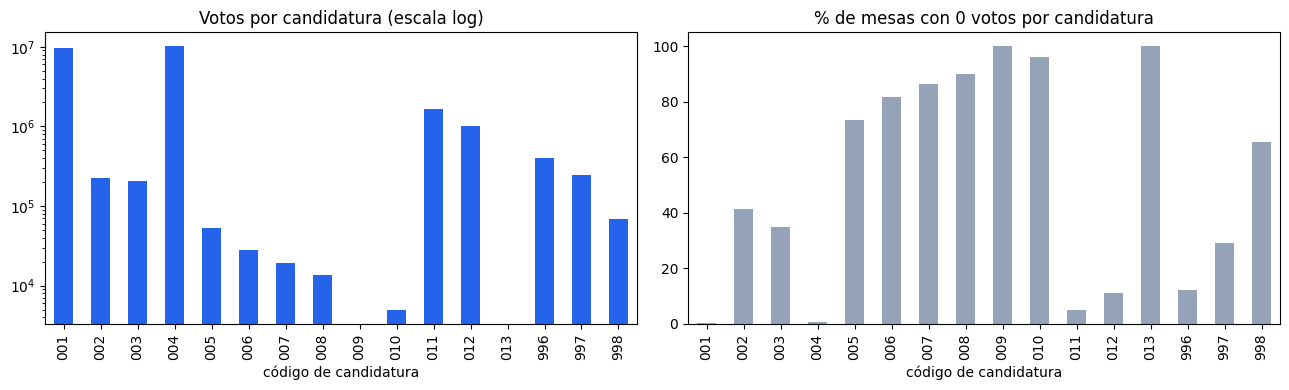

In [ ]:
print("Valores nulos por columna:")
print(escru.isnull().sum())

votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum()
print("\nMesas con 0 votos:", (votos_mesa == 0).sum())
print(noved["excluida"].value_counts())
print("\nRango de votos por fila:", escru["votos"].min(), "a", escru["votos"].max())
print("Rango de votos por mesa:", votos_mesa.min(), "a", votos_mesa.max())

votos_cand = escru.groupby("candidato")["votos"].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
votos_cand.plot.bar(ax=ax[0], color="#2563EB")
ax[0].set_yscale("log")
ax[0].set_title("Votos por candidatura (escala log)")
ax[0].set_xlabel("código de candidatura")
(escru["votos"] == 0).groupby(escru["candidato"]).mean().mul(100).plot.bar(ax=ax[1], color="#94A3B8")
ax[1].set_title("% de mesas con 0 votos por candidatura")
ax[1].set_xlabel("código de candidatura")
plt.tight_layout()
plt.show()

In [ ]:
print(escru.nunique())

comunicado       1
dep             34
mun            309
zona            52
puesto         208
mesa           228
comuna           1
corporacion      1
circ             1
partido         14
candidato       16
votos          398
dtype: int64


In [ ]:
print("Votos negativos:", (escru["votos"] < 0).sum())

Votos negativos: 0


No hay datos ausentes. Ninguna columna tiene valores nulos y, como el archivo incluye todas las combinaciones de mesa y candidatura, no falta ninguna mesa ni ninguna candidatura.

Se identifican **46 mesas vacías**, con cero votos en total. Nueve son de consulados. Las otras 37 coinciden con las 37 mesas que el archivo de novedades marca como excluidas: la comisión escrutadora anuló su votación, así que el cero es el resultado esperado y no un error de datos.

No se encontraron valores de baja calidad. No hay votos negativos; el total por mesa va de 0 a 942 votos, y el máximo de una sola candidatura en una mesa es 694.

**Figura 1.** *Votos totales y porcentaje de mesas sin votos por candidatura en el escrutinio (elaboración propia).*

La Figura 1 muestra dos situaciones a tener en cuenta en el análisis:

- **Candidatos retirados.** Los candidatos 009 y 013 no aparecen en la gráfica de la izquierda porque tienen cero votos en todas las mesas (100 % en la gráfica de la derecha): el escrutinio aplicó su retiro. Sus columnas no aportan información.
- **Abundancia de ceros.** El 51,7 % de los registros tiene cero votos. Esto es esperable: dos candidatos (001 y 004) concentran la votación y aparecen en casi todas las mesas, mientras que los candidatos minoritarios (005 a 010) no reciben votos en la mayoría de ellas. Lo mismo ocurre con los votos no marcados (998), que están en cero en cerca de dos tercios de las mesas.

También se verificó que cada campo cumpla la especificación de *Estructuras Básicas*. Todos los códigos tienen exactamente la longitud indicada y contienen solo dígitos, con dos excepciones esperadas: el puesto, que el documento define como alfanumérico (108 códigos combinan una letra y un número, como `A1`), y el partido, que tiene 5 dígitos porque se completó durante la carga para cruzarlo con el preconteo. Todos los departamentos existen en el catálogo DIVIPOL, y todos los candidatos en el catálogo oficial, salvo los códigos 996, 997 y 998, que corresponden a votos en blanco, nulos y no marcados. No se encontraron errores de digitación en los códigos.

Además de la longitud, se comprobó que los códigos correspondan a lugares reales, cruzándolos con el catálogo DIVIPOL. Como el código de municipio solo es único dentro de su departamento (el `001` es Medellín en Antioquia, pero otro municipio en otro departamento), la verificación se hizo con la pareja departamento–municipio. Las 1 189 combinaciones del escrutinio y sus 14 438 puestos de votación existen en DIVIPOL y tienen nombre asignado; en el caso de los consulados (departamento 88), cada código de municipio corresponde a un país. Por tanto, no hay códigos geográficos inexistentes ni mal digitados.

El conteo de valores únicos por columna (método `nunique()`) confirma que `comunicado`, `comuna`, `corporacion` y `circ` tienen un solo valor y no aportan información. También muestra que los códigos geográficos son jerárquicos: la columna `mesa` tiene solo 228 valores distintos, aunque el archivo contiene 122 020 mesas, porque el número de mesa se repite en cada puesto (todos los puestos tienen una mesa `000001`). Lo mismo ocurre con el municipio (309 códigos para 1 189 municipios) y el puesto (208 códigos para 14 438 puestos), según el cruce con el catálogo DIVIPOL. Por eso, una mesa solo queda identificada de forma única con la combinación de sus cinco códigos: departamento, municipio, zona, puesto y mesa.

**¿Se identifican documentos ilegibles o con dificultades de codificación?**

In [ ]:
# 1. Legibilidad: las primeras líneas se leen bien y el archivo cargó completo
with open(ARCH_ESCRUTINIO, encoding="latin-1") as f:
    for _ in range(3):
        print(repr(f.readline()))
print("\nRegistros cargados:", len(escru), "| esperados (122 020 × 16):", 122020 * 16)

# 2. Codificación: caracteres distintos de dígitos y letras mayúsculas
texto = escru.select_dtypes(exclude="number").columns
print("\nValores con caracteres extraños por columna:")
print(escru[texto].apply(lambda s: s.str.contains(r"[^0-9A-Z]").sum()))

# 3. Puestos con letra (alfanuméricos según la documentación)
print("\nCódigos de puesto con letras:", escru["puesto"][~escru["puesto"].str.isdigit()].nunique())

'9999;01;001;001;01;000001;00;001;0;0026;001;00000030;\n'
'9999;01;001;001;01;000001;00;001;0;1004;002;00000001;\n'
'9999;01;001;001;01;000001;00;001;0;1001;003;00000000;\n'

Registros cargados: 1952320 | esperados (122 020 × 16): 1952320

Valores con caracteres extraños por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
dtype: int64

Códigos de puesto con letras: 108


No. El archivo de escrutinio es legible y no presenta problemas de codificación.

**Legibilidad.** Las primeras líneas del archivo se leen correctamente. Por ejemplo, `9999;01;001;001;01;000001;00;001;0;0026;001;00000030;` indica que en la mesa 1 del puesto 1 de Medellín (departamento 01, municipio 001) el candidato 001 obtuvo 30 votos. Además, se cargaron los 1 952 320 registros esperados (122 020 mesas × 16 candidaturas), lo que confirma que ninguna línea se perdió ni se dañó durante la lectura. Su huella MD5 también coincide con la publicada por la Registraduría (Fase 1).

**Codificación.** Ninguna columna contiene caracteres distintos de dígitos y letras mayúsculas. Esto es esperable, porque el escrutinio solo almacena códigos y votos, no nombres con tildes o eñes que pudieran alterarse si el archivo se leyera con una codificación equivocada.

La única particularidad son 108 códigos de puesto que combinan una letra y un número (por ejemplo, `A1` o `Z5`). No son errores: el documento *Estructuras Básicas* define el puesto como un campo alfanumérico.

Por último, los códigos 996, 997 y 998 (voto en blanco, nulo y no marcado) no figuran en el catálogo de candidatos ni en la documentación oficial; su significado se infirió de las magnitudes de votos.

**¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?**

In [ ]:
# 1. Cómo viene el archivo sin ajustes: 13 columnas, la última vacía
crudo = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, dtype=str, nrows=5)
display(crudo)

# 2. Formato de cada campo en todo el archivo
display(pd.DataFrame({
    "longitudes": {c: sorted(escru[c].str.len().unique()) for c in escru.columns if c != "votos"},
    "solo_digitos": {c: escru[c].str.isdigit().all() for c in escru.columns if c != "votos"},
}))

# 3. Candidatos y votos especiales en la misma columna
print(escru.groupby("candidato")["partido"].first())

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,9999,01,001,001,01,000001,00,001,0,0026,001,00000030,NaN
1,9999,01,001,001,01,000001,00,001,0,1004,002,00000001,NaN
2,9999,01,001,001,01,000001,00,001,0,1001,003,00000000,NaN
3,9999,01,001,001,01,000001,00,001,0,1003,004,00000059,NaN
4,9999,01,001,001,01,000001,00,001,0,3001,005,00000000,NaN


,longitudes,solo_digitos
comunicado,[4],True
dep,[2],True
mun,[3],True
zona,[3],True
puesto,[2],False
mesa,[6],True
comuna,[2],True
corporacion,[3],True
circ,[1],True
partido,[5],True


candidato
001    00026
002    01004
003    01001
004    01003
005    03001
006    00020
007    01002
008    00022
009    01006
010    00021
011    00009
012    00015
013    01005
996    00000
997    00000
998    00000
Name: partido, dtype: object


No se observa una diversidad de formatos dentro del archivo de escrutinio. Todas sus líneas siguen la misma estructura de 12 campos separados por punto y coma, y la segunda tabla muestra que cada campo conserva una única longitud en todo el archivo: el departamento siempre tiene 2 dígitos, el municipio 3, la mesa 6, y así sucesivamente.

Sin embargo, hay cuatro particularidades de formato que dificultan su comprensión si no se conocen, y que se tuvieron en cuenta durante la carga:

- **Columna adicional vacía.** Cada línea termina con un `;` de más. Por eso, al leer el archivo sin ajustes aparecen 13 columnas, y la última (columna 12) está vacía (`NaN`), como muestra la primera tabla. Se resolvió leyendo únicamente los 12 primeros campos.
- **Códigos que parecen números pero no lo son.** Casi todos los campos están definidos como numéricos en la documentación, pero se completan con ceros a la izquierda (`01`, `001`, `000001`). Si se leyeran como números, esos ceros se perderían y los códigos cambiarían. Por eso se cargaron como texto.
- **Puesto alfanumérico.** El puesto es el único campo con `False` en la columna `solo_digitos`, porque mezcla códigos numéricos (`01`) con códigos de letra y número (`A1`, `Z5`). Ambos son válidos según la documentación.
- **Votos especiales mezclados con los candidatos.** La columna `candidato` incluye, además de los 13 candidatos, los códigos 996, 997 y 998 (voto en blanco, nulo y no marcado), que no son personas. Como muestra la última salida, se distinguen porque su partido es `00000`. En el análisis deben tratarse por separado de los candidatos.

El partido aparece con 5 dígitos en la segunda tabla, aunque el archivo trae 4, porque se completó durante la carga para cruzarlo con el preconteo.

Por tanto, el formato es consistente, pero exige conocer estas convenciones para interpretar correctamente los datos.

**¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?**

Filas duplicadas: 0
Mesa + candidato duplicados: 0

Q1: 157.0 | Mediana: 206.0 | Q3: 247.0
Límite inferior: 22.0 | Límite superior: 382.0
Atípicas bajas: 1482
Atípicas altas: 56


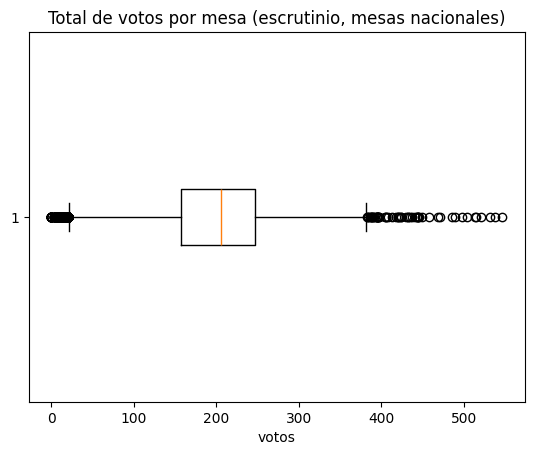

In [ ]:
print("Filas duplicadas:", escru.duplicated().sum())
print("Mesa + candidato duplicados:", escru.duplicated(subset=LLAVE_MESA + ["candidato"]).sum())

nac = votos_mesa[votos_mesa.index.get_level_values("dep") != "88"]
Q1 = nac.quantile(0.25)
Q3 = nac.quantile(0.75)
IQR = Q3 - Q1
print("\nQ1:", Q1, "| Mediana:", nac.median(), "| Q3:", Q3)
print("Límite inferior:", Q1 - 1.5 * IQR, "| Límite superior:", Q3 + 1.5 * IQR)
print("Atípicas bajas:", (nac < Q1 - 1.5 * IQR).sum())
print("Atípicas altas:", (nac > Q3 + 1.5 * IQR).sum())

plt.boxplot(nac, vert=False)
plt.title("Total de votos por mesa (escrutinio, mesas nacionales)")
plt.xlabel("votos")
plt.show()

**Duplicados.** No hay registros duplicados, ni filas completas repetidas ni combinaciones de mesa y candidatura que aparezcan más de una vez. Cada mesa tiene exactamente una fila por candidatura.

**Datos faltantes.** No hay valores nulos en ninguna columna, y las 122 020 mesas tienen sus 16 candidaturas (pregunta anterior). Las 46 mesas con cero votos no son datos faltantes: corresponden a 9 mesas de consulados y a las 37 mesas excluidas por las comisiones escrutadoras.

**Valores atípicos.** Se aplicó el criterio del rango intercuartílico (IQR) al total de votos de las 118 350 mesas nacionales. Se excluyeron los consulados porque sus mesas tienen un tope de votantes distinto. La mitad central de las mesas tiene entre 157 y 247 votos, con una mediana de 206, y los límites del criterio son 22 y 382 votos.

**Figura 2.** *Diagrama de caja del total de votos por mesa en el escrutinio, mesas nacionales (elaboración propia).*

Como muestra la Figura 2, hay atípicos en ambos extremos:

- **1 482 mesas atípicas bajas**, con menos de 22 votos. Forman una franja continua de puntos cerca de cero, no casos aislados. Pueden corresponder a mesas con pocos votantes asignados, como la última mesa de un puesto.
- **56 mesas atípicas altas**, con más de 382 votos. Son pocas y están dispersas. Pueden corresponder a puestos con un tope mayor de votantes por mesa (500 u 800).

**Tratamiento.** Estos valores no se eliminan en esta fase, porque pueden reflejar la organización de las mesas y no errores de registro. Se documentan para tratarlos en la preparación de los datos (Fase 3), por ejemplo usando tasas en lugar de conteos absolutos, de modo que una mesa pequeña sea comparable con una grande.

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

#### Escrutinio

**¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es una variable continua o categórica?**

El archivo de escrutinio no contiene por sí solo una variable objetivo. Su única medición es `votos`, una variable **numérica discreta** (un conteo entre 0 y 694 por candidatura y mesa); las demás columnas son códigos que identifican la mesa y la candidatura.

Las variables objetivo del proyecto se construyen al **comparar el escrutinio con el preconteo**, según el diseño de la Fase 1:

- **Clasificación:** si la mesa presenta una discrepancia entre ambos conteos. Es una variable **categórica binaria** (sí / no).
- **Regresión:** la magnitud de esa discrepancia, medida en votos. Es una variable **numérica discreta**.

En ambos casos, el escrutinio aporta el valor oficial de referencia. La construcción de las etiquetas y el análisis de su balance se presentan en la sección de comparación entre fuentes, porque requieren los dos archivos.

**Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.**

count    1952320.0
mean          12.3
std           32.0
min            0.0
25%            0.0
50%            0.0
75%            4.0
max          694.0
Name: votos, dtype: float64


,votos,porcentaje
candidato,,
004,10366143,43.21
001,9703921,40.45
011,1640989,6.84
012,1009346,4.21
996,407304,1.70
997,245179,1.02
002,224137,0.93
003,205319,0.86
998,69400,0.29


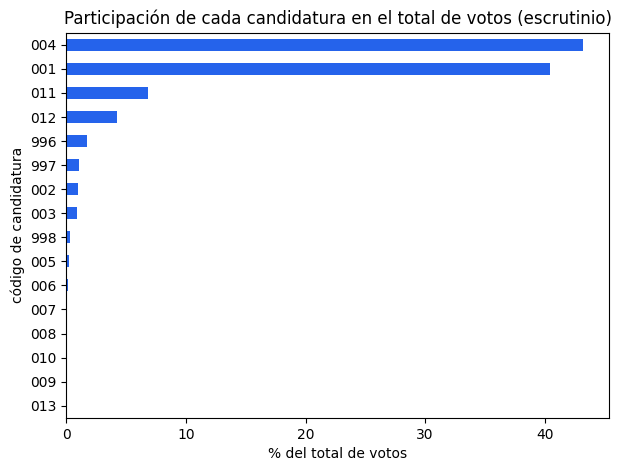

In [ ]:
print(escru["votos"].describe().round(1))

part = escru.groupby("candidato")["votos"].sum().to_frame("votos")
part["porcentaje"] = (part["votos"] / part["votos"].sum() * 100).round(2)
display(part.sort_values("votos", ascending=False))

part["porcentaje"].sort_values().plot.barh(color="#2563EB", figsize=(7, 5))
plt.title("Participación de cada candidatura en el total de votos (escrutinio)")
plt.xlabel("% del total de votos")
plt.ylabel("código de candidatura")
plt.show()


La mediana de votos por candidatura y mesa es 0 y el percentil 75 es apenas 4, mientras que el máximo llega a 694. La distribución es muy asimétrica: la mayoría de los registros tiene muy pocos votos y unos pocos concentran la mayor parte.

**Por candidatura.** Como muestra el gráfico de barras horizontales, dos candidatos concentran el 83,7 % de los 23 990 635 votos: el 004 (43,21 %) y el 001 (40,45 %). Les siguen el 011 (6,84 %) y el 012 (4,21 %). Los demás candidatos tienen menos del 1 % cada uno, y el 009 y el 013 tienen 0 % por su retiro. El voto en blanco representa el 1,70 %, el nulo el 1,02 % y el no marcado el 0,29 %.

Este desbalance tiene una consecuencia para el modelado: las candidaturas minoritarias aparecen con cero votos en la mayoría de las mesas, por lo que tomadas una por una aportan poca información.

,mesas,votos,% 001,% 004,% blanco
dep_nombre,,,,,
BOGOTA D.C.,17164,4128330,41.3,37.4,1.7
ANTIOQUIA,15801,3210392,25.1,53.7,1.9
VALLE,11087,2137681,52.6,33.3,1.9
CUNDINAMARCA,6916,1624893,36.9,44.6,1.8
ATLANTICO,6190,1063339,52.0,40.7,1.2
SANTANDER,5690,1211083,28.4,56.5,1.5
BOLIVAR,5355,827000,53.6,37.8,1.6
CORDOBA,4180,713796,55.3,37.7,1.3
NORTE DE SAN,4079,741828,17.3,70.0,1.2


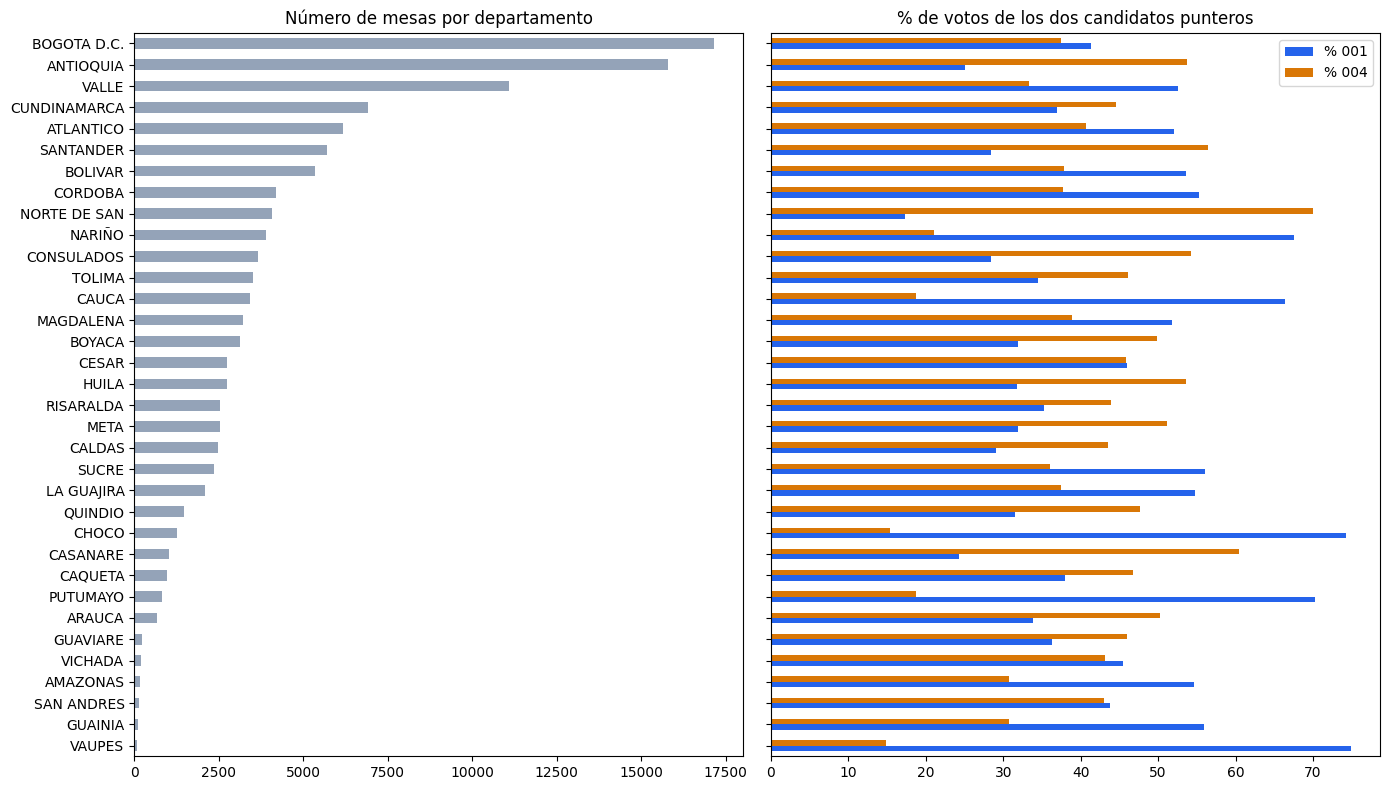

In [ ]:
nombres = divipol[["dep", "dep_nombre"]].drop_duplicates()
esc_dep = escru.merge(nombres, on="dep")

votos_dep = esc_dep.pivot_table(index="dep_nombre", columns="candidato", values="votos", aggfunc="sum")
tabla_dep = pd.DataFrame({
    "mesas": (esc_dep.groupby("dep_nombre").size() / 16).astype(int),
    "votos": votos_dep.sum(axis=1),
})
tabla_dep["% 001"] = (votos_dep["001"] / tabla_dep["votos"] * 100).round(1)
tabla_dep["% 004"] = (votos_dep["004"] / tabla_dep["votos"] * 100).round(1)
tabla_dep["% blanco"] = (votos_dep["996"] / tabla_dep["votos"] * 100).round(1)
tabla_dep = tabla_dep.sort_values("mesas")
display(tabla_dep.sort_values("mesas", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
tabla_dep["mesas"].plot.barh(ax=ax[0], color="#94A3B8")
ax[0].set_title("Número de mesas por departamento")
ax[0].set_ylabel("")
tabla_dep[["% 001", "% 004"]].plot.barh(ax=ax[1], color=["#2563EB", "#D97706"])
ax[1].set_title("% de votos de los dos candidatos punteros")
plt.tight_layout()
plt.show()

**Por departamento.** El análisis por departamento muestra dos desbalances que el total nacional no revela.

*Número de mesas y porcentaje de votos de los dos candidatos punteros por departamento, según el escrutinio (elaboración propia).*

- **Tamaño de los departamentos.** El número de mesas varía mucho: Bogotá tiene 17 164 y Vaupés solo 88, unas 195 veces menos. Bogotá, Antioquia y Valle concentran juntos el 36 % de las mesas del país. Como la validación de los modelos se hará agrupando por departamento, los grupos tendrán tamaños muy desiguales, y esto deberá tenerse en cuenta al interpretar los resultados de cada partición.
- **Composición del voto.** Aunque a nivel nacional los dos punteros están cerca (40,45 % y 43,21 %), por departamento la diferencia es grande: el candidato 001 obtiene desde el 17,3 % (Norte de Santander) hasta el 74,9 % (Vaupés), y supera al 004 en 18 de los 34 departamentos. El voto en blanco también varía, entre el 0,8 % (consulados) y el 3,7 % (San Andrés).



**¿El conjunto de datos cuenta con otras variables adicionales? De ser así, analice cuáles se incorporarán en el modelo y haga un análisis descriptivo de las mismas.**

Mesas analizadas: 118313


,count,mean,std,min,25%,50%,75%,max
total_votos,118313.0,197.775,67.988,3.0,157.000,206.000,247.000,546.000
tasa_blanco,118313.0,0.018,0.016,0.0,0.008,0.015,0.026,0.429
tasa_nulo,118313.0,0.011,0.012,0.0,0.000,0.008,0.015,0.333
tasa_no_marcado,118313.0,0.003,0.006,0.0,0.000,0.000,0.005,0.200
cuota_001,118313.0,0.428,0.204,0.0,0.263,0.419,0.580,1.000
cuota_004,118313.0,0.415,0.180,0.0,0.283,0.410,0.545,1.000
candidatos_con_voto,118313.0,5.825,1.395,1.0,5.000,6.000,7.000,11.000



Asimetría:
total_votos           -0.55
tasa_blanco            2.66
tasa_nulo              3.28
tasa_no_marcado        4.73
cuota_001              0.25
cuota_004              0.07
candidatos_con_voto   -0.05
dtype: float64

% de mesas con tasa igual a 0:
tasa_blanco        11.0
tasa_nulo          27.3
tasa_no_marcado    64.7
dtype: float64


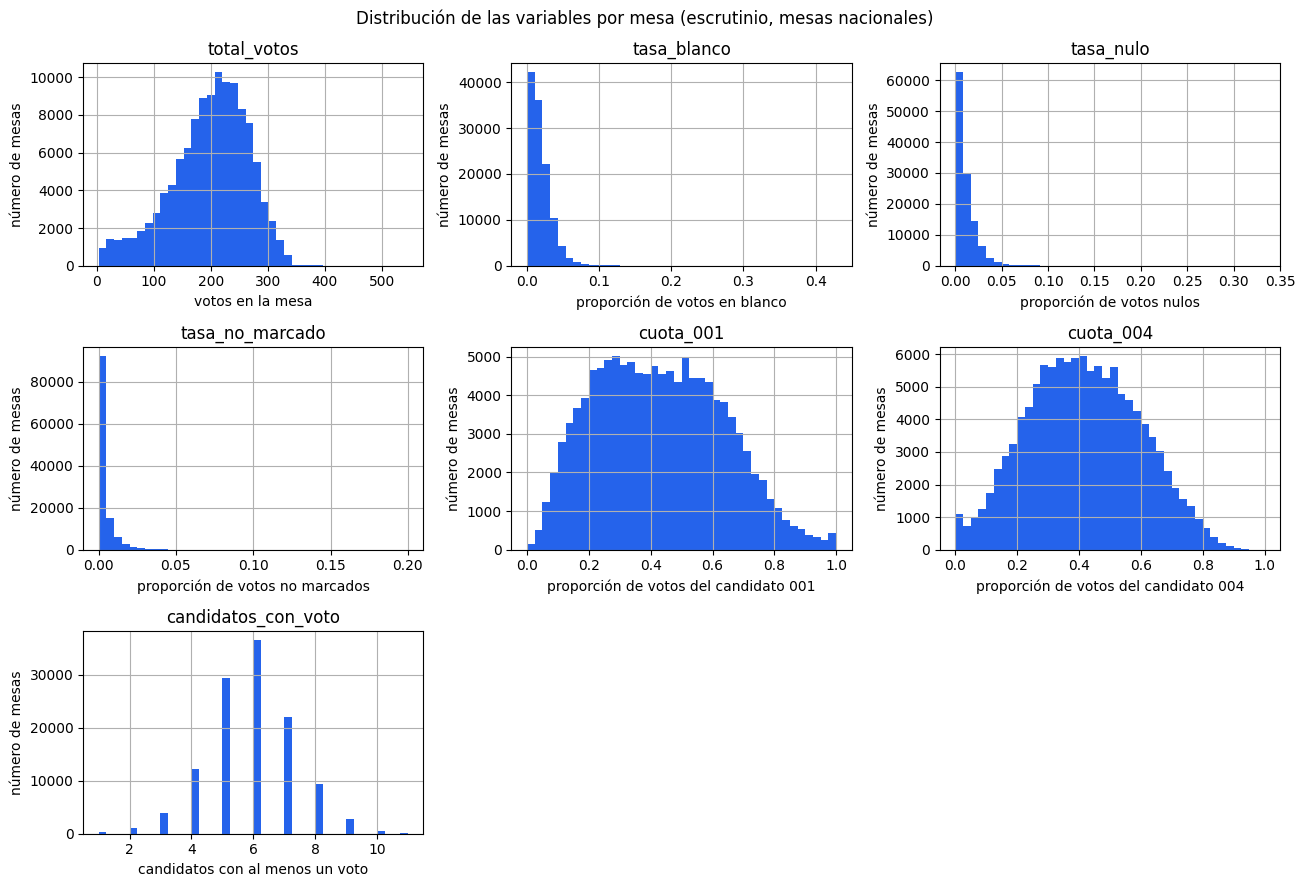

In [ ]:
# Una fila por mesa y una columna por candidatura (solo mesas nacionales con votos)
esc_w = escru.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos", aggfunc="sum")
esc_w = esc_w[esc_w.index.get_level_values("dep") != "88"]
esc_w = esc_w[esc_w.sum(axis=1) > 0]
ACTIVOS = ["001", "002", "003", "004", "005", "006", "007", "008", "010", "011", "012"]

# Variables por mesa
esc_vars = pd.DataFrame(index=esc_w.index)
esc_vars["total_votos"] = esc_w.sum(axis=1)
esc_vars["tasa_blanco"] = esc_w["996"] / esc_vars["total_votos"]
esc_vars["tasa_nulo"] = esc_w["997"] / esc_vars["total_votos"]
esc_vars["tasa_no_marcado"] = esc_w["998"] / esc_vars["total_votos"]
esc_vars["cuota_001"] = esc_w["001"] / esc_vars["total_votos"]
esc_vars["cuota_004"] = esc_w["004"] / esc_vars["total_votos"]
esc_vars["candidatos_con_voto"] = (esc_w[ACTIVOS] > 0).sum(axis=1)

# Análisis descriptivo
print("Mesas analizadas:", len(esc_vars))
display(esc_vars.describe().T.round(3))
print("\nAsimetría:")
print(esc_vars.skew().round(2))
print("\n% de mesas con tasa igual a 0:")
print((esc_vars[["tasa_blanco", "tasa_nulo", "tasa_no_marcado"]] == 0).mean().mul(100).round(1))

# Histogramas con nombres en los ejes
ETIQUETAS_X = {
    "total_votos": "votos en la mesa",
    "tasa_blanco": "proporción de votos en blanco",
    "tasa_nulo": "proporción de votos nulos",
    "tasa_no_marcado": "proporción de votos no marcados",
    "cuota_001": "proporción de votos del candidato 001",
    "cuota_004": "proporción de votos del candidato 004",
    "candidatos_con_voto": "candidatos con al menos un voto",
}

ejes = esc_vars.hist(bins=40, figsize=(13, 9), color="#2563EB")
for ax in ejes.flatten():
    if ax.get_title() in ETIQUETAS_X:
        ax.set_xlabel(ETIQUETAS_X[ax.get_title()])
        ax.set_ylabel("número de mesas")
plt.suptitle("Distribución de las variables por mesa (escrutinio, mesas nacionales)")
plt.tight_layout()
plt.show()

Además de `votos`, el escrutinio tiene tres grupos de variables:

| Variable | Tipo | ¿Se incorpora al modelo? |
|---|---|---|
| `dep`, `mun`, `zona`, `puesto`, `mesa` | Categóricas nominales y jerárquicas | No como entradas directas. Forman la llave de la mesa, y el departamento se usará para agrupar la validación cruzada. |
| `candidato` | Categórica nominal (16 valores) | Indirectamente: sus votos se resumen en las variables por mesa. |
| `partido` | Categórica nominal (14 valores) | No: cada candidato tiene un solo partido, así que repite la información de `candidato`. |
| `comunicado`, `comuna`, `corporacion`, `circ` | Constantes | No: no varían. |


Los histogramas muestran la forma de la distribución de cada variable, lo que orienta su preparación en la Fase 3: las variables muy asimétricas pueden requerir una transformación, y las que casi no varían aportan poca información al modelo.

- **`total_votos`:** votos de la mesa. Tiene forma de campana, con mediana de 206 votos y rango de 3 a 546. Su asimetría es negativa (−0,55): la cola se extiende hacia la izquierda, por las mesas con pocos votantes identificadas como atípicas bajas en la sección de calidad.
- **`tasa_blanco`, `tasa_nulo` y `tasa_no_marcado`:** proporción de votos en blanco, nulos y no marcados sobre el total de la mesa. Son valores pequeños (medianas de 1,5 %, 0,8 % y 0 %) y muy asimétricos hacia la derecha (asimetrías de 2,66, 3,28 y 4,73). Los histogramas muestran casi todas las mesas pegadas al cero: el 11,0 %, el 27,3 % y el 64,7 % de las mesas, respectivamente, no tienen ningún voto de ese tipo. Unas pocas mesas alcanzan valores altos, con máximos de 42,9 %, 33,3 % y 20 %.
- **`cuota_001` y `cuota_004`:** proporción de votos de los dos candidatos punteros. Tienen distribuciones amplias y casi simétricas (asimetrías de 0,25 y 0,07), con medias de 42,8 % y 41,5 %. Van de 0 a 1: hay mesas donde uno de los dos no obtuvo votos y mesas donde obtuvo todos. Esta amplitud confirma lo observado por departamento: la votación entre ambos varía mucho de una mesa a otra.
- **`candidatos_con_voto`:** cuántos de los 11 candidatos activos recibieron al menos un voto en la mesa. Es una variable discreta, con mediana de 6 y rango de 1 a 11; la mayoría de las mesas tiene entre 5 y 7.

Se usan tasas y cuotas en lugar de conteos para que mesas de distinto tamaño sean comparables: 5 votos nulos significan algo muy distinto en una mesa de 20 votos que en una de 300. Los conteos no se incluyen como variables adicionales porque pueden reconstruirse multiplicando cada tasa por `total_votos`, que sí se incorpora; incluir ambos daría al modelo información repetida. Esta redundancia se verifica en la sección de relación entre variables.

Las variables que se incorporarán al modelo son estas siete. Las tasas, por su fuerte asimetría, podrían requerir una transformación (por ejemplo, logarítmica) en la Fase 3.



### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

#### Escrutinio

**Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.**

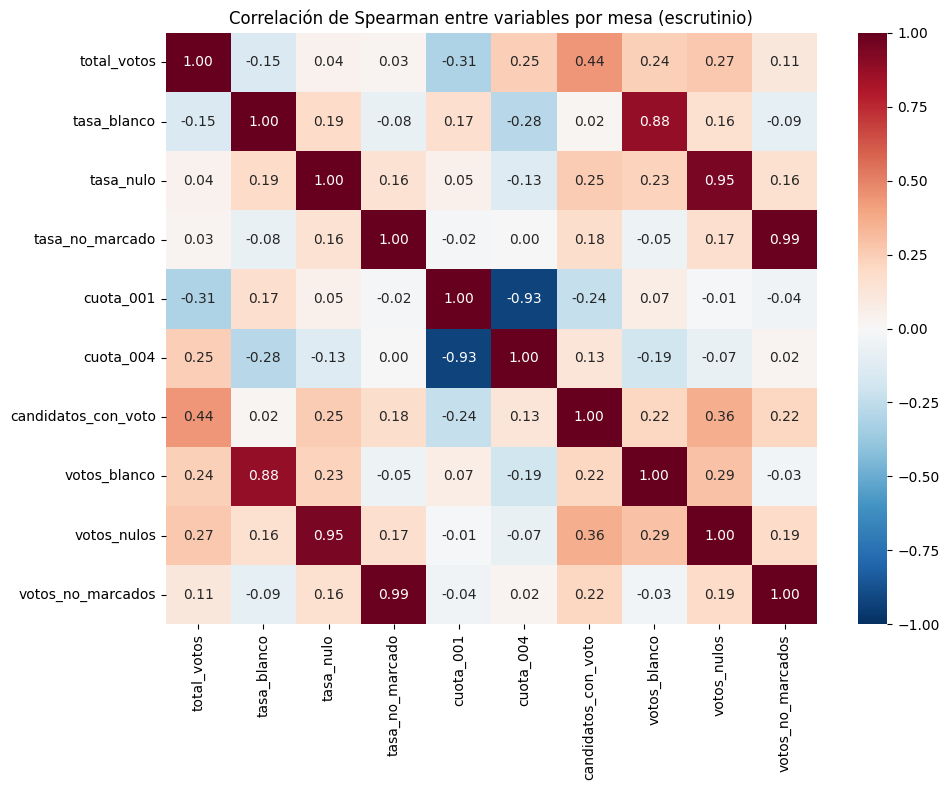

In [ ]:


# Variables de la 1.3 más los conteos, para comparar tasas contra conteos
esc_corr = esc_vars.copy()
esc_corr["votos_blanco"] = esc_w["996"]
esc_corr["votos_nulos"] = esc_w["997"]
esc_corr["votos_no_marcados"] = esc_w["998"]

corr = esc_corr.corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre variables por mesa (escrutinio)")
plt.tight_layout()
plt.show()

Para medir la relación entre las variables se usó el coeficiente de correlación de Spearman, que va de −1 a 1 y no supone relaciones lineales. Se prefirió sobre el de Pearson porque varias variables, como las tasas, son muy asimétricas, y Spearman es menos sensible a los valores extremos. Además de las siete variables por mesa, se incluyeron los conteos de votos en blanco, nulos y no marcados, para comparar tasas contra conteos.


La Figura de correlación muestra que la mayoría de las variables se relacionan poco entre sí: casi todos los coeficientes están entre −0,3 y 0,3. Esto es favorable para el modelo, porque cada variable aporta información distinta. Las relaciones más relevantes son:

- **Relaciones fuertes (|ρ| ≥ 0,85):**
  - Cada tasa con su conteo: votos no marcados (ρ = 0,99), nulos (ρ = 0,95) y en blanco (ρ = 0,88). Es esperable, porque la tasa es el conteo dividido por el total de la mesa.
  - Las cuotas de los dos candidatos punteros, con una relación negativa muy fuerte (ρ = −0,93): en las mesas donde uno obtiene más votos, el otro obtiene menos.
- **Relaciones moderadas:**
  - `total_votos` con `candidatos_con_voto` (ρ = 0,44): en las mesas con más votantes, más candidatos alcanzan a recibir al menos un voto.
  - `total_votos` con `cuota_001` (ρ = −0,31) y con `cuota_004` (ρ = 0,25): el tamaño de la mesa se asocia levemente con cómo se reparte el voto entre los punteros.

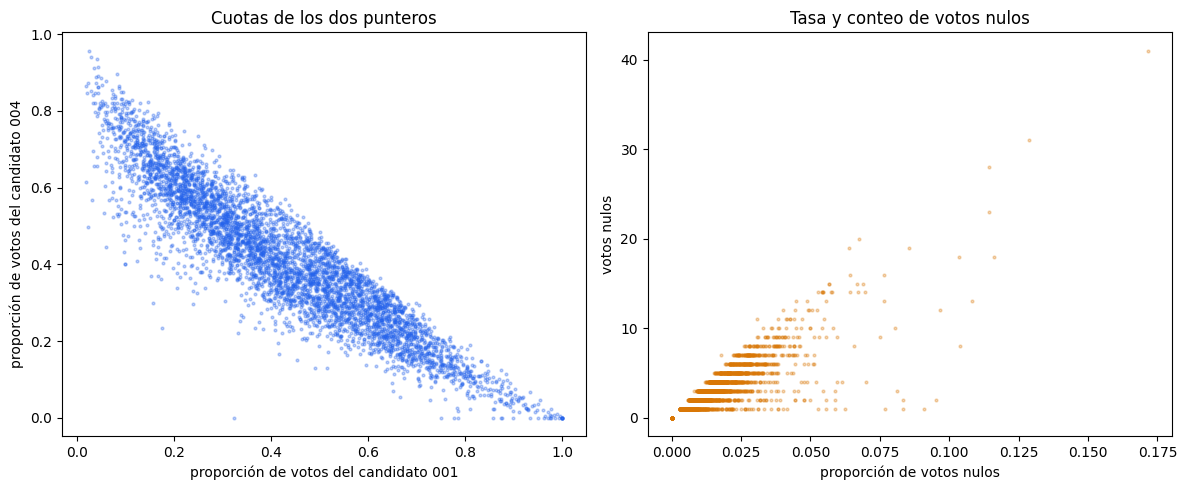

In [ ]:
muestra = esc_corr.sample(5000, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(muestra["cuota_001"], muestra["cuota_004"], s=4, alpha=0.3, color="#2563EB")
ax[0].set_xlabel("proporción de votos del candidato 001")
ax[0].set_ylabel("proporción de votos del candidato 004")
ax[0].set_title("Cuotas de los dos punteros")
ax[1].scatter(muestra["tasa_nulo"], muestra["votos_nulos"], s=4, alpha=0.3, color="#D97706")
ax[1].set_xlabel("proporción de votos nulos")
ax[1].set_ylabel("votos nulos")
ax[1].set_title("Tasa y conteo de votos nulos")
plt.tight_layout()
plt.show()

*Diagramas de dispersión de las dos relaciones más fuertes, en una muestra aleatoria de 5 000 mesas.*

La Figura hace visibles estas relaciones. A la izquierda, los puntos forman una franja descendente: cuando la cuota del candidato 001 sube, la del 004 baja casi en la misma medida. Los puntos no forman una línea perfecta porque una parte de los votos se reparte entre los demás candidatos y los votos en blanco y nulos. A la derecha, la tasa y el conteo de votos nulos crecen juntos: cada franja horizontal corresponde a un número fijo de votos nulos (1, 2, 3…) en mesas de distinto tamaño.

**Identifique si hay redundancia entre las variables para una posterior eliminación o selección.**

In [ ]:
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().reset_index()
pares.columns = ["variable_1", "variable_2", "rho"]
pares = pares[pares["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
display(pares.round(3))

,variable_1,variable_2,rho
29,tasa_no_marcado,votos_no_marcados,0.988
22,tasa_nulo,votos_nulos,0.948
30,cuota_001,cuota_004,-0.928
14,tasa_blanco,votos_blanco,0.875


Se consideran redundantes los pares de variables con una correlación de Spearman mayor que 0,8 en valor absoluto, porque en ese caso una variable repite casi toda la información de la otra. Se identificaron cuatro pares:

| Par redundante | ρ | Decisión |
|---|---|---|
| `tasa_no_marcado` – `votos_no_marcados` | 0,99 | Conservar la tasa |
| `tasa_nulo` – `votos_nulos` | 0,95 | Conservar la tasa |
| `cuota_001` – `cuota_004` | −0,93 | Conservar una sola cuota |
| `tasa_blanco` – `votos_blanco` | 0,88 | Conservar la tasa |

**Tasas frente a conteos.** Los tres conteos son redundantes con sus tasas, lo que confirma la decisión de la sección anterior de no incluirlos: además, pueden reconstruirse multiplicando la tasa por `total_votos`. Se conservan las tasas porque permiten comparar mesas de distinto tamaño.

**Cuotas de los punteros.** Las cuotas de los candidatos 001 y 004 se mueven casi como espejo, así que una de las dos basta para describir cómo se reparte el voto entre ambos. Se propone conservar solo una, o reemplazar ambas por su diferencia, que resume el margen entre los dos candidatos en una sola variable. La elección se hará en la Fase 3.

Con estas decisiones, el conjunto final de variables por mesa del escrutinio queda en seis variables no redundantes: `total_votos`, `tasa_blanco`, `tasa_nulo`, `tasa_no_marcado`, una cuota de los punteros (o su diferencia) y `candidatos_con_voto`.

Esta selección es útil sobre todo para modelos como la regresión logística, que se vuelven inestables cuando reciben variables casi idénticas. Los modelos basados en árboles, como Random Forest, toleran mejor la redundancia, pero eliminarla igualmente simplifica la interpretación de los resultados.

## **1. Análisis Exploratorio de los Datos Novedades**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

In [ ]:
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

'id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,corporacionNombre,potencial,sufragantesSegunE11,enTerminos,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos\n'
'010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,PRESIDENTE,360,128,SI,BUENO,NO,NO,NO,NO,6,128,0,128,127\n'
'010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,PRESIDENTE,360,65,SI,BUENO,NO,NO,NO,NO,6,65,0,65,65\n'


### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

In [ ]:
noved.head()

,id,dep,departamentoNombre,mun,municipioNombre,zona,puesto,puestoNombre,mesa,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000001,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000002,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000003,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000004,001,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000005,001,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


**¿Cuántos documentos tiene el *dataset*?**

In [ ]:
print("Registros:", len(noved), "| columnas:", noved.shape[1])
print("Mesas repetidas:", noved.duplicated(LLAVE_MESA).sum())
print("Departamentos:", noved["dep"].nunique())
print("Corporaciones:", noved["corporacionNombre"].unique())

# ¿Qué mesas del escrutinio tienen registro de novedades?
mesas_esc = escru[LLAVE_MESA].drop_duplicates()
cobertura = mesas_esc.merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)
print("\nCobertura frente a las 122 020 mesas del escrutinio:")
print(cobertura["_merge"].map({"both": "con novedades", "left_only": "sin novedades"}).value_counts())
print("Departamentos de las mesas sin novedades:", cobertura.loc[cobertura["_merge"] == "left_only", "dep"].unique())

Registros: 118350 | columnas: 24
Mesas repetidas: 0
Departamentos: 33
Corporaciones: ['PRESIDENTE']

Cobertura frente a las 122 020 mesas del escrutinio:
_merge
con novedades    118350
sin novedades      3670
Name: count, dtype: int64
Departamentos de las mesas sin novedades: ['88']


El archivo de novedades contiene **118 350 registros** y 24 columnas. A diferencia del preconteo y del escrutinio, aquí cada registro corresponde a **una mesa completa**, no a una candidatura, y no hay mesas repetidas. El archivo no registra votos por candidato, sino cómo se desarrolló el proceso en cada mesa: por ejemplo, cuántos votantes firmaron el formulario E-11, cuántos votos había en la urna, cuántos jurados firmaron el acta y si la mesa fue recontada o excluida.

Al cruzarlo con las 122 020 mesas del escrutinio, las 118 350 mesas de novedades coinciden una a una con mesas del escrutinio. Las 3 670 mesas restantes son todas de consulados (departamento 88): el archivo cubre únicamente las **mesas nacionales** de los 33 departamentos, incluido Bogotá. Además, solo contiene la corporación PRESIDENTE.

In [ ]:
# ¿Coinciden los votos en la urna con los votantes del E-11?
coinciden = noved["votosUrna"] == noved["sufragantesSegunE11"]
print("\nMesas donde votos en la urna = votantes del E-11:", coinciden.sum(),
      f"({coinciden.mean() * 100:.1f} %)")
print("Mesas con más votos en la urna que votantes:", (noved["votosUrna"] > noved["sufragantesSegunE11"]).sum())
print("Mesas con menos votos en la urna que votantes:", (noved["votosUrna"] < noved["sufragantesSegunE11"]).sum())


Mesas donde votos en la urna = votantes del E-11: 112628 (95.2 %)
Mesas con más votos en la urna que votantes: 1642
Mesas con menos votos en la urna que votantes: 4080


lo anterior muestra que la gran mayoría de las mesas está sobre una curva principal, donde los votos en la urna son iguales a los votantes del E-11: así ocurre en 112 628 mesas (95,2 %). En las demás, 1 642 tienen más votos en la urna que votantes y 4 080 tienen menos. Fuera de esa curva aparecen tres patrones de error de registro:

Para identificar datos de baja calidad se aplicaron reglas de validación que un dato correcto siempre debe cumplir: **completitud** (no hay valores nulos ni vacíos), **rango** (los conteos no son negativos ni superan el máximo de votantes de la mesa), **coherencia entre campos** (no hay más votos que votantes, y los votos en la urna coinciden con los votantes del E-11),

**¿En qué formato están almacenados los datos?**

In [ ]:
noved.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118350 entries, 0 to 118349
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   id                      118350 non-null  object
 1   dep                     118350 non-null  object
 2   departamentoNombre      118350 non-null  object
 3   mun                     118350 non-null  object
 4   municipioNombre         118350 non-null  object
 5   zona                    118350 non-null  object
 6   puesto                  118350 non-null  object
 7   puestoNombre            118350 non-null  object
 8   mesa                    118350 non-null  object
 9   corporacionCodigo       118350 non-null  object
 10  corporacionNombre       118350 non-null  object
 11  potencial               118350 non-null  int64 
 12  sufragantesSegunE11     118350 non-null  int64 
 13  enTerminos              118350 non-null  object
 14  estadoSobre             118350 non-n

In [ ]:
nov_diccionario = pd.DataFrame([
    ("id",                     "Texto",                  "Identificador de la mesa"),
    ("dep",                    "Código",                 "Código del departamento (columna original: departamentoCodigo)"),
    ("departamentoNombre",     "Texto",                  "Nombre del departamento"),
    ("mun",                    "Código",                 "Código del municipio (columna original: municipioCodigo)"),
    ("municipioNombre",        "Texto",                  "Nombre del municipio"),
    ("zona",                   "Código",                 "Código de la zona (columna original: zonaNombre)"),
    ("puesto",                 "Código",                 "Código del puesto (columna original: puestoCodigo)"),
    ("puestoNombre",           "Texto",                  "Nombre del puesto de votación"),
    ("mesa",                   "Código",                 "Número de la mesa (columna original: mesaNumero)"),
    ("corporacionCodigo",      "Código",                 "Cargo que se elige; 001 = Presidente"),
    ("corporacionNombre",      "Texto",                  "Nombre del cargo"),
    ("potencial",              "Numérico",               "Máximo de votantes permitido en la mesa"),
    ("sufragantesSegunE11",    "Numérico",               "Votantes registrados en el formulario E-11"),
    ("enTerminos",             "Categórico (SI/NO)",     "Si los documentos de la mesa se entregaron dentro de los plazos"),
    ("estadoSobre",            "Categórico (BUENO/MAL)", "Estado del sobre con los documentos de la mesa"),
    ("tachadurasEnmendaduras", "Categórico (SI/NO)",     "Si el acta presenta tachaduras o enmendaduras"),
    ("recontadaJurados",       "Categórico (SI/NO)",     "Si los jurados recontaron los votos de la mesa"),
    ("recontadaComision",      "Categórico (SI/NO)",     "Si la comisión escrutadora recontó los votos"),
    ("excluida",               "Categórico (SI/NO)",     "Si la mesa fue excluida del cómputo"),
    ("firmasJurados",          "Numérico",               "Número de firmas de jurados en el acta (0 a 6)"),
    ("votosUrna",              "Numérico",               "Votos encontrados en la urna"),
    ("votosIncinerados",       "Numérico",               "Votos sobrantes destruidos"),
    ("sufragantesE11SegunE14", "Numérico",               "Votantes del E-11 según lo registrado en el acta E-14"),
    ("totalVotos",             "Numérico",               "Total de votos de la mesa"),
], columns=["columna", "tipo", "descripcion"])

nov_diccionario["tipo_pandas"]    = nov_diccionario["columna"].map(noved.dtypes.astype(str))
nov_diccionario["valores_unicos"] = nov_diccionario["columna"].map(noved.nunique())
nov_diccionario["ejemplo"]        = nov_diccionario["columna"].map(noved.iloc[0])
nov_diccionario = nov_diccionario[["columna", "tipo", "tipo_pandas", "valores_unicos", "ejemplo", "descripcion"]]
display(nov_diccionario)

,columna,tipo,tipo_pandas,valores_unicos,ejemplo,descripcion
0,id,Texto,object,118350,010100101011,Identificador de la mesa
1,dep,Código,object,33,01,Código del departamento (columna original: dep...
2,departamentoNombre,Texto,object,33,ANTIOQUIA,Nombre del departamento
3,mun,Código,object,263,001,Código del municipio (columna original: munici...
4,municipioNombre,Texto,object,1036,MEDELLIN,Nombre del municipio
5,zona,Código,object,42,001,Código de la zona (columna original: zonaNombre)
6,puesto,Código,object,208,01,Código del puesto (columna original: puestoCod...
7,puestoNombre,Texto,object,10485,SEC. ESC. LA ESPERANZA No 2,Nombre del puesto de votación
8,mesa,Código,object,228,000001,Número de la mesa (columna original: mesaNumero)
9,corporacionCodigo,Código,object,1,001,Cargo que se elige; 001 = Presidente


In [ ]:
nov_resumen = pd.Series(dtype=object, data={
    "Registros (mesas)": len(noved),
    "Columnas": noved.shape[1],
    "Mesas repetidas": noved.duplicated(LLAVE_MESA).sum(),
    "Departamentos": noved["dep"].nunique(),
    "Mesas de consulados (dep 88)": (noved["dep"] == "88").sum(),
    "Corporaciones": noved["corporacionNombre"].unique().tolist(),
    "Tamaño en disco (MB)": round(os.path.getsize(ARCH_NOVEDADES) / 1024**2, 2),
    "Tamaño en memoria (MB)": round(noved.memory_usage(deep=True).sum() / 1024**2, 1),
})
display(nov_resumen.to_frame("valor"))

,valor
Registros (mesas),118350
Columnas,24
Mesas repetidas,0
Departamentos,33
Mesas de consulados (dep 88),0
Corporaciones,[PRESIDENTE]
Tamaño en disco (MB),14.9
Tamaño en memoria (MB),111.5


In [ ]:
# Primeras líneas tal como vienen en el archivo
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

# Líneas con comas dentro del nombre del puesto
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    encabezado = f.readline().rstrip("\r\n").split(",")
    lineas_con_comas = sum(len(l.rstrip("\r\n").split(",")) > len(encabezado) for l in f)
print("\nColumnas en el encabezado:", len(encabezado))
print("Líneas con comas dentro del nombre del puesto:", lineas_con_comas)
print("Ejemplo reparado:", noved.loc[noved["puestoNombre"].str.contains(",", regex=False), "puestoNombre"].iloc[0])

# Efecto de la codificación sobre los nombres
ejemplo = noved.loc[noved["puestoNombre"].str.contains("Ñ"), "puestoNombre"].iloc[0]
print("\nLeído en UTF-8:  ", ejemplo)
print("Leído en latin-1:", ejemplo.encode("utf-8").decode("latin-1"))

'id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,corporacionNombre,potencial,sufragantesSegunE11,enTerminos,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos\n'
'010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,PRESIDENTE,360,128,SI,BUENO,NO,NO,NO,NO,6,128,0,128,127\n'
'010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,PRESIDENTE,360,65,SI,BUENO,NO,NO,NO,NO,6,65,0,65,65\n'

Columnas en el encabezado: 24
Líneas con comas dentro del nombre del puesto: 45
Ejemplo reparado: I.E.D.LA PAZ, MEGA COL. LA PAZ

Leído en UTF-8:   I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO
Leído en latin-1: I.E. MONSEÃOR FRANCISCO CRISTOBAL TORO


Es un archivo de valores separados por comas (`.csv`), **con encabezado** y codificado en **UTF-8**, distribuido dentro del comprimido `Novedad20260603.zip` junto con su huella SHA-256. Se diferencia de las otras fuentes en cuatro aspectos:

- **No está descrito en el documento *Estructuras Básicas*.** Por eso la tabla anterior no tiene tipos ni longitudes oficiales: el diccionario de columnas se construyó a partir del nombre de cada campo y de sus valores, y debe tomarse como una interpretación del grupo.
- **Incluye nombres, no solo códigos.** Trae el nombre del departamento, del municipio y del puesto, que contienen tildes y eñes. Por eso la codificación sí importa en este archivo: como muestra la salida anterior, al leerlo en latin-1 (como se hacía en la Fase 1) la Ñ de "MONSEÑOR" se convierte en caracteres extraños. En esta fase la lectura se corrigió a UTF-8.
- **Algunos nombres de puesto contienen comas.** En 45 líneas, el nombre del puesto incluye comas sin comillas (por ejemplo, "I.E.D.LA PAZ, MEGA COL. LA PAZ"), que se confunden con el separador de columnas. La carga las repara uniendo esos fragmentos, sin descartar ninguna mesa.
- **Las llaves tienen otro formato.** En el archivo original la zona tiene 2 dígitos y la mesa no tiene ceros a la izquierda (`1` en lugar de `000001`). Durante la carga se renombraron las columnas de llave (por ejemplo, `departamentoCodigo` → `dep`) y se completaron con ceros, para que coincidan con las del escrutinio.

Las 24 columnas se agrupan en cuatro tipos: **identificación de la mesa** (códigos y nombres de departamento, municipio, zona, puesto y mesa), **corporación** (constante), **seis variables categóricas** que registran novedades del proceso, con valores SI/NO o BUENO/MAL, y **siete variables numéricas** con conteos de votantes, votos y firmas. Las llaves y las categorías se conservan como texto (`object`) y los conteos como enteros (`int64`).

**¿Qué tamaño en MB tiene el conjunto de datos?**

In [ ]:
print("En disco (CSV):  ", round(os.path.getsize(ARCH_NOVEDADES) / 1024**2, 2), "MB")
print("Comprimido (ZIP):", round(os.path.getsize(buscar_archivo("Novedad20260603.zip")) / 1024**2, 2), "MB")
print("En memoria:      ", round(noved.memory_usage(deep=True).sum() / 1024**2, 1), "MB")

En disco (CSV):   14.9 MB
Comprimido (ZIP): 2.02 MB
En memoria:       111.5 MB


El archivo ocupa **14,9 MB en disco** y apenas **2 MB comprimido**. Una vez cargado en *pandas* ocupa unos **111 MB en memoria**, porque las columnas de texto, en especial los nombres de puesto, almacenan cada valor como un objeto independiente. Es la fuente más liviana de las tres, porque tiene una sola fila por mesa y no una por candidatura.

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

**¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad?**

Valores nulos: 0
Celdas vacías: 0


,count,mean,std,min,25%,50%,75%,max
potencial,118350.0,364.7,52.1,360.0,360.0,360.0,360.0,1200.0
sufragantesSegunE11,118350.0,198.1,68.2,0.0,157.0,206.0,247.0,800.0
firmasJurados,118350.0,5.9,0.4,0.0,6.0,6.0,6.0,6.0
votosUrna,118350.0,199.3,92.0,0.0,157.0,206.0,247.0,8195.0
votosIncinerados,118350.0,0.1,3.3,0.0,0.0,0.0,0.0,360.0
sufragantesE11SegunE14,118350.0,198.3,69.6,0.0,157.0,206.0,247.0,3025.0
totalVotos,118350.0,197.7,68.1,0.0,157.0,206.0,247.0,546.0


Valores negativos: 0
votosUrna mayor que el máximo de la mesa: 112
E-14 mayor que el máximo de la mesa: 6
Más votos que votantes (totalVotos > E-11): 2
Mesas excluidas con totalVotos = 0: 37 de 37


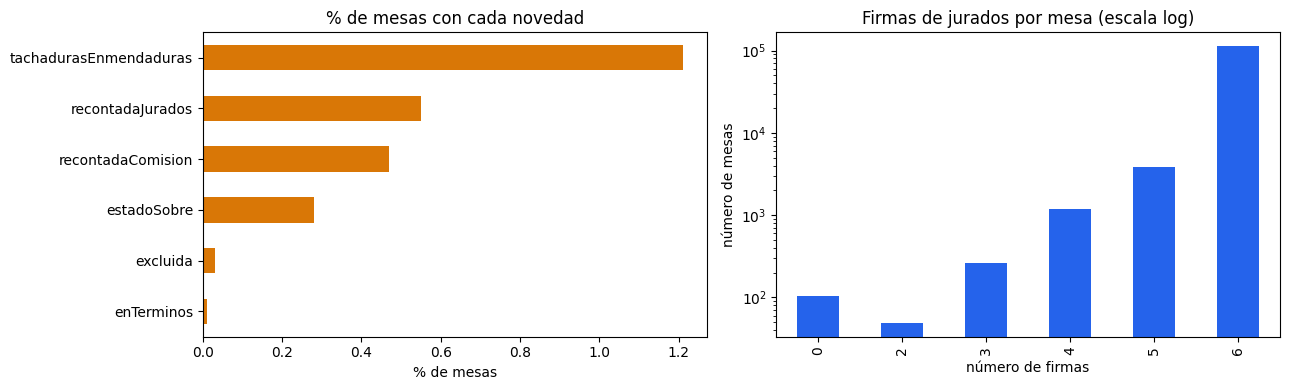

In [ ]:
print("Valores nulos:", noved.isnull().sum().sum())
print("Celdas vacías:", (noved.select_dtypes(exclude="number") == "").sum().sum())

NUM = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
       "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
display(noved[NUM].describe().T.round(1))

print("Valores negativos:", (noved[NUM] < 0).sum().sum())
print("votosUrna mayor que el máximo de la mesa:", (noved["votosUrna"] > noved["potencial"]).sum())
print("E-14 mayor que el máximo de la mesa:", (noved["sufragantesE11SegunE14"] > noved["potencial"]).sum())
print("Más votos que votantes (totalVotos > E-11):", (noved["totalVotos"] > noved["sufragantesSegunE11"]).sum())
print("Mesas excluidas con totalVotos = 0:",
      ((noved["excluida"] == "SI") & (noved["totalVotos"] == 0)).sum(), "de", (noved["excluida"] == "SI").sum())

NOVEDAD = {"enTerminos": "NO", "estadoSobre": "MAL", "tachadurasEnmendaduras": "SI",
           "recontadaJurados": "SI", "recontadaComision": "SI", "excluida": "SI"}
pct = pd.Series({c: (noved[c] == v).mean() * 100 for c, v in NOVEDAD.items()}).round(2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pct.sort_values().plot.barh(ax=ax[0], color="#D97706")
ax[0].set_title("% de mesas con cada novedad")
ax[0].set_xlabel("% de mesas")
noved["firmasJurados"].value_counts().sort_index().plot.bar(ax=ax[1], color="#2563EB")
ax[1].set_yscale("log")
ax[1].set_title("Firmas de jurados por mesa (escala log)")
ax[1].set_xlabel("número de firmas")
ax[1].set_ylabel("número de mesas")
plt.tight_layout()
plt.show()

**Datos ausentes y documentos vacíos.** No hay valores nulos ni celdas vacías: las 118 350 mesas tienen las 24 columnas diligenciadas. Las 37 mesas excluidas tienen `totalVotos` igual a cero, lo que coincide con las 37 mesas vacías encontradas en el escrutinio: la exclusión anuló su votación.

**Datos de baja calidad.** No hay valores negativos, pero sí valores imposibles:

- **112 mesas registran más votos en la urna que el máximo de votantes permitido en la mesa.** El caso extremo es una mesa con 8 195 votos en la urna, cuando su máximo es 360. En la pregunta 4 se muestra que la mayoría corresponde a errores de digitación.
- **6 mesas** registran en el acta E-14 más sufragantes que el máximo de la mesa, y **2 mesas** tienen más votos totales que votantes según el E-11.
- **El campo `potencial` no es el número de votantes inscritos en la mesa**, sino el **máximo permitido** según el tipo de puesto: solo toma cuatro valores (360, 500, 800 y 1 200), y el 98,9 % de las mesas tiene 360. Por eso no sirve para calcular la participación real de cada mesa.

La figura anterior muestra que las novedades son **poco frecuentes**: la más común son las tachaduras o enmendaduras en el acta (1,21 % de las mesas), seguida del reconteo por los jurados (0,55 %) y por la comisión escrutadora (0,47 %); las demás afectan a menos del 0,3 %. Esto anticipa que, si se usan como etiqueta, habrá un fuerte desbalance de clases.

En las firmas, 112 910 mesas (95,4 %) tienen las seis firmas de jurados, pero 5 440 tienen menos y **104 mesas no tienen ninguna**. Un acta sin firmas es una debilidad documental, aunque no necesariamente un error en los conteos.

**¿Se identifican documentos ilegibles o con dificultades de codificación?**

In [ ]:
texto = noved.select_dtypes(exclude="number").columns
print("Valores con caracteres mal decodificados (Ã):",
      noved[texto].apply(lambda s: s.str.contains("Ã", regex=False).sum()).sum())
print("Nombres de puesto con tildes o eñes:", noved["puestoNombre"].str.contains(r"[ÁÉÍÓÚÑÜ]").sum())
print(noved.loc[noved["puestoNombre"].str.contains(r"[ÁÉÍÓÚÑÜ]"), "puestoNombre"].head(3).tolist())

Valores con caracteres mal decodificados (Ã): 0
Nombres de puesto con tildes o eñes: 4996
['I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO', 'I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO', 'I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO']


El archivo no es ilegible, pero **sí presentó una dificultad de codificación**. Está codificado en UTF-8, mientras que las demás fuentes del paquete usan latin-1. En la Fase 1 se leía en latin-1, lo que dañaba los nombres con tildes y eñes (como se mostró en el resumen general, "MONSEÑOR" aparecía con caracteres extraños). Con la lectura corregida a UTF-8, ningún valor contiene caracteres mal decodificados, y los 4 996 nombres de puesto con tildes o eñes se leen correctamente.

La otra dificultad de lectura son las **45 líneas** cuyo nombre de puesto contiene comas sin comillas, que se confunden con el separador de columnas. Como se explicó en el resumen general, la carga las repara sin descartar ninguna mesa.

Este problema afecta solo a los nombres, no a los códigos ni a los conteos, por lo que no altera el cruce con las demás fuentes ni los análisis numéricos.

**¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?**

In [ ]:
print("Longitud del id:", noved["id"].str.len().value_counts().sort_index().to_dict())
display(noved[["id", "dep", "mun", "zona", "puesto", "mesa"]].iloc[[0, 500]])

print("\nValores de las variables categóricas:")
for c in NOVEDAD:
    print(f"  {c}: {sorted(noved[c].unique())}")
print("Valores distintos de potencial:", sorted(noved["potencial"].unique()))

print("\nCombinaciones departamento–municipio:", noved[["dep", "mun"]].drop_duplicates().shape[0])
print("Nombres de municipio distintos:", noved["municipioNombre"].nunique())
rep = noved[["dep", "municipioNombre"]].drop_duplicates().groupby("municipioNombre").size()
print("Nombres repetidos en varios departamentos:", rep[rep > 1].sort_values(ascending=False).head(5).to_dict())

Longitud del id: {12: 64608, 13: 53613, 14: 129}


,id,dep,mun,zona,puesto,mesa
0,010100101011,01,001,001,01,000001
500,0101001040210,01,001,004,02,000010



Valores de las variables categóricas:
  enTerminos: ['NO', 'SI']
  estadoSobre: ['BUENO', 'MAL']
  tachadurasEnmendaduras: ['NO', 'SI']
  recontadaJurados: ['NO', 'SI']
  recontadaComision: ['NO', 'SI']
  excluida: ['NO', 'SI']
Valores distintos de potencial: [np.int64(360), np.int64(500), np.int64(800), np.int64(1200)]

Combinaciones departamento–municipio: 1122
Nombres de municipio distintos: 1036
Nombres repetidos en varios departamentos: {'BOLIVAR': 4, 'BUENAVISTA': 4, 'LA UNION': 4, 'VILLANUEVA': 4, 'EL CARMEN': 3}


Sí. Aunque todas las líneas tienen las mismas 24 columnas, dentro del archivo conviven formatos que dificultan su uso si no se conocen:

- **Identificador de longitud variable.** La columna `id` tiene 12, 13 o 14 caracteres, porque concatena los códigos de la mesa sin completar el número de mesa con ceros (la mesa 1 aporta un dígito y la mesa 10, dos). Por eso no se usa como llave: las fuentes se cruzan con los cinco códigos de la mesa, ya normalizados.
- **Nombres de columna engañosos.** La columna original `zonaNombre` no contiene nombres sino códigos de zona, y `mesaNumero` trae el número sin ceros a la izquierda (`1` en lugar de `000001`). Ambas se renombraron y normalizaron en la carga.
- **Dos vocabularios en las variables categóricas.** Cinco campos usan SI/NO y `estadoSobre` usa BUENO/MAL. Además, en `enTerminos` la novedad es la respuesta NO, mientras que en los demás es SI. Esto obliga a definir con cuidado qué valor indica una novedad antes de convertirlos a 0/1.
- **Nombres de municipio repetidos.** Hay 1 122 combinaciones de departamento y municipio, pero solo 1 036 nombres distintos, porque varios municipios comparten nombre en distintos departamentos (por ejemplo, hay cuatro llamados Bolívar y cuatro llamados Buenavista). Por eso las mesas deben identificarse por código y no por nombre.
- **Un campo cuyo nombre no refleja su contenido.** `potencial` sugiere el número de votantes inscritos, pero contiene el máximo permitido por mesa (cuatro valores posibles).

**¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?**

sufragantesSegunE11: límites [22, 382] | atípicas bajas: 1446 | altas: 58
votosUrna: límites [22, 382] | atípicas bajas: 1535 | altas: 167
sufragantesE11SegunE14: límites [22, 382] | atípicas bajas: 1497 | altas: 65
totalVotos: límites [22, 382] | atípicas bajas: 1482 | altas: 56


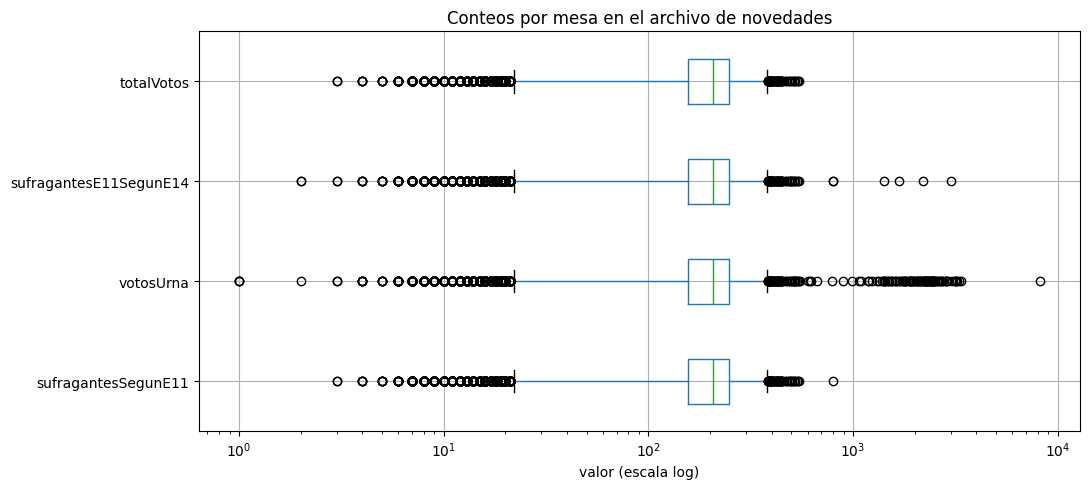

In [ ]:
CONTEOS = ["sufragantesSegunE11", "votosUrna", "sufragantesE11SegunE14", "totalVotos"]

for c in CONTEOS:
    Q1 = noved[c].quantile(0.25)
    Q3 = noved[c].quantile(0.75)
    IQR = Q3 - Q1
    print(f"{c}: límites [{Q1 - 1.5 * IQR:.0f}, {Q3 + 1.5 * IQR:.0f}] | "
          f"atípicas bajas: {(noved[c] < Q1 - 1.5 * IQR).sum()} | altas: {(noved[c] > Q3 + 1.5 * IQR).sum()}")

fig, ax = plt.subplots(figsize=(11, 5))
noved[CONTEOS].boxplot(ax=ax, vert=False)
ax.set_xscale("log")
ax.set_xlabel("valor (escala log)")
ax.set_title("Conteos por mesa en el archivo de novedades")
plt.tight_layout()
plt.show()

Las gráficas usan escala logarítmica porque los valores van de unos pocos votos hasta más de 8 000: en escala lineal, las mesas normales quedarían comprimidas y no se distinguirían. Esta escala no puede representar el valor cero, por lo que las mesas sin votos (analizadas en la pregunta 1) no aparecen en estas figuras.

**Valores atípicos por variable.** Se aplicó el criterio del rango intercuartílico (IQR) a los cuatro conteos de la mesa. Los cuatro tienen los mismos límites (22 y 382) y cajas casi idénticas, lo que confirma que en la mayoría de las mesas registran el mismo número.

Diagramas de caja de los conteos por mesa del archivo de novedades, en escala logarítmica.


La diferencia está en los atípicos altos: `votosUrna` tiene 167, frente a 56 de `totalVotos`, y su cola llega hasta 8 195, un valor imposible. El conteo de votantes anotado en el E-14 (`sufragantesE11SegunE14`) también presenta valores imposibles en 6 mesas, con un máximo de 3 025 en una mesa cuyo máximo permitido es 360. En esas mesas, el total de votos sí coincide con los votantes del E-11, lo que indica un error de registro similar al de los votos en la urna, aunque mucho menos frecuente.

Los atípicos bajos, en cambio, aparecen en las cuatro variables a la vez y con valores coherentes entre sí: son mesas con pocos votantes, no errores. Es el mismo patrón observado en el escrutinio.

Sin embargo, el diagrama de caja analiza cada variable por separado, así que no detecta las mesas donde dos conteos que deberían coincidir son distintos pero ambos están dentro del rango normal (por ejemplo, 200 votantes y 195 votos en la urna). Por eso, a continuación se comparan directamente los votos en la urna con los votantes del E-11.

Mesas duplicadas: 0 | id duplicados: 0

votosUrna mayor que el máximo de la mesa: 112 | con un dígito de más al final: 77


,sufragantesSegunE11,votosUrna,totalVotos
397,251,2500,250
696,264,664,264
1209,226,2266,226
1272,173,1730,173
1407,230,2300,230



Mesas con E-11 igual al máximo de la mesa: 143 | mediana de votos en la urna en esas mesas: 221.0

totalVotos igual al total del escrutinio: 100.0 %


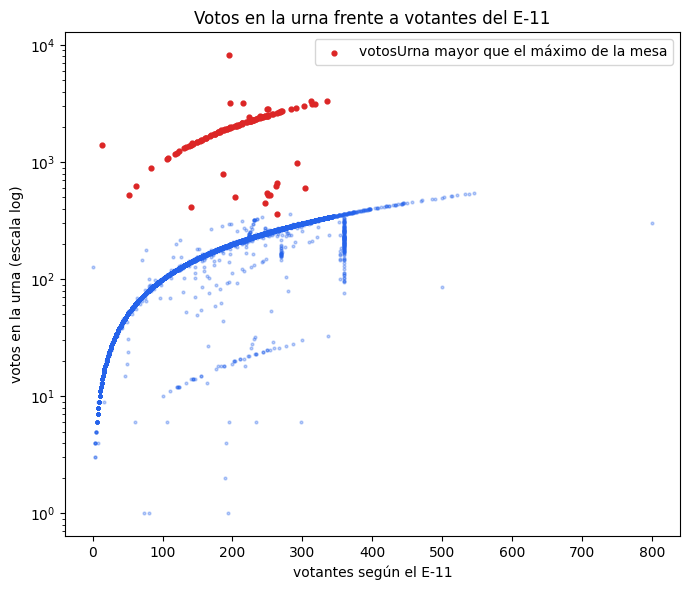

In [ ]:
print("Mesas duplicadas:", noved.duplicated(LLAVE_MESA).sum(), "| id duplicados:", noved["id"].duplicated().sum())

# Votos en la urna imposibles
sospechosas = noved[noved["votosUrna"] > noved["potencial"]]
digito_final = (sospechosas["votosUrna"] // 10 == sospechosas["sufragantesSegunE11"]).sum()
print("\nvotosUrna mayor que el máximo de la mesa:", len(sospechosas),
      "| con un dígito de más al final:", digito_final)
display(sospechosas[["sufragantesSegunE11", "votosUrna", "totalVotos"]].head())

# E-11 igual al máximo de la mesa
e11_tope = noved[noved["sufragantesSegunE11"] == noved["potencial"]]
print("\nMesas con E-11 igual al máximo de la mesa:", len(e11_tope),
      "| mediana de votos en la urna en esas mesas:", e11_tope["votosUrna"].median())

# Coincidencia de totalVotos con el escrutinio
esc_total = escru.groupby(LLAVE_MESA)["votos"].sum().rename("total_escrutinio")
cruce = noved.join(esc_total, on=LLAVE_MESA)
print("\ntotalVotos igual al total del escrutinio:",
      round((cruce["totalVotos"] == cruce["total_escrutinio"]).mean() * 100, 1), "%")

plt.figure(figsize=(7, 6))
plt.scatter(noved["sufragantesSegunE11"], noved["votosUrna"], s=4, alpha=0.3, color="#2563EB")
plt.scatter(sospechosas["sufragantesSegunE11"], sospechosas["votosUrna"], s=12, color="#DC2626",
            label="votosUrna mayor que el máximo de la mesa")
plt.yscale("log")
plt.xlabel("votantes según el E-11")
plt.ylabel("votos en la urna (escala log)")
plt.title("Votos en la urna frente a votantes del E-11")
plt.legend()
plt.tight_layout()
plt.show()

**Duplicados y faltantes.** No hay mesas duplicadas ni identificadores repetidos, y no hay datos faltantes (pregunta 1).

**Valores atípicos.** Para analizarlos se comparan los votos en la urna con los votantes registrados en el formulario E-11, porque en una mesa normal ambos deben coincidir.

*Figura: votos en la urna frente a votantes del E-11 por mesa, con escala logarítmica en el eje vertical (elaboración propia).*

La figura anterior muestra que la gran mayoría de las mesas está sobre una curva principal, donde los votos en la urna son iguales a los votantes del E-11 (así ocurre en el 95,2 % de las mesas). Fuera de esa curva aparecen tres patrones de error de registro:

- **Un dígito de más (puntos rojos).** Las 112 mesas con más votos en la urna que el máximo permitido forman una curva paralela, unas diez veces por encima de la principal. En 77 de ellas el valor es exactamente el número de votantes con un dígito agregado al final (por ejemplo, 173 votantes y 1 730 votos en la urna), lo que indica un error de digitación y no votos reales. Así lo confirma `totalVotos`, que en esas mesas sí coincide con los votantes.
- **Un dígito de menos.** Una línea más débil, unas diez veces por debajo de la principal, sugiere el error contrario: votos en la urna registrados con un dígito faltante.
- **E-11 igual al máximo de la mesa.** La columna vertical en 360 corresponde a 143 mesas cuyo número de votantes del E-11 es exactamente el máximo permitido, aunque la mediana de votos en la urna en esas mesas es de solo 223. Esto sugiere que en esas mesas se registró el máximo de la mesa en lugar del número real de votantes.

Estos valores no se eliminan en esta fase. Se documentan para corregirlos o marcarlos en la preparación de los datos (Fase 3). Son importantes porque `sufragantesSegunE11` se usará para comparar con el preconteo, y un error en este campo podría confundirse con una discrepancia real.

**Fuga de información.** La columna `totalVotos` coincide con el total del escrutinio en el 100 % de las mesas: es el resultado final, no una novedad del proceso. Por eso no podrá usarse como variable de entrada en un modelo que prediga discrepancias entre preconteo y escrutinio, porque le daría al modelo la respuesta.

**Conclusión sobre la calidad del archivo de novedades.** El archivo está completo (sin valores faltantes ni mesas duplicadas), pero exige cuidados antes de usarlo en el modelo: el número de votantes del E-11 presenta registros dudosos en 143 mesas, los votos en la urna tienen errores de digitación en al menos 156 mesas (112 con un dígito de más y 44 con uno de menos), el campo `potencial` corresponde al máximo por mesa y no al número de inscritos, y `totalVotos` reproduce el resultado del escrutinio, por lo que constituye una fuga de información. Además, las banderas de novedad son poco frecuentes y no usan una convención uniforme para indicar la presencia de una novedad. Estos aspectos se tratarán en la preparación de los datos (Fase 3).

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

**¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es una variable continua o categórica?**

Sí. El archivo de novedades contiene la información para construir una de las variables objetivo propuestas en la Fase 1: si una mesa presentó **alguna novedad documentada** durante el proceso. Se construye a partir de las seis banderas del archivo (`enTerminos`, `estadoSobre`, `tachadurasEnmendaduras`, `recontadaJurados`, `recontadaComision` y `excluida`): vale 1 si la mesa tiene al menos una novedad y 0 si no tiene ninguna. Es una variable **categórica binaria**.

Sin embargo, no todas las banderas ocurren en el mismo momento del proceso (ver la sección de contexto), y eso condiciona su uso:

- **Novedades de la mesa**, registradas por los jurados el día de la elección: tachaduras o enmendaduras en el acta y reconteo por los jurados. Ocurren **antes** del preconteo.
- **Novedades del escrutinio**, registradas por las comisiones escrutadoras días después: estado del sobre, entrega en términos, reconteo por la comisión y exclusión de la mesa. Ocurren **durante** el escrutinio, es decir, al mismo tiempo que se corrigen los resultados.

Por eso, si el objetivo del modelo es anticipar qué mesas serán corregidas en el escrutinio, las novedades del escrutinio no pueden usarse como variables de entrada, porque ya son parte de la corrección. La definición final de la variable objetivo se hará al comparar el preconteo con el escrutinio.

**Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.**

,mesas con novedad,% de mesas
alguna_novedad,2898,2.45
tachadurasEnmendaduras,1428,1.21
recontadaJurados,651,0.55
recontadaComision,558,0.47
estadoSobre,334,0.28
excluida,37,0.03
enTerminos,12,0.01


Mesas sin novedad: 115452 | con al menos una: 2898 | relación: 39.8 a 1

Número de novedades por mesa:
0    115452
1      2784
2       106
3         8
Name: count, dtype: int64


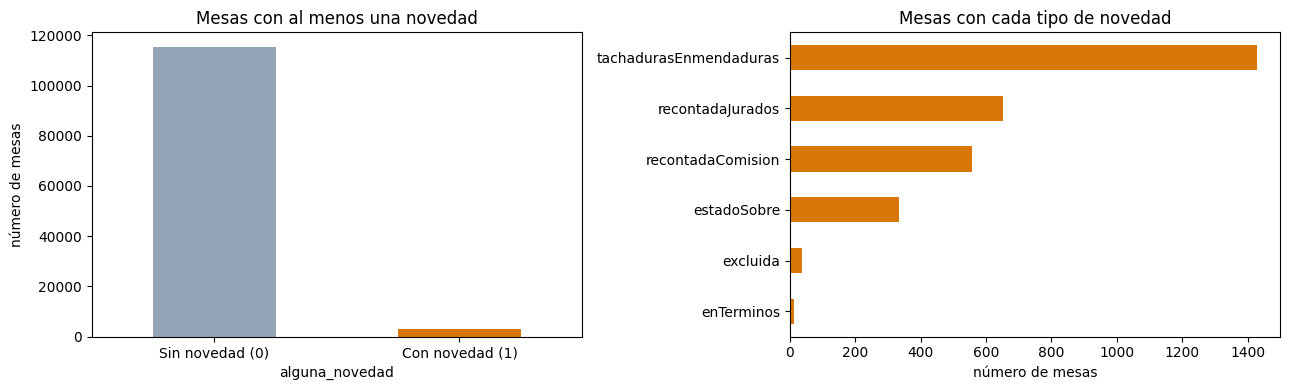

In [ ]:
NOVEDAD = {"enTerminos": "NO", "estadoSobre": "MAL", "tachadurasEnmendaduras": "SI",
           "recontadaJurados": "SI", "recontadaComision": "SI", "excluida": "SI"}

# Banderas convertidas a 0/1 (1 = hubo novedad)
nov_bin = pd.DataFrame({c: (noved[c] == v).astype(int) for c, v in NOVEDAD.items()})
nov_bin["alguna_novedad"] = nov_bin.max(axis=1)

balance = pd.DataFrame({"mesas con novedad": nov_bin.sum(),
                        "% de mesas": (nov_bin.mean() * 100).round(2)})
display(balance.sort_values("mesas con novedad", ascending=False))

sin = (nov_bin["alguna_novedad"] == 0).sum()
con = nov_bin["alguna_novedad"].sum()
print(f"Mesas sin novedad: {sin} | con al menos una: {con} | relación: {sin / con:.1f} a 1")
print("\nNúmero de novedades por mesa:")
print(nov_bin.drop(columns="alguna_novedad").sum(axis=1).value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
nov_bin["alguna_novedad"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#94A3B8", "#D97706"])
ax[0].set_xticklabels(["Sin novedad (0)", "Con novedad (1)"], rotation=0)
ax[0].set_title("Mesas con al menos una novedad")
ax[0].set_ylabel("número de mesas")
nov_bin.drop(columns="alguna_novedad").sum().sort_values().plot.barh(ax=ax[1], color="#D97706")
ax[1].set_title("Mesas con cada tipo de novedad")
ax[1].set_xlabel("número de mesas")
plt.tight_layout()
plt.show()

La etiqueta `alguna_novedad` presenta un **desbalance muy fuerte**: solo 2 898 de las 118 350 mesas (2,45 %) tienen al menos una novedad, frente a 115 452 sin ninguna, una relación de casi 40 a 1.

*Figura: mesas con y sin novedad, y número de mesas con cada tipo de novedad (elaboración propia).*

Como muestra la figura anterior, la clase positiva es muy pequeña, y dentro de ella las novedades tampoco se reparten de forma pareja: las tachaduras o enmendaduras (1 428 mesas) explican cerca de la mitad de los casos, mientras que la exclusión de la mesa (37) y la entrega fuera de términos (12) son casi inexistentes. Además, las novedades rara vez se combinan: 2 784 mesas tienen una sola, 106 tienen dos y apenas 8 tienen tres.

Este desbalance tiene consecuencias para el modelado:

- **La exactitud (*accuracy*) no sirve como métrica:** un modelo que siempre prediga "sin novedad" acertaría en el 97,6 % de las mesas sin haber aprendido nada. Se usarán precisión, sensibilidad (*recall*), F1 y PR-AUC.
- **El entrenamiento debe compensar el desbalance,** por ejemplo con pesos de clase, y las particiones deben conservar la proporción de positivos.
- **Las banderas con muy pocos casos** (exclusión y entrega fuera de términos) no son suficientes para modelarse por separado.

**¿El conjunto de datos cuenta con otras variables adicionales? De ser así, analice cuáles se incorporarán en el modelo y haga un análisis descriptivo de las mismas.**

,count,mean,std,min,25%,50%,75%,max
sufragantesSegunE11,118350.0,198.1,68.2,0.0,157.0,206.0,247.0,800.0
dif_urna_e11,118350.0,1.3,61.8,-499.0,0.0,0.0,0.0,8000.0
dif_e14_e11,118350.0,0.2,14.4,-323.0,0.0,0.0,0.0,2723.0
votosIncinerados,118350.0,0.1,3.3,0.0,0.0,0.0,0.0,360.0
firmasJurados,118350.0,5.9,0.4,0.0,6.0,6.0,6.0,6.0



% de mesas con valor distinto de 0:
dif_urna_e11        4.8
dif_e14_e11         1.0
votosIncinerados    1.8
dtype: float64

Mesas con votos incinerados: 2112 | incinerados = urna − E-11: 1323

Tipo de puesto según potencial:
potencial
360     117022
800        572
500        467
1200       289
Name: count, dtype: int64


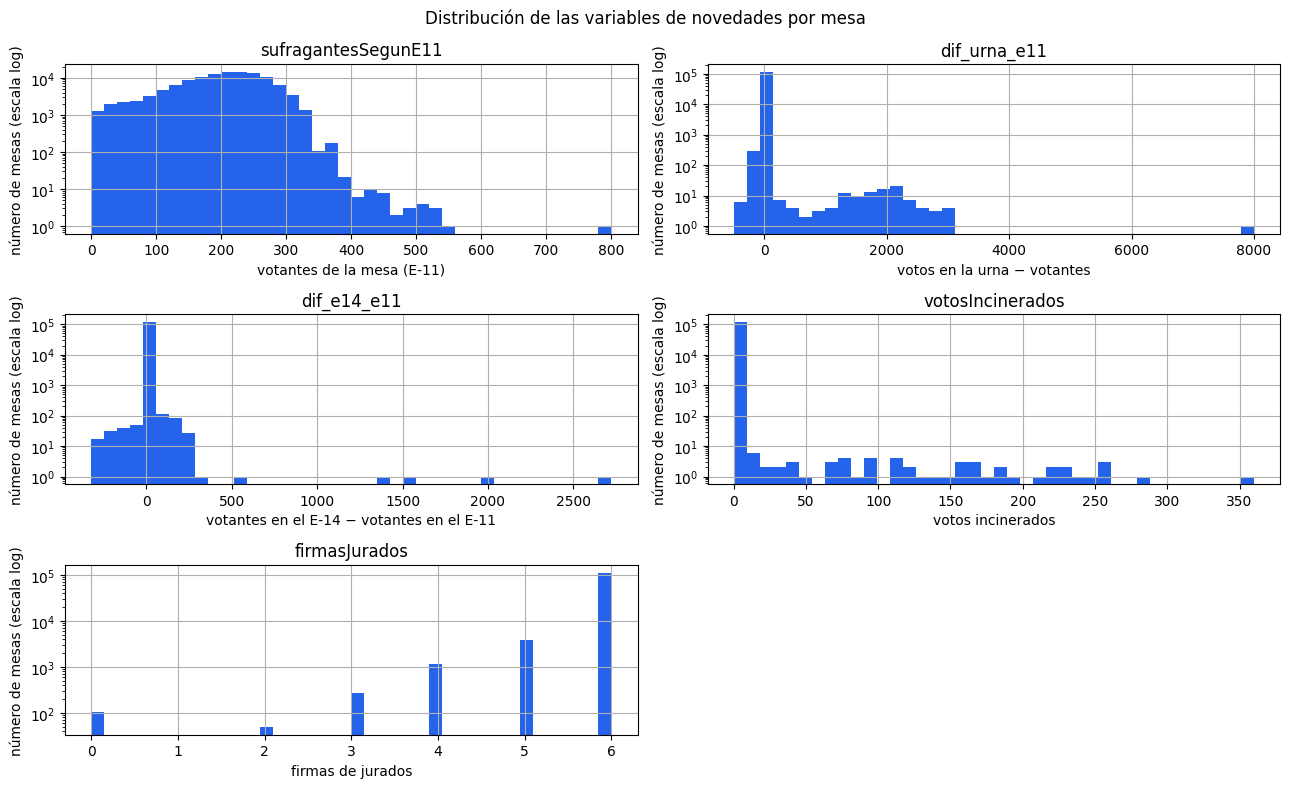

In [ ]:
nov_vars = pd.DataFrame({
    "sufragantesSegunE11": noved["sufragantesSegunE11"],
    "dif_urna_e11": noved["votosUrna"] - noved["sufragantesSegunE11"],
    "dif_e14_e11": noved["sufragantesE11SegunE14"] - noved["sufragantesSegunE11"],
    "votosIncinerados": noved["votosIncinerados"],
    "firmasJurados": noved["firmasJurados"],
})
display(nov_vars.describe().T.round(1))

print("\n% de mesas con valor distinto de 0:")
print((nov_vars[["dif_urna_e11", "dif_e14_e11", "votosIncinerados"]] != 0).mean().mul(100).round(1))

inc = noved["votosIncinerados"] > 0
print("\nMesas con votos incinerados:", inc.sum(), "| incinerados = urna − E-11:",
      (noved.loc[inc, "votosIncinerados"] == noved.loc[inc, "votosUrna"] - noved.loc[inc, "sufragantesSegunE11"]).sum())

print("\nTipo de puesto según potencial:")
print(noved["potencial"].value_counts())

ETIQUETAS_NOV = {
    "sufragantesSegunE11": "votantes de la mesa (E-11)",
    "dif_urna_e11": "votos en la urna − votantes",
    "dif_e14_e11": "votantes en el E-14 − votantes en el E-11",
    "votosIncinerados": "votos incinerados",
    "firmasJurados": "firmas de jurados",
}
ejes = nov_vars.hist(bins=40, figsize=(13, 8), color="#2563EB", log=True)
for ax in ejes.flatten():
    if ax.get_title() in ETIQUETAS_NOV:
        ax.set_xlabel(ETIQUETAS_NOV[ax.get_title()])
        ax.set_ylabel("número de mesas (escala log)")
plt.suptitle("Distribución de las variables de novedades por mesa")
plt.tight_layout()
plt.show()

Además de las banderas de novedad, el archivo tiene variables numéricas que describen cómo se desarrolló la votación en la mesa. La siguiente tabla resume cuáles se incorporarán al modelo:

| Variable | Tipo | ¿Se incorpora al modelo? |
|---|---|---|
| `sufragantesSegunE11` | Numérica discreta | **Sí.** Es la referencia del número de votantes, y será clave para compararlo con el preconteo, previa marca de los registros dudosos (pregunta 4 de la 1.2) |
| `votosUrna`, `sufragantesE11SegunE14` | Numéricas discretas | **Sí, como diferencias** con el E-11 (`dif_urna_e11`, `dif_e14_e11`), porque lo informativo es si coinciden o no |
| `votosIncinerados` | Numérica discreta | **Sí.** Indica una nivelación de la mesa (había más votos que votantes) |
| `firmasJurados` | Numérica discreta (0 a 6) | **Sí.** Una firma faltante es una debilidad del acta |
| `tachadurasEnmendaduras`, `recontadaJurados` | Categóricas binarias | **Sí, como entradas,** porque ocurren en la mesa, antes del preconteo |
| `estadoSobre`, `enTerminos`, `recontadaComision`, `excluida` | Categóricas binarias | **No como entradas:** ocurren durante el escrutinio (fuga de información) |
| `potencial` | Categórica (4 valores) | Solo como **tipo de puesto**, no como número de inscritos |
| `totalVotos` | Numérica discreta | **No:** es el resultado del escrutinio (fuga de información) |
| Códigos y nombres de la mesa, corporación, `id` | Identificadores o constantes | **No:** sirven para cruzar las fuentes |

*Figura: histogramas de las variables numéricas de novedades por mesa, con escala logarítmica en el eje vertical (elaboración propia).*

El análisis descriptivo muestra lo siguiente:

- **`sufragantesSegunE11`:** número de votantes de la mesa, con mediana de 206 y la mitad de las mesas entre 157 y 247. Su distribución es la misma que la del total de votos del escrutinio.
- **`dif_urna_e11` y `dif_e14_e11`:** en la gran mayoría de las mesas valen 0 (mediana 0), porque los conteos coinciden. Solo el 4,8 % y el 1,0 % de las mesas, respectivamente, tienen una diferencia. Los histogramas muestran un pico en 0 y colas a ambos lados; en la urna, la cola derecha llega hasta 8 000, el error de digitación ya identificado.
- **`votosIncinerados`:** casi siempre es 0; solo 2 112 mesas (1,8 %) incineraron votos sobrantes. En 1 323 de ellas, los votos incinerados son exactamente la diferencia entre la urna y los votantes, lo que coincide con el procedimiento de nivelación descrito en la sección de contexto.
- **`firmasJurados`:** casi todas las mesas tienen las 6 firmas; las demás se distribuyen en 5, 4, 3, 2 y 0 firmas.
- **`potencial`:** el 98,9 % de las mesas pertenece a puestos con un máximo de 360 votantes; el resto, a puestos con máximos de 500, 800 o 1 200. Se usará como categoría del tipo de puesto.

Las variables de diferencia y los votos incinerados tienen la misma característica que la etiqueta: la gran mayoría de las mesas vale 0. Por eso, en la Fase 3 podría ser más útil convertirlas en indicadores binarios (por ejemplo, "la urna no coincide con el E-11") que usarlas como valores continuos.

### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

**Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.**

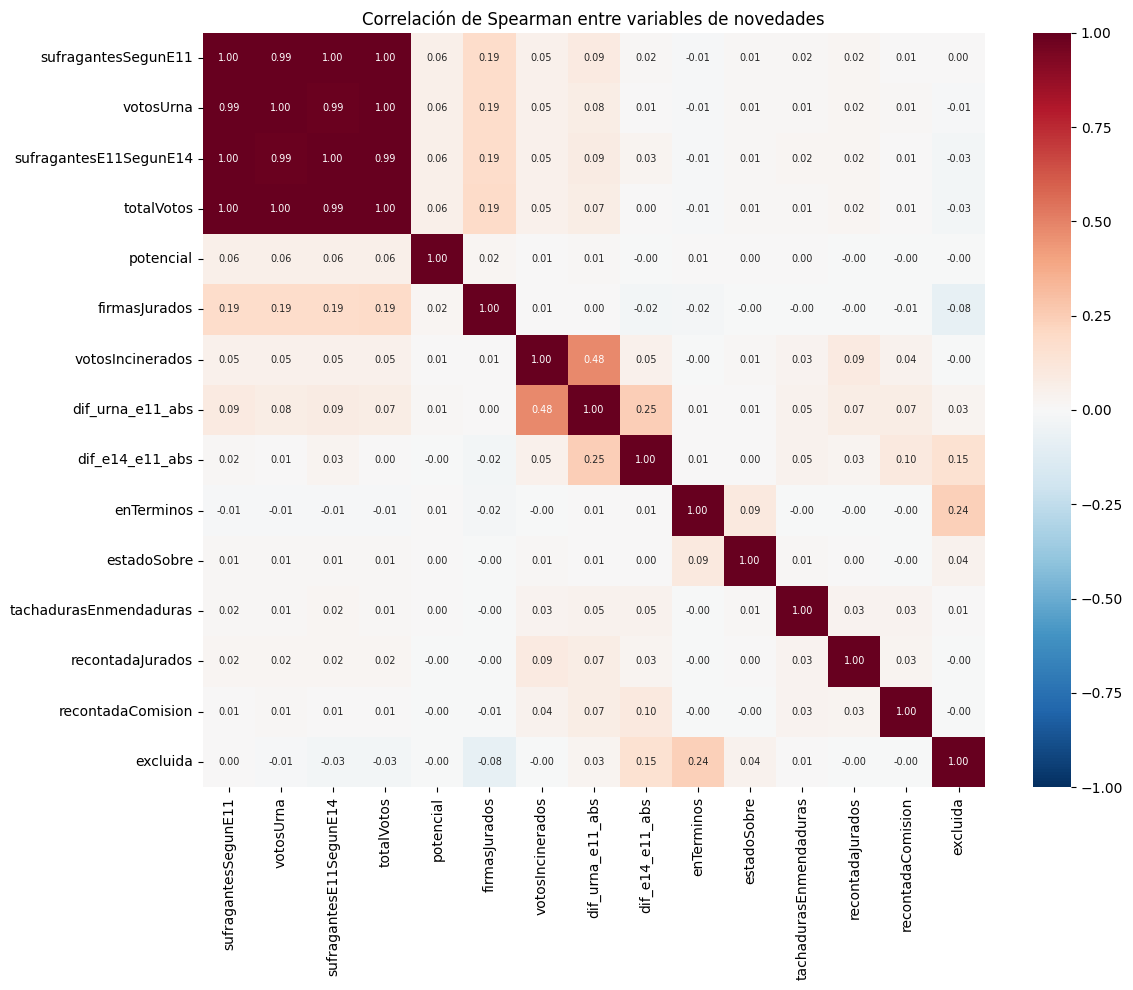

In [ ]:


nov_corr = pd.concat([
    noved[["sufragantesSegunE11", "votosUrna", "sufragantesE11SegunE14", "totalVotos",
           "potencial", "firmasJurados", "votosIncinerados"]],
    pd.DataFrame({
        "dif_urna_e11_abs": (noved["votosUrna"] - noved["sufragantesSegunE11"]).abs(),
        "dif_e14_e11_abs": (noved["sufragantesE11SegunE14"] - noved["sufragantesSegunE11"]).abs(),
    }),
    nov_bin.drop(columns="alguna_novedad"),
], axis=1)

corr_nov = nov_corr.corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr_nov, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlación de Spearman entre variables de novedades")
plt.tight_layout()
plt.show()

In [ ]:
base_urna = (nov_corr["dif_urna_e11_abs"] > 0).mean() * 100
base_firmas = (noved["firmasJurados"] < 6).mean() * 100

tabla_rel = pd.DataFrame({
    "% con urna ≠ votantes": {c: (nov_corr.loc[nov_bin[c] == 1, "dif_urna_e11_abs"] > 0).mean() * 100 for c in NOVEDAD},
    "% con menos de 6 firmas": {c: (noved.loc[nov_bin[c] == 1, "firmasJurados"] < 6).mean() * 100 for c in NOVEDAD},
}).round(1)
tabla_rel.loc["TODAS LAS MESAS"] = [round(base_urna, 1), round(base_firmas, 1)]
display(tabla_rel)

print("Firmas de las mesas excluidas:", noved.loc[noved["excluida"] == "SI", "firmasJurados"].value_counts().to_dict())
print("Mesas con 0 firmas:", (noved["firmasJurados"] == 0).sum(),
      "| de ellas, excluidas:", ((noved["firmasJurados"] == 0) & (noved["excluida"] == "SI")).sum())

,% con urna ≠ votantes,% con menos de 6 firmas
enTerminos,16.7,41.7
estadoSobre,6.9,6.3
tachadurasEnmendaduras,13.7,5.4
recontadaJurados,26.4,4.9
recontadaComision,26.9,6.3
excluida,37.8,100.0
TODAS LAS MESAS,4.8,4.6


Firmas de las mesas excluidas: {0: 37}
Mesas con 0 firmas: 104 | de ellas, excluidas: 37


Se usó la correlación de Spearman, igual que en el escrutinio. Para el análisis se agregaron las diferencias absolutas entre los votos en la urna y los votantes (`dif_urna_e11_abs`) y entre los votantes del E-14 y del E-11 (`dif_e14_e11_abs`), junto con las seis banderas de novedad convertidas a 0/1.

*Figura: matriz de correlación de Spearman entre las variables de novedades*

La figura anterior muestra tres patrones:

- **Los cuatro conteos de la mesa están casi perfectamente relacionados** (ρ entre 0,99 y 1,00): votantes del E-11, votos en la urna, votantes del E-14 y total de votos. Es esperable, porque en una mesa normal todos registran el mismo número.
- **Los votos incinerados se relacionan con la diferencia entre la urna y los votantes** (ρ = 0,48). Coincide con el procedimiento de nivelación: cuando hay más votos que votantes, los sobrantes se incineran.
- **Las banderas de novedad casi no se relacionan entre sí** (coeficientes cercanos a 0). Cada una registra un hecho distinto: por ejemplo, de las 651 mesas recontadas por los jurados, solo 20 fueron recontadas también por la comisión.

Sin embargo, la correlación subestima la relación de las banderas con las demás variables, porque cada novedad ocurre en menos del 1,3 % de las mesas. Por eso se compararon porcentajes en la tabla anterior. Mientras que en el total de mesas solo el 4,8 % tiene una urna que no coincide con los votantes, en las mesas recontadas por los jurados el porcentaje sube a 26,4 % y en las recontadas por la comisión a 26,9 %: más de cinco veces. Es decir, **las mesas con novedades tienen muchas más inconsistencias en sus conteos**, lo que respalda el uso de estas variables para identificar mesas que ameritan revisión.

La relación más fuerte es entre la exclusión y las firmas: **las 37 mesas excluidas tienen cero firmas de jurados**. Esto sugiere que la falta de firmas en el acta es una causa de exclusión de la mesa. Aun así, no toda acta sin firmas fue excluida: de las 104 mesas sin firmas, 67 no lo fueron.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*

## Referencias bibliográficas


Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. ACM Computing Surveys, 41(3), Article 15. https://doi.org/10.1145/1541880.1541882

Han, S., Hu, X., Huang, H., Jiang, M., & Zhao, Y. (2022). ADBench: Anomaly detection benchmark. Advances in Neural Information Processing Systems, 35. https://papers.neurips.cc/paper_files/paper/2022/hash/cf93972b116ca5268827d575f2cc226b-Abstract-Datasets_and_Benchmarks.html

Zhang, M., Alvarez, R. M., & Levin, I. (2019). Election forensics: Using machine learning and synthetic data for possible election anomaly detection. PLOS ONE, 14(10), Article e0223950. https://doi.org/10.1371/journal.pone.0223950


Constitución Política de Colombia [Const.]. (1991). Artículo 265. https://www.cne.gov.co/leyes-y-actos-legislativos-cne
Registraduría Nacional del Estado Civil. (s. f.). Cartilla de escrutinios. https://www.registraduria.gov.co/IMG/pdf/cartilla_escrutinios.pdf
Registraduría Nacional del Estado Civil. (2026). Estas son las diferencias entre los resultados de la transmisión y el escrutinio oficial. https://wapp.registraduria.gov.co/electoral/2026/presidente-de-la-republica/documentos/narrativas/diferencias_transmision_escrutinio.pdf

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*